# B6 · Explicabilité, équité et éthique — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b6_explicabilite/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B6.Q1 à B6.Q12, B6.R1 à B6.R3, B6.1, B6.3 à B6.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B6.12 | Explications globales sur California : coefficients, permutation, dépendance partielle et ICE | 📦 | ★★ | 30 |
|  | B6.13 | Prédire la forme des courbes ICE du revenu médian et de la latitude | 🔮 | ★ | 10 |
|  | B6.14 | shapley_values : Shapley exact par énumération des coalitions | 🔨 | ★★★ | 45 |
|  | B6.15 | SHAP sur un gradient boosting California : TreeExplainer, waterfall, beeswarm, dépendance | 📦 | ★★ | 30 |
|  | B6.16 | Le fond change tout : trois fonds différents, puis une feature dupliquée | 🔬 | ★★★ | 40 |
|  | B6.17 | Penguins : SHAP par classe pour une régression logistique et une forêt aléatoire | 📦 | ★★ | 25 |
| B | B6.18 | integrated_gradients et grad_cam | 🔨 | ★★ | 30 |
|  | B6.19 | Saillance, gradient × entrée et gradients intégrés sur un CNN CIFAR-10 | 📦 | ★★ | 30 |
|  | B6.20 | Grad-CAM par hooks sur le ResNet fine-tuné du B1 : bonnes prédictions et erreurs | 📦 | ★★★ | 45 |
| B | B6.21 et B6.22 | un Grad-CAM à réparer, le test de santé d'Adebayo (*prochaine session de génération*) | | | |
| C | B6.23 à B6.29 | l'équité : tes indicateurs par groupe, l'audit d'Adult avec intervalles, l'effet du retrait du sexe, l'atténuation et son coût, la fiche modèle et le défi (*prochaine session de génération*) | | | |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main des valeurs de Shapley exactes, des gradients intégrés et une carte Grad-CAM, et les relier à ta librairie (`explain.py`) et à shap.
- Expliquer un modèle tabulaire globalement (permutation, dépendance partielle, ICE) et localement (Shapley, waterfall), en disant quel fond a servi.
- Produire des cartes d'attribution sur un CNN et les soumettre à un test de santé.
- Auditer un classifieur groupe par groupe, avec des intervalles, essayer des corrections, chiffrer leur coût et documenter le tout dans une fiche modèle.

**Rappel express.** Shapley : $v(S) = \frac{1}{B}\sum_k f(\mathbf{x}_S, \mathbf{b}^{(k)}_{\bar S})$, $\phi_i = \sum_{S \not\ni i} \frac{|S|!\,(M - |S| - 1)!}{M!}\,[v(S \cup \{i\}) - v(S)]$, $\sum_i \phi_i = f(\mathbf{x}) - v(\varnothing)$ ; modèle linéaire : $\phi_i = w_i(x_i - \bar b_i)$. Gradients intégrés : $\operatorname{IG}_i = (x_i - x'_i)\int_0^1 \partial_i f(\mathbf{x}' + \alpha(\mathbf{x} - \mathbf{x}'))\,d\alpha$, de somme $f(\mathbf{x}) - f(\mathbf{x}')$. Grad-CAM : $\alpha_c$ = moyenne spatiale de $\partial y^k / \partial A^c$, carte $\operatorname{ReLU}(\sum_c \alpha_c A^c)$. Équité : $\Delta_{\text{DP}}$ = écart des taux de sélection, $\Delta_{\text{EO}}$ = le plus grand des écarts de TPR et de FPR ; $\operatorname{FPR} = \frac{p}{1-p}\cdot\frac{1 - \operatorname{PPV}}{\operatorname{PPV}}\cdot(1 - \operatorname{FNR})$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B6.1, B6.3, B6.4 et B6.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; un vecteur : une liste de nombres (`[0.5, -1.25]`). Un taux s'écrit comme une proportion (`0.25`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ B6.2 et B6.6, l'estimation 🧮 B6.7, la réflexion (🗣️ B6.8, ⚖️ B6.9 et B6.10, 📄 B6.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md). Features are numbered 1..M in
# the formulas, columns 0..M-1 in the code (feature 1 is column 0).
import itertools
import math

import numpy as np


def coalition_values(f, x, background):
    """v(S) for every mask S (a tuple of 0/1): the mean of f over the background rows where S takes x's values."""
    x, background = np.asarray(x, float), np.asarray(background, float)
    values = {}
    for mask in itertools.product((0, 1), repeat=len(x)):
        rows = background.copy()
        keep = np.array(mask, bool)
        rows[:, keep] = x[keep]
        values[mask] = float(np.mean(f(rows)))
    return values


def shapley_from_values(values, M, weight=None):
    """phi_i = sum over S without i of weight(|S|) (v(S + i) - v(S)); weight defaults to |S|! (M-|S|-1)! / M!."""
    weight = weight or (lambda k: math.factorial(k) * math.factorial(M - k - 1) / math.factorial(M))
    phi = []
    for i in range(M):
        total = 0.0
        for mask, value in values.items():
            if not mask[i]:
                with_i = tuple(1 if j == i else mask[j] for j in range(M))
                total += weight(sum(mask)) * (values[with_i] - value)
        phi.append(total)
    return phi


# ✏️ B6.1: f(x) = 2 x1 + x1 x3 + x2, x = (2, 1, 3), background (0, 2, 0) and (2, 2, 2)
F_B61 = lambda X: 2 * X[:, 0] + X[:, 0] * X[:, 2] + X[:, 1]
X_B61, BG_B61 = np.array([2.0, 1.0, 3.0]), np.array([[0.0, 2.0, 0.0], [2.0, 2.0, 2.0]])
V_B61 = coalition_values(F_B61, X_B61, BG_B61)
V0_B61, V1_B61, V13_B61 = V_B61[(0, 0, 0)], V_B61[(1, 0, 0)], V_B61[(1, 0, 1)]
W3_B61 = math.factorial(1) * math.factorial(1) / math.factorial(3)        # |S| = 1, M = 3
PHI_B61 = shapley_from_values(V_B61, 3)
FIRST_B61 = [V_B61[tuple(int(j == i) for j in range(3))] - V0_B61 for i in range(3)]   # contribution to the empty set
LAST_B61 = [V_B61[(1, 1, 1)] - V_B61[tuple(int(j != i) for j in range(3))] for i in range(3)]
EVALS_B61 = 2 ** 3 * len(BG_B61)
MEAN_ROW_B61 = BG_B61.mean(axis=0, keepdims=True)                          # (1, 2, 1)
PHI_MEAN_B61 = shapley_from_values(coalition_values(F_B61, X_B61, MEAN_ROW_B61), 3)
INTER_SHARE_B61 = [PHI_B61[0] - 2 * (X_B61[0] - BG_B61[:, 0].mean()), PHI_B61[2]]   # the share of x1 x3 in phi_1, phi_3

# ✏️ B6.3: f(x) = x1**2 + 3 x2 at x = (2, -1), zero baseline unless stated otherwise
X_B63 = np.array([2.0, -1.0])
F_B63 = lambda P: P[..., 0] ** 2 + 3 * P[..., 1]
GRAD_B63 = lambda P: np.stack([2 * P[..., 0], np.full(np.shape(P)[:-1], 3.0)], axis=-1)


def ig_rule_b63(n, method, x=X_B63, ref=(0.0, 0.0)):
    """Integrated gradients with n intervals (the conventions of the docstring of integrated_gradients)."""
    x, ref = np.asarray(x, float), np.asarray(ref, float)
    k = np.arange(n + 1) / n
    alphas = {"left": k[:-1], "right": k[1:], "midpoint": (np.arange(n) + 0.5) / n, "trapezoid": k}[method]
    weights = np.full(len(alphas), 1 / n)
    if method == "trapezoid":
        weights[[0, -1]] /= 2
    grads = GRAD_B63(ref + alphas[:, None] * (x - ref))
    return (x - ref) * (weights[:, None] * grads).sum(axis=0)


GRAD_AT_X_B63 = [float(g) for g in GRAD_B63(X_B63)]
GXI_B63 = [float(g) for g in GRAD_B63(X_B63) * X_B63]
GAP_B63 = float(F_B63(X_B63) - F_B63(np.zeros(2)))
IG_EXACT_B63 = [float(X_B63[0] ** 2), float(3 * X_B63[1])]                 # x1 * integral of 2 a x1 = x1**2 ; 3 x2
IG1_LEFT_B63, IG1_RIGHT_B63, IG1_TRAP_B63 = (float(ig_rule_b63(5, m)[0]) for m in ("left", "right", "trapezoid"))
N_LEFT_B63 = math.ceil(round(X_B63[0] ** 2 / 0.03, 9))                     # the left error of IG_1 is x1**2 / n
REF2_B63 = (1.0, 0.0)
IG1_REF2_B63 = float(X_B63[0] ** 2 - REF2_B63[0] ** 2)                     # (x1 - x1') (x1 + x1')
SUM_REF2_B63 = float(F_B63(X_B63) - F_B63(np.array(REF2_B63)))
CAPTUM_B63 = IG1_TRAP_B63 * 5 / 6                                          # 6 points, weights 1/6 halved at both ends

# ✏️ B6.4: two 3 x 3 channels (index 0 = channel 1)
A_B64 = np.array([[[1, 0, 0], [2, 1, 0], [3, 2, 1]], [[0, 1, 2], [0, 0, 1], [0, 0, 0]]], dtype=float)
G_B64 = np.array([[[0, 1, 2], [1, 1, 1], [2, 1, 0]], [[-1, -1, -1], [0, 0, 0], [-1, -0.5, 0]]], dtype=float)
ALPHA_B64 = G_B64.mean(axis=(1, 2))
RAW_B64 = np.tensordot(ALPHA_B64, A_B64, axes=1)                           # before the ReLU
CAM_B64 = np.maximum(RAW_B64, 0)
NORM_B64 = CAM_B64 / np.abs(CAM_B64).max()
TOPRIGHT_B64 = float(RAW_B64[0, 2])
ZEROS_B64 = int((CAM_B64 == 0).sum())
CENTER_B64 = float(NORM_B64[1, 1])
NORELU_TOPRIGHT_B64 = float(RAW_B64[0, 2] / np.abs(RAW_B64).max())
OTHER_B64 = np.tensordot(np.array([-0.5, 1.0]), A_B64, axes=1)             # class k': alpha' = (-0.5, 1)
CORNERS_B64 = {(0, 0): "A", (2, 0): "B", (0, 2): "C"}
MAX_B64 = CORNERS_B64[tuple(int(i) for i in np.unravel_index(np.argmax(CAM_B64), CAM_B64.shape))]
MAX_OTHER_B64 = CORNERS_B64[tuple(int(i) for i in np.unravel_index(np.argmax(OTHER_B64), OTHER_B64.shape))]
SHIFT_B64 = 72 / 3 / 2                                                     # half a layer pixel, in image pixels

# ✏️ B6.5: two groups (TP, FN, FP, TN)
COUNTS_B65 = {"F": (72, 48, 19, 361), "H": (256, 64, 40, 280)}


def rates_b65(tp, fn, fp, tn):
    n = tp + fn + fp + tn
    return {"base": (tp + fn) / n, "sel": (tp + fp) / n, "tpr": tp / (tp + fn), "fpr": fp / (fp + tn),
            "ppv": tp / (tp + fp), "acc": (tp + tn) / n}


R_B65 = {g: rates_b65(*c) for g, c in COUNTS_B65.items()}
DP_B65 = abs(R_B65["H"]["sel"] - R_B65["F"]["sel"])
TPR_GAP_B65 = abs(R_B65["H"]["tpr"] - R_B65["F"]["tpr"])
FPR_GAP_B65 = abs(R_B65["H"]["fpr"] - R_B65["F"]["fpr"])
EO_B65 = max(TPR_GAP_B65, FPR_GAP_B65)
RATIO_B65 = R_B65["F"]["sel"] / R_B65["H"]["sel"]
ACC_GAP_B65 = abs(R_B65["F"]["acc"] - R_B65["H"]["acc"])
POS_F_B65 = COUNTS_B65["F"][0] + COUNTS_B65["F"][1]
EXTRA_B65 = round(R_B65["H"]["tpr"] * POS_F_B65 - COUNTS_B65["F"][0])

# quizzes and recalls with a computation
Q1E = 2 ** 4
Q2E = 0.83 - float(np.mean([0.66, 0.62, 0.65, 0.63, 0.64]))
Q3C = 3 * 2 + float(np.mean(np.array([0, 1, 2]) ** 2))
Q4A = 0.72 - 0.40 - 0.15 - (-0.05)
Q4C = 0.3 + (-0.1)
Q4E = 2 ** (5 - 1)
Q5C, Q5D = 2 * (4 - 3), 2 * (4 - 5)
Q6A, Q6B = 2 * (1.5 - 0.5), 0 * (1.5 - 0.5)
Q7A = 0                                                     # min(x, 1) is flat beyond 1
Q7B = 3 * (1 / 3)                                           # (x - 0) * integral of f'(3 a): f' = 1 for a < 1/3
Q7C = 0                                                     # the path from 2 to 3 stays where f is flat
Q8A, Q8C = 160 // 32, 224 // 4
Q9E = 1 / 10
Q11A = 0.6 - 0.25                                           # a perfect classifier selects exactly the positives
Q11D = 0.5 / (1 - 0.5) * (1 - 0.8) / 0.8 * (1 - 0.2)        # Chouldechova
EPS_R1, X_R1, G_R1 = 0.03, np.array([0.40, 0.98, 0.10]), np.array([-0.7, 0.2, 0.0])
R1A = [float(v) for v in np.clip(X_R1 + EPS_R1 * np.sign(G_R1), 0, 1)]
R1D = 0.01 * 3072 * 0.01
R2E = round((0.88 - 0.86) * 400)
CM_R3 = np.array([[88, 12], [10, 40]])                      # rows: truth 0, 1 ; columns: prediction 0, 1
(TN_R3, FP_R3), (FN_R3, TP_R3) = CM_R3
R3A, R3B = TP_R3 / (TP_R3 + FN_R3), FP_R3 / (FP_R3 + TN_R3)
R3C, R3D = TP_R3 / (TP_R3 + FP_R3), (TP_R3 + FP_R3) / CM_R3.sum()

# The same answers from the libraries (no download): mylearn (reference), shap, scikit-learn and torchvision
E = mylearn.explain

# ✏️ B6.1: shapley_values, then shap's exact explainer with every background row
phi, base = E.shapley_values(F_B61, X_B61, BG_B61)
assert np.allclose(phi, PHI_B61) and math.isclose(base, V0_B61)
assert math.isclose(phi.sum() + base, float(F_B61(X_B61[None])[0]))       # efficiency
assert np.allclose(E.shapley_values(F_B61, X_B61, MEAN_ROW_B61)[0], PHI_MEAN_B61)
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by shap
try:
    import shap
except ImportError:
    print("ℹ️ shap is not installed: the comparison with shap.explainers.Exact is skipped")
else:
    exact = shap.explainers.Exact(F_B61, shap.maskers.Independent(BG_B61, max_samples=len(BG_B61)))(X_B61[None])
    assert np.allclose(exact.values[0], PHI_B61) and math.isclose(float(exact.base_values[0]), V0_B61)

# quiz Q4 to Q6: the linear models of the statements (phi_i = w_i (x_i - mean_i))
lin = lambda w: (lambda X: X @ np.asarray(w, float))
assert np.allclose(E.shapley_values(lin([2, -3]), [4.0, 1.0], [[3.0, 1.0]])[0], [Q5C, -3 * 0])
assert math.isclose(E.shapley_values(lin([2, -3]), [4.0, 1.0], [[4.0, 1.0], [6.0, 3.0]])[0][0], Q5D)
phi_a = E.shapley_values(lin([2, 2]), [1.5, 1.5], [[0.0, 0.0], [1.0, 1.0]])[0]
phi_b = E.shapley_values(lin([4, 0]), [1.5, 1.5], [[0.0, 0.0], [1.0, 1.0]])[0]
assert math.isclose(phi_a[0], Q6A) and math.isclose(phi_b[1], Q6B) and math.isclose(phi_a.sum(), phi_b.sum())
# ∂ B6.2, question 5 (an application, not checked by wb.check)
phi_d2, base_d2 = E.shapley_values(lambda X: 1 + X @ np.array([0.5, -2.0, 0.0]), [4.0, 1.0, 7.0],
                                   [[2.0, 0.0, 1.0], [4.0, 1.0, 5.0], [0.0, 2.0, 3.0]])
assert np.allclose(phi_d2, [1.0, 0.0, 0.0]) and math.isclose(base_d2, 0.0, abs_tol=1e-12)

# ✏️ B6.3: integrated_gradients with the rules of its docstring
ig = lambda **kw: E.integrated_gradients(GRAD_B63, X_B63, **kw)
for method, answer in (("left", IG1_LEFT_B63), ("right", IG1_RIGHT_B63), ("trapezoid", IG1_TRAP_B63)):
    assert math.isclose(ig(n_steps=5, method=method)[0], answer)
assert np.allclose(ig(n_steps=5, method="trapezoid"), IG_EXACT_B63)       # exact: the gradient is linear on the path
assert abs(GAP_B63 - ig(n_steps=N_LEFT_B63, method="left").sum()) <= 0.03 - 1e-4      # far from the edge (4/134)
assert abs(GAP_B63 - ig(n_steps=N_LEFT_B63 - 1, method="left").sum()) > 0.03 + 1e-5
assert np.allclose(ig(baseline=list(REF2_B63), n_steps=3), [IG1_REF2_B63, IG_EXACT_B63[1]])
assert math.isclose(ig(baseline=list(REF2_B63), n_steps=3).sum(), SUM_REF2_B63, abs_tol=1e-12)
alphas = np.linspace(0, 1, 6)                                             # captum's riemann_trapezoid, 6 points
weights = np.full(6, 1 / 6)
weights[[0, -1]] /= 2
assert math.isclose(X_B63[0] * float(weights @ GRAD_B63(alphas[:, None] * X_B63)[:, 0]), CAPTUM_B63)

# quiz Q7: min(x, 1) at x = 3 (its gradient: 1 below 1, 0 beyond)
grad_min = lambda P: (P < 1).astype(float)
assert math.isclose(float(E.integrated_gradients(grad_min, [3.0], n_steps=3000, method="midpoint")[0]), Q7B,
                    rel_tol=1e-3)
assert float(E.integrated_gradients(grad_min, [3.0], baseline=[2.0], n_steps=10)[0]) == Q7C

# ✏️ B6.4: grad_cam, with and without the ReLU
assert np.allclose(E.grad_cam(A_B64[None], G_B64[None])[0], NORM_B64)
assert math.isclose(float(E.grad_cam(A_B64[None], G_B64[None], relu=False)[0, 0, 2]), NORELU_TOPRIGHT_B64)
assert np.allclose(E.grad_cam(10 * A_B64[None], G_B64[None])[0], NORM_B64)
assert np.allclose(E.grad_cam(A_B64[None], 10 * G_B64[None])[0], NORM_B64)
assert np.allclose(E.grad_cam(A_B64[None], G_B64[None], relu=False, normalize=False)[0], RAW_B64)

# ✏️ B6.5: group_rates and the two gaps, from the labels rebuilt out of the counts
def labels_from_counts(counts):
    y_true, y_pred, groups = [], [], []
    for group, (tp, fn, fp, tn) in counts.items():
        for t, p, k in ((1, 1, tp), (1, 0, fn), (0, 1, fp), (0, 0, tn)):
            y_true += [t] * k
            y_pred += [p] * k
            groups += [group] * k
    return np.array(y_true), np.array(y_pred), np.array(groups)


y_true, y_pred, groups = labels_from_counts(COUNTS_B65)
rates = E.group_rates(y_true, y_pred, groups)
for g in ("F", "H"):
    for ours, theirs in (("base", "base_rate"), ("sel", "selection_rate"), ("tpr", "tpr"), ("fpr", "fpr"),
                         ("ppv", "precision"), ("acc", "accuracy")):
        assert math.isclose(rates[g][theirs], R_B65[g][ours])
assert math.isclose(E.demographic_parity_difference(y_pred, groups), DP_B65)
assert math.isclose(E.equalized_odds_difference(y_true, y_pred, groups), EO_B65)
from sklearn.metrics import confusion_matrix as sk_confusion_matrix

for g, (tp, fn, fp, tn) in COUNTS_B65.items():
    assert (sk_confusion_matrix(y_true[groups == g], y_pred[groups == g]) == [[tn, fp], [fn, tp]]).all()
for p_, ppv, fnr, fpr in ((R_B65[g]["base"], R_B65[g]["ppv"], 1 - R_B65[g]["tpr"], R_B65[g]["fpr"]) for g in "FH"):
    assert math.isclose(p_ / (1 - p_) * (1 - ppv) / ppv * (1 - fnr), fpr)    # ∂ B6.6, question 5

# recall R3: the confusion matrix of ch. 3 (the reference metrics.py) and scikit-learn
y3 = np.repeat([0, 0, 1, 1], [TN_R3, FP_R3, FN_R3, TP_R3])
p3 = np.repeat([0, 1, 0, 1], [TN_R3, FP_R3, FN_R3, TP_R3])
assert (np.asarray(mylearn.metrics.confusion_matrix(y3, p3)) == CM_R3).all()
assert (sk_confusion_matrix(y3, p3) == CM_R3).all()
r3 = E.group_rates(y3, p3, np.zeros(len(y3), int))[0]
assert math.isclose(r3["tpr"], R3A) and math.isclose(r3["fpr"], R3B) and math.isclose(r3["precision"], R3C)
assert math.isclose(r3["selection_rate"], R3D)

# quiz Q8: the sizes of the maps of an untrained ResNet-18 (no download)
try:
    import torch
    from torchvision.models import resnet18
except ImportError:
    print("ℹ️ torchvision is not installed: the sizes of quiz Q8 are not checked")
else:
    net, sizes = resnet18(weights=None).eval(), {}
    hooks = [getattr(net, name).register_forward_hook(lambda m, i, o, name=name: sizes.__setitem__(name, o.shape[-1]))
             for name in ("layer1", "layer4")]
    with torch.no_grad():
        net(torch.zeros(1, 3, 160, 160))
        assert sizes["layer4"] == Q8A
        net(torch.zeros(1, 3, 224, 224))
        assert sizes["layer1"] == Q8C
    for hook in hooks:
        hook.remove()
print("✅ the paper answers agree with mylearn (reference: explain, metrics), shap, scikit-learn and torchvision")

✅ the paper answers agree with mylearn (reference: explain, metrics), shap, scikit-learn and torchvision


**B6.Q1 — Interprétable par construction ou expliqué après coup ?**

In [3]:
wb.record("B6.Q1a", "B", mistakes={"relis « Interprétable par construction, ou expliqué après coup » (§206.1) : la forêt se lit-elle elle-même, ou faut-il TreeSHAP ?": "A", "une carte de saillance est-elle le modèle, ou une explication ajoutée ? Relis 206.1": "C"})
wb.record("B6.Q1b", False, mistakes={"relis la définition de l'explication post hoc (§206.1) : est-elle la règle du modèle ?": True})
wb.record("B6.Q1c", "A", mistakes={"Grad-CAM se contente-t-il des prédictions ? Relis la phrase sur les méthodes spécifiques (§206.1)": "B", "Grad-CAM change-t-il le modèle ? Relis « Interprétable par construction, ou expliqué après coup »": "C"})
wb.record("B6.Q1d", True, mistakes={"relis 206.1 : de quoi l'importance par permutation a-t-elle besoin ?": False})
wb.record("B6.Q1e", Q1E, mistakes={"c'est la profondeur : on demande le nombre de feuilles": 4,
          "c'est le nombre de nœuds internes : on demande les feuilles": 15,
          "c'est le nombre de feuilles d'un arbre de profondeur 3": 8,
          "c'est le nombre total de nœuds : on demande les feuilles": 31})

WB_ANSWER {"hash": "d307e0a097e391aa7798f9e9e626ad0f7125d4d07a0b655a4b5cfc854874ecfd", "id": "B6.Q1a", "kind": "str", "mistakes": {"aab24fcb0223aa17921f4001e524f48aaa4069357ee46ae56506ea678e5ce8ba": "une carte de saillance est-elle le modèle, ou une explication ajoutée ? Relis 206.1", "aba54b0fc3893e53492c55cdc2e8cfc819c20c47d41b369e195be2a32215377c": "relis « Interprétable par construction, ou expliqué après coup » (§206.1) : la forêt se lit-elle elle-même, ou faut-il TreeSHAP ?"}}
📝 Ex B6.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "888df880ca75b060eb3390fe7949b4d0338af128fdd5dc96142a769ce53bc394", "id": "B6.Q1b", "kind": "bool", "mistakes": {"d6ebe05f27bacb858c5a38d34d734fe71c2250e85dd36bd2b46eab873f6c80e2": "relis la définition de l'explication post hoc (§206.1) : est-elle la règle du modèle ?"}}
📝 Ex B6.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "077f54c8fb60d28dfffe255fc5dbf1cc6a015d7c29fd19c83da5cf603483cc64", "id": "B6.Q1c", "kind": "str", "mistakes": {"1aa58b

**B6.Q2 — Explication globale ou locale : quel outil répond à quelle question ?**

In [4]:
wb.record("B6.Q2a", "C", mistakes={"la question porte-t-elle sur tout le modèle ou sur un dossier ? Relis « Global ou local » (§206.1)": "A", "la question compare-t-elle des groupes ? Relis le tableau de « Global ou local »": "B"})
wb.record("B6.Q2b", "A", mistakes={"un waterfall explique combien de prédictions ? Relis le tableau de « Global ou local »": "B", "une courbe ICE d'un seul client dit-elle ce que le modèle utilise en tout ? Relis 206.2": "C"})
wb.record("B6.Q2c", False, mistakes={"relis la fin de « Global ou local » (§206.1) : une importance moyenne dit-elle tout d'un cas particulier ?": True})
wb.record("B6.Q2d", "B", mistakes={"une moyenne sur 1 000 clients explique-t-elle encore un client ? Relis la puce sur le beeswarm (§206.4)": "A", "la moyenne des |φ_i| mélange-t-elle une colonne ? Relis la puce sur le beeswarm (§206.4)": "C"})
wb.record("B6.Q2e", Q2E, decimals=2, mistakes={"c'est le score après mélange : l'importance est une baisse": 0.64,
          "fais la moyenne des cinq mélanges avant de soustraire": 0.83 - 0.66,
          "vérifie le sens de la soustraction": -Q2E})

WB_ANSWER {"hash": "987051d19ffe9e58c2c1215b10e88812cc7a6d2b7d4a619100d878d416b7fd28", "id": "B6.Q2a", "kind": "str", "mistakes": {"0ddcbf07a3d8ab2298113a0fc67151a4f0631fc713ab194f0e32d37de7b84aa3": "la question porte-t-elle sur tout le modèle ou sur un dossier ? Relis « Global ou local » (§206.1)", "21dc7ef786832d7c6c15ce5ef4b51274ad7480b2645ed2f777fd65393fd2900c": "la question compare-t-elle des groupes ? Relis le tableau de « Global ou local »"}}
📝 Ex B6.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "68308a003cc4a62b849548f141375c7c808076ac0a79370f59883963ddd60647", "id": "B6.Q2b", "kind": "str", "mistakes": {"1fc295f487388870b01a78c4ad6dae9c4bab6c775c2b7fb180d3aea7db493d7e": "une courbe ICE d'un seul client dit-elle ce que le modèle utilise en tout ? Relis 206.2", "21935d1d96b1f50c2a8bd7f67bf2d5726845597eda3efe5552053de0a2680d30": "un waterfall explique combien de prédictions ? Relis le tableau de « Global ou local »"}}
📝 Ex B6.Q2b : réponse enregistrée (str).
WB_ANSWER {"has

**B6.Q3 — Dépendance partielle et courbes ICE : ce que montre la moyenne, ce qu'elle cache**

In [5]:
wb.record("B6.Q3a", "C", mistakes={"fais la moyenne de v · x₂ sur tous les exemples : que vaut la moyenne de x₂ ?": "A", "relis la formule de PD_j(v) : on moyenne v · x₂ sur tous les exemples ; que vaut la moyenne de x₂ ?": "B"})
wb.record("B6.Q3b", 2, mistakes={"chaque exemple a sa courbe ICE : quelles pentes prennent-elles selon x₂ ?": 1,
          "une courbe ICE de ce modèle est une droite : combien de valeurs de x₂ donnent-elles des pentes différentes ?": 4})
wb.record("B6.Q3c", Q3C, decimals=2, mistakes={"tu as mis la moyenne de x₂ au carré : la dépendance partielle fait la moyenne des prédictions": 6 + 1.0,
          "relis la question : on impose v = 2 à x₁ ; n'oublie pas le terme x₂²": 6.0,
          "fais la moyenne de x₂² sur les trois valeurs, pas leur somme": 6 + 5.0})
wb.record("B6.Q3d", True, mistakes={"relis le paragraphe qui suit le code de 206.2 : que fait centered=True à chaque courbe ?": False})
wb.record("B6.Q3e", "A", mistakes={"relis la formule de PD_j(v) : sur quels exemples fait-on la moyenne ?": "B", "relis le piège classique « une dépendance partielle hors des données » (§206.2)": "C"})

WB_ANSWER {"hash": "b2c19e700fda3040689b8136cd689d0743c3e2869c886dbbd3165e42b319e582", "id": "B6.Q3a", "kind": "str", "mistakes": {"20f8338c9a62ffa334f6f81c30dc472c0f3d395650470834b4e3d77e9f1abe32": "relis la formule de PD_j(v) : on moyenne v · x₂ sur tous les exemples ; que vaut la moyenne de x₂ ?", "c5b1ddded7fda984795b86ac3d86b490d1b20fe5743081f46876fde8f4d23e76": "fais la moyenne de v · x₂ sur tous les exemples : que vaut la moyenne de x₂ ?"}}
📝 Ex B6.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "db095900c78223a3f157b58f86d65fce3780263c1f24ba4032623aed1dd0efb7", "id": "B6.Q3b", "kind": "int", "magnitude": 0, "mistakes": {"056e1a805897a185a32561f16071972160a81f1e02e0c7c15fc46f9e0b8dae97": "chaque exemple a sa courbe ICE : quelles pentes prennent-elles selon x₂ ?", "7a62308115ea6765c0321391f7e0edbae01a470a757fd877e03ab5b08e4602e6": "une courbe ICE de ce modèle est une droite : combien de valeurs de x₂ donnent-elles des pentes différentes ?"}, "sign": 1}
📝 Ex B6.Q3b : réponse e

**B6.Q4 — Les quatre propriétés de Shapley : efficacité, symétrie, joueur nul, additivité**

In [6]:
wb.record("B6.Q4a", Q4A, decimals=2, mistakes={"l'efficacité répartit f(x) moins la valeur de base, pas f(x)": 0.72 - 0.15 + 0.05,
          "vérifie le signe de φ₂ : il est négatif": 0.72 - 0.40 - 0.15 - 0.05,
          "c'est l'écart à répartir entre les trois features : retire les deux valeurs connues": 0.72 - 0.40})
wb.record("B6.Q4b", "A", mistakes={"l'efficacité porte sur la somme des parts : relis les quatre propriétés (§206.3)": "B", "la symétrie compare deux joueurs : relis les quatre propriétés (§206.3)": "C"})
wb.record("B6.Q4c", Q4C, decimals=1, mistakes={"relis l'additivité : les parts s'ajoutent, elles ne se moyennent pas": 0.1,
          "vérifie le signe de la part de h": 0.4})
wb.record("B6.Q4d", False, mistakes={"la symétrie exige que les deux joueurs apportent la même chose à toute coalition : avec x₁ = 1 et x₂ = 5, est-ce le cas ? Essaie f = x₁ + x₂": True})
wb.record("B6.Q4e", Q4E, mistakes={"c'est le nombre de toutes les coalitions : retire celles qui contiennent i": 32,
          "c'est le nombre d'ordres d'arrivée des cinq features": 120,
          "relis l'encadré 🧮 de 206.3 : un ensemble de m éléments a 2^m sous-ensembles": 5})

WB_ANSWER {"decimals": 2, "hash": "76e832763baf317b93f361f0ef891887d03136c2a06f02d8e0b0703b2cd78d08", "hash_coarse": "27cf2e8bc322a323c61c19a2b8d40b6628e5952a9f758a85c07a35178914222e", "id": "B6.Q4a", "kind": "float", "magnitude": -1, "mistakes": {"1267fec5f0661ff70dec900872dbc80acc913b48c019279c30a681fab8bb8b7f": "vérifie le signe de φ₂ : il est négatif", "30a1bc89e93871d22b6e6112761ec2be8f190da4bc3481f5c2b03d63e156ea5e": "c'est l'écart à répartir entre les trois features : retire les deux valeurs connues", "4bf4aa8d295086cc127848f9791c8e275c311a4717634a8a90c3bfd91f92ffd5": "l'efficacité répartit f(x) moins la valeur de base, pas f(x)"}, "sign": 1}
📝 Ex B6.Q4a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "d48253a44bdd2894d3199fa9cbf1350b0ac70a6e67d61a980788f2b519f884bd", "id": "B6.Q4b", "kind": "str", "mistakes": {"82ede411c6b75aac65b47f4fd8ea9ac486e8338e07e8bed5e5d7c83fe935e7f5": "l'efficacité porte sur la somme des parts : relis les quatre propriétés (§206.3)", "

**B6.Q5 — Changer le fond (background) change les valeurs SHAP : vrai ou faux**

In [7]:
wb.record("B6.Q5a", False, mistakes={"relis l'efficacité avec un fond (§206.3) : de quoi dépend la somme des φ_i ?": True})
wb.record("B6.Q5b", "C", mistakes={"relis la définition de la valeur de base (§206.3) : sur quelles lignes la moyenne est-elle prise ?": "A", "relis la définition de la valeur de base (§206.3) : v(∅) est-il nul ?": "B"})
wb.record("B6.Q5c", Q5C, mistakes={"vérifie le sens (x₁ moins la moyenne du fond) et le fond utilisé : le fond A": -Q5C,
          "n'oublie pas le coefficient w₁ = 2": 1})
wb.record("B6.Q5d", Q5D, mistakes={"vérifie le sens (x₁ moins la moyenne du fond) et le fond utilisé : le fond B": -Q5D,
          "n'oublie pas le coefficient w₁ = 2": -1})
wb.record("B6.Q5e", False, mistakes={"relis les deux modes de TreeExplainer (§206.4) : répondent-ils à la même question ?": True})
wb.record("B6.Q5f", 100, mistakes={"relis le paragraphe qui suit le code de shap (§206.3) : que fait max_samples par défaut ?": 300})

WB_ANSWER {"hash": "83937823056dccc30526dc397fb2b82798ff2d711b8e47ec366852b596f0e082", "id": "B6.Q5a", "kind": "bool", "mistakes": {"b94aae08d70594877ae1908eca7bec3b2e4aa9c4c9a25ebcada3b43ba78fa98e": "relis l'efficacité avec un fond (§206.3) : de quoi dépend la somme des φ_i ?"}}
📝 Ex B6.Q5a : réponse enregistrée (bool).
WB_ANSWER {"hash": "9a625fef37a247135a768dff5c8cc47f3c965dfa6e667193c9ace9038e655940", "id": "B6.Q5b", "kind": "str", "mistakes": {"82c5d6bf137a77b1dd0fdc1b8b45048c06ae6daf2e96d6a36c8e907067159867": "relis la définition de la valeur de base (§206.3) : sur quelles lignes la moyenne est-elle prise ?", "ad4797969c8d0003d2fc6a7e234be83da75e03d5e1829b5843d22ac57303fe0a": "relis la définition de la valeur de base (§206.3) : v(∅) est-il nul ?"}}
📝 Ex B6.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "f7329948bd7ec9075d4e1b6b563ae80a348a5abbfa5ef8c21cbb384c7e412c9e", "id": "B6.Q5c", "kind": "int", "magnitude": 0, "mistakes": {"1b66b189aecb1f1df91a7531f708b846a01803a002a1f

**B6.Q6 — Features corrélées : ce que SHAP répartit et ce qu'il ne dit pas**

In [8]:
wb.record("B6.Q6a", round(Q6A), mistakes={"relis le cas linéaire : φ₁ = w₁ (x₁ − moyenne), avec w₁ = 2": 4,
          "n'oublie pas de retirer la moyenne du fond": 3})
wb.record("B6.Q6b", round(Q6B), mistakes={"le modèle B lit-il x₂ ? Relis le cas linéaire": 2,
          "le modèle B lit-il x₂ ? Relis « Features corrélées : ce que SHAP répartit »": 4})
wb.record("B6.Q6c", True, mistakes={"calcule φ₁ + φ₂ pour les deux modèles, avec la formule du cas linéaire": False})
wb.record("B6.Q6d", "C", mistakes={"relis « Features corrélées : ce que SHAP répartit » : le Shapley observationnel est-il fidèle au modèle ou aux données ?": "A", "relis « Features corrélées : ce que SHAP répartit » : pour qui le Shapley observationnel a-t-il été conçu ?": "B"})
wb.record("B6.Q6e", "A", mistakes={"la plus grande des deux dépend du modèle choisi : relis la fin de « Features corrélées »": "B", "la répartition entre deux copies est-elle stable ? Relis la fin de « Features corrélées »": "C"})

WB_ANSWER {"hash": "164b90b2fa07b6e4b937d60f5f34eaddf9bfb77ac6f3b718fa86cb0610e61505", "id": "B6.Q6a", "kind": "int", "magnitude": 0, "mistakes": {"7a471a0b00af967f000fa31a86860d4ea8b9ff5cae7432c7ebc4da0829606f8a": "relis le cas linéaire : φ₁ = w₁ (x₁ − moyenne), avec w₁ = 2", "e8073e4d86670137e5bc1172f12ef54c28bc223f9624394f2254ca8b239d5d8b": "n'oublie pas de retirer la moyenne du fond"}, "sign": 1}
📝 Ex B6.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "2ac4feb0441c2a24c31d0d79b0367ed6dc8c040cff923ac4e5ab661defaac0b9", "id": "B6.Q6b", "kind": "int", "magnitude": null, "mistakes": {"9871a8c8caf5fd7516960e2a4168d5c0825d4fc5828a3c0a3abdbe6f3925213b": "le modèle B lit-il x₂ ? Relis « Features corrélées : ce que SHAP répartit »", "ba2f62670d10596b9043c96bbc2518509f8bea799b5d69743b5848c3684350c2": "le modèle B lit-il x₂ ? Relis le cas linéaire"}, "sign": 0}
📝 Ex B6.Q6b : réponse enregistrée (int).
WB_ANSWER {"hash": "f4ef9ddceac6c8d1c54d3fc2573f765d6792b52c61a7941937087835c9e638a4", "

**B6.Q7 — Gradient, gradient × entrée, gradients intégrés : pourquoi une ligne de référence ?**

In [9]:
wb.record("B6.Q7a", Q7A, mistakes={"au-delà de 1, f vaut toujours 1 : quelle est sa pente ?": 1,
          "relis la question : on demande la dérivée, pas la valeur de f": 3})
wb.record("B6.Q7b", round(Q7B), mistakes={"le gradient est nul en x, mais pas tout le long du chemin depuis 0 : relis la formule des gradients intégrés": 0,
          "c'est x − x′ : multiplie par la moyenne de la pente le long du chemin": 3})
wb.record("B6.Q7c", Q7C, mistakes={"le chemin va de 2 à 3 : quelle est la pente de f sur ce segment ?": 1,
          "relis la question : la référence a changé": 3})
wb.record("B6.Q7d", True, mistakes={"pour f = wᵀx, le gradient est le même en tout point : calcule les deux attributions": False})
wb.record("B6.Q7e", "A", mistakes={"un pixel égal à sa référence a-t-il un x_i − x′_i non nul ? Relis la formule des gradients intégrés": "B", "relis la formule des gradients intégrés : que vaut le facteur x_i − x′_i pour un pixel du fond ?": "C"})

WB_ANSWER {"hash": "073b012e8dfbf6570edb638cea2f28b08d566e57ca374504f067016b30200298", "id": "B6.Q7a", "kind": "int", "magnitude": null, "mistakes": {"c6867804ba0ffa1c1c56ba0c3d659373749d40c436a846642aff64e0a116765d": "relis la question : on demande la dérivée, pas la valeur de f", "f1513c5af6f865527a5c0c7e3623f713b550b5c41b8f21ee7b65b01cbd8b199e": "au-delà de 1, f vaut toujours 1 : quelle est sa pente ?"}, "sign": 0}
📝 Ex B6.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "b5e7baf49ceb0fe0d0506e299d91053d913171a46d33e985a2d4b7e234b29778", "id": "B6.Q7b", "kind": "int", "magnitude": 0, "mistakes": {"083d7c76afed677c2e6f106a8113cd9afe4b1032656769ba356f63a7e8f39865": "c'est x − x′ : multiplie par la moyenne de la pente le long du chemin", "bc3606b3a12a73cce6b9872878d2376cbb39acd4fc9bb945b41899e85e4d5fd1": "le gradient est nul en x, mais pas tout le long du chemin depuis 0 : relis la formule des gradients intégrés"}, "sign": 1}
📝 Ex B6.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash

**B6.Q8 — Grad-CAM : pourquoi la dernière couche convolutive ?**

In [10]:
wb.record("B6.Q8a", Q8A, mistakes={"c'est la taille de layer3, qui divise par 16 : relis les quatre détails de « Avec PyTorch : deux hooks »": 160 // 16,
          "c'est une division par 8 : de combien layer4 divise-t-il la taille de l'image ?": 160 // 8,
          "c'est la taille de layer1 : relis la question": 160 // 4})
wb.record("B6.Q8b", "B", mistakes={"relis « Pourquoi la dernière couche convolutive ? » (§206.6) : que vient-il après elle ?": "A", "une softmax rend un vecteur de probabilités, sans position : relis « Pourquoi la dernière couche convolutive ? »": "C"})
wb.record("B6.Q8c", Q8C, mistakes={"relis l'énoncé : layer1 divise par 4": 224 // 8,
          "c'est la taille de layer4 à 224 pixels : relis la question": 7,
          "relis l'énoncé : layer1 divise par 4, pas par 2": 112})
wb.record("B6.Q8d", True, mistakes={"un poids α_c peut-il être négatif ? Relis l'exemple à la main de 206.6": False})
wb.record("B6.Q8e", "C", mistakes={"relis la phrase qui suit la formule de Grad-CAM (§206.6) : de quel score prend-on le gradient ?": "A", "relis la phrase qui suit la formule de Grad-CAM (§206.6) : avant ou après la softmax ?": "B"})

WB_ANSWER {"hash": "ea16ef9493c4f7015cf90b8d7026b811cd61cdc929e6d1a1474cfb0bd72e49d2", "id": "B6.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"92e379ffd9d8af1e3380e9467076983130439688621498d834c514cff2970dd1": "c'est la taille de layer1 : relis la question", "b98232444f3d19733d2466b5dfc7ed767ad82bec659f5473964eb731b5a8d70b": "c'est une division par 8 : de combien layer4 divise-t-il la taille de l'image ?", "e220f71964d6826dc1379414d2c63e575138676a347afcd8f0742c6196566fc7": "c'est la taille de layer3, qui divise par 16 : relis les quatre détails de « Avec PyTorch : deux hooks »"}, "sign": 1}
📝 Ex B6.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "90ac7bc1ded65071349ef3e44a1b3fd83f0f7c76649b10222150e52f031d65a0", "id": "B6.Q8b", "kind": "str", "mistakes": {"116f2f8eb264adc0f3c97c79e22776571c79ecba21aa2f92b3ae9a8bff1c5531": "une softmax rend un vecteur de probabilités, sans position : relis « Pourquoi la dernière couche convolutive ? »", "ab91eb640cf4a7c1c11c9d27a5dbb879940bcb42

**B6.Q9 — Une carte de saillance qui ne dépend pas du modèle : que prouve le test de randomisation ?**

In [11]:
wb.record("B6.Q9a", "B", mistakes={"relis « Les tests de santé » (§206.7) : qu'exige-t-on d'une explication quand le modèle change ?": "A", "le test de randomisation mesure-t-il la robustesse aux attaques ? Relis 206.7": "C"})
wb.record("B6.Q9b", False, mistakes={"relis le paragraphe « Ce que prouve un test de santé réussi » (§206.7)": True})
wb.record("B6.Q9c", "C", mistakes={"c'est la randomisation indépendante : relis les deux variantes (§206.7)": "A", "c'est la randomisation des données : relis les deux tests (§206.7)": "B"})
wb.record("B6.Q9d", False, mistakes={"une corrélation de rangs compare l'ordre des pixels : deux cartes peuvent-elles avoir le même ordre et des valeurs différentes ?": True})
wb.record("B6.Q9e", Q9E, decimals=1, mistakes={"relis l'énoncé : CIFAR-10 a dix classes, et les labels du test ne sont pas mélangés": 0.5,
          "un réseau qui répond au hasard a-t-il une accuracy nulle ?": 0.0,
          "c'est l'accuracy d'entraînement d'un réseau qui apprend par cœur : relis la question, on demande le test": 1.0})

WB_ANSWER {"hash": "e1c36fb877bc0e08a330ab5827d8e1d84968583285016b96fa3c44333eb407e1", "id": "B6.Q9a", "kind": "str", "mistakes": {"21ea56fb3e0f78896e6529f5e263adfd55f673e6c1c36545075ba176773fe5cb": "le test de randomisation mesure-t-il la robustesse aux attaques ? Relis 206.7", "be221d27e2a843d29c32e665bf589a3e1e1375ed0c5d1ce9e2c2fbf1520dc216": "relis « Les tests de santé » (§206.7) : qu'exige-t-on d'une explication quand le modèle change ?"}}
📝 Ex B6.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "5c5a791c21648bc02a2ee4c6664f6a51442e2bfd72e7f9fbdccd7a5fa84d159c", "id": "B6.Q9b", "kind": "bool", "mistakes": {"5b58d67d76e93b32d6f101a2b4708be078806bf6447f4b910fde1404a37a6d8a": "relis le paragraphe « Ce que prouve un test de santé réussi » (§206.7)"}}
📝 Ex B6.Q9b : réponse enregistrée (bool).
WB_ANSWER {"hash": "f8fd2a56516a1b1021a213957a65eca3246c723b4e5858b2f877648e2bba12db", "id": "B6.Q9c", "kind": "str", "mistakes": {"44b864ea4d714828b68258bfedc3e7342c349372bbd37d8140dd437a09d3b

**B6.Q10 — Sources de biais : données, labels, variables de substitution, boucles de rétroaction**

In [12]:
wb.record("B6.Q10a", "A", mistakes={"les décisions du modèle fabriquent-elles ses données ? Relis les puces de « D'où vient un biais » (§206.8)": "B", "les transcriptions sont-elles fausses ? Relis les puces de « D'où vient un biais » (§206.8)": "C"})
wb.record("B6.Q10b", "B", mistakes={"la note des managers est-elle une feature ou la cible ? Relis 206.8": "A", "le modèle sert-il une autre population que celle de son évaluation ? Relis 206.8": "C"})
wb.record("B6.Q10c", "C", mistakes={"qui choisit les dossiers contrôlés ? Relis les puces de « D'où vient un biais »": "A", "une colonne porte-t-elle un attribut sensible à sa place ? Relis la question : qui choisit les contrôles ?": "B"})
wb.record("B6.Q10d", True, mistakes={"une colonne qui n'est pas le sexe peut-elle en porter une part de l'information ? Relis la puce sur les variables de substitution (§206.8)": False})
wb.record("B6.Q10e", "A", mistakes={"le modèle sert-il une autre population ? Relis les puces de 206.8 : qu'est-ce qui est mal mesuré ?": "B", "les décisions du modèle changent-elles le capteur ? Relis les puces de 206.8": "C"})

WB_ANSWER {"hash": "1c53b2cdf5b24fcd37720ce299fc427a9d5198375b0f23157e5c3c1fc5cb4d69", "id": "B6.Q10a", "kind": "str", "mistakes": {"bca4c37888c1e1cc4740410fcf08edb9501b628be68167012a2d73872abb7bf8": "les transcriptions sont-elles fausses ? Relis les puces de « D'où vient un biais » (§206.8)", "ebf36763d20b7a2295b5ef38cc74413458f6f005c0e3b03691237aed59c61886": "les décisions du modèle fabriquent-elles ses données ? Relis les puces de « D'où vient un biais » (§206.8)"}}
📝 Ex B6.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "3fb573d6edace8e9a5720ff43d249311f1dfa85171d738965224f469cfd00ca4", "id": "B6.Q10b", "kind": "str", "mistakes": {"07d439caa861990657a800f9bde6e60a73091da94540e3e6fea1dd0e5b11a761": "la note des managers est-elle une feature ou la cible ? Relis 206.8", "b381cf6bb3f0637e4c1fd43ac44a59e250e75590e2d91e9d4dd5945174f7dc9c": "le modèle sert-il une autre population que celle de son évaluation ? Relis 206.8"}}
📝 Ex B6.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash":

**B6.Q11 — Parité démographique, égalité des chances, calibration : peut-on tout avoir ?**

In [13]:
wb.record("B6.Q11a", Q11A, decimals=2, mistakes={"un classifieur parfait sélectionne-t-il tout le monde ? Son taux de sélection vaut le taux de base": 0.0,
          "relis la définition de Δ_DP : la différence des taux de sélection, pas leur rapport": 0.6 / 0.25})
wb.record("B6.Q11b", True, mistakes={"calcule le TPR et le FPR d'un classifieur parfait dans chaque groupe": False})
wb.record("B6.Q11c", True, mistakes={"calcule la precision d'un classifieur parfait dans chaque groupe": False})
wb.record("B6.Q11d", Q11D, decimals=2, mistakes={"relis la relation de Chouldechova : le dernier facteur est 1 − FNR": 0.5 / 0.5 * 0.25 * 0.2,
          "relis la relation : (1 − PPV) / PPV, pas PPV / (1 − PPV)": 0.5 / 0.5 * 4 * 0.8,
          "relis la relation : le premier facteur est p / (1 − p)": 0.5 * 0.25 * 0.8})
wb.record("B6.Q11e", "A", mistakes={"la parité démographique tient-elle compte de qui rembourserait ? Relis « Les critères » (§206.9)": "B", "un faux positif est ici un prêt accordé à qui ne rembourserait pas : est-ce l'erreur la plus coûteuse pour les demandeurs ?": "C"})

WB_ANSWER {"alt_coarse": ["4bfdd93a5db25683a6c6ef76d80c87a8e916819b2ece1a59cb217df8fa0e16a6"], "decimals": 2, "hash": "15e622ba2989402651cb3d364c6c13f65e02b673dce4a27ccb2a8ed2b1ee8f7d", "hash_coarse": "ffb415078ce75fe1764041e52a2a0819ce148291452f2e31467c65ecfadb6e58", "id": "B6.Q11a", "kind": "float", "magnitude": -1, "mistakes": {"46cf0e5cfbec76bb67259e14c9f162de7e425d2a3f437fff26624da7ca1da7f9": "un classifieur parfait sélectionne-t-il tout le monde ? Son taux de sélection vaut le taux de base", "5c631a6f1d297641a32ed1f2c8bdcf5f84cacd68a22c4382ff887cecb92f2b8b": "relis la définition de Δ_DP : la différence des taux de sélection, pas leur rapport"}, "sign": 1}
📝 Ex B6.Q11a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "a206040ccc70f897a12598003f328fe83247055de73fb05b44acecc2010a9f8b", "id": "B6.Q11b", "kind": "bool", "mistakes": {"27b3bff27f8ff9321bbc7de656b44719a251c93ebc61b3256395611e07f0f4b5": "calcule le TPR et le FPR d'un classifieur parfait dans chaque groupe"

**B6.Q12 — AI Act : dans quelle catégorie de risque tombe un scoring de crédit ?**

In [14]:
wb.record("B6.Q12a", "B", mistakes={"relis la puce « haut risque » de « L'AI Act » (§206.11) : que vise le point 5 b) ?": "A", "le scoring de crédit figure-t-il parmi les pratiques interdites ? Relis « L'AI Act » (§206.11)": "C"})
wb.record("B6.Q12b", "A", mistakes={"relis le point 5 b) cité en 206.11 : quelle exception contient-il ?": "B", "la détection de fraude figure-t-elle à l'article 5 ? Relis « L'AI Act »": "C"})
wb.record("B6.Q12c", "C", mistakes={"relis la puce « risque inacceptable » de « L'AI Act » (§206.11)": "A", "l'article 50 parle de transparence envers l'utilisateur : relis la puce « risque inacceptable »": "B"})
wb.record("B6.Q12d", False, mistakes={"relis l'encadré 🕰️ sur la régulation (§206.11) : quelles dates le règlement 2026/1744 a-t-il fixées ?": True})
wb.record("B6.Q12e", "B", mistakes={"relis le dernier paragraphe de « L'AI Act » : qui, du fournisseur ou du déployeur, réalise l'analyse d'impact ?": "A", "relis le dernier paragraphe de « L'AI Act » : l'article 27 s'adresse à qui ?": "C"})
wb.record("B6.Q12f", False, mistakes={"relis le texte du point 5 b) cité en 206.11 : de quelles personnes évalue-t-il la solvabilité ?": True})

WB_ANSWER {"hash": "e97b77884b2a335e11a55d033c9d53f2805eb3c6bcd4a71d5eb1494fe8aed0c8", "id": "B6.Q12a", "kind": "str", "mistakes": {"172a4c1802d2b21a8ea4aa71b3a943814141270caea477dd5b8942b8b66cc7b3": "le scoring de crédit figure-t-il parmi les pratiques interdites ? Relis « L'AI Act » (§206.11)", "23b5bb6f1541a005393a7f8f744b540358e757fb3943fa770ec3e44602728e7b": "relis la puce « haut risque » de « L'AI Act » (§206.11) : que vise le point 5 b) ?"}}
📝 Ex B6.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "c413ec9c2b1138c725b5db22eee74918c5c95d5baf16f427c715f6efa2537d88", "id": "B6.Q12b", "kind": "str", "mistakes": {"2728cb6cfe0649c54ec5cf5d66ffff069c3bf17f0af1527e4470dda14bc576ac": "relis le point 5 b) cité en 206.11 : quelle exception contient-il ?", "db24199bd13f6d873494dbcd676d55187709eb54630b3dd92243df812fc282ff": "la détection de fraude figure-t-elle à l'article 5 ? Relis « L'AI Act »"}}
📝 Ex B6.Q12b : réponse enregistrée (str).
WB_ANSWER {"hash": "dda00d3c2dfbb967f50f9057d67d

**B6.R1 — Visualiser ce qu'a appris un CNN, et l'attaque FGSM**

In [15]:
wb.record("B6.R1a", R1A, decimals=2, mistakes={"ramène chaque pixel dans [0, 1] après le pas": [0.37, 1.01, 0.1],
          "vérifie le signe : FGSM monte la loss, x + ε sign(∇L)": [0.43, 0.95, 0.1],
          "FGSM ajoute ε fois le signe du gradient, pas ε fois le gradient": [0.38, 0.99, 0.1],
          "le signe de 0 vaut 0 : le troisième pixel ne bouge pas": [0.37, 1.0, 0.13]})
wb.record("B6.R1b", True, mistakes={"relis le début de 206.5 et la section FGSM du ch. 21 : les deux calculs dérivent-ils par rapport à la même chose, avec la même passe arrière ?": False})
wb.record("B6.R1c", "B", mistakes={"relis le rappel maths « le gradient par rapport à l'entrée » du ch. 21 : les poids bougent-ils ?": "A", "la maximisation d'activation a-t-elle besoin de labels ? Relis le ch. 21": "C"})
wb.record("B6.R1d", R1D, decimals=2, mistakes={"relis la formule ε Σ|w_j| du ch. 21 : il manque un facteur": 0.01 * 0.01,
          "c'est ε fois le nombre de pixels : n'oublie pas |w_j|": 0.01 * 3072,
          "relis l'énoncé : ε = 0,01 et |w_j| = 0,01": 3.072})
wb.record("B6.R1e", False, mistakes={"relis le rappel maths du ch. 21 : la montée de gradient cherche-t-elle un minimum ?": True})

WB_ANSWER {"decimals": 2, "element_coarse": [["c0b85774ed5c4e847a92f87116e1f9c0b1baa654c62f3817119c440643c34d48"], ["63ed4448f93bb8b386f1686976b4b29e54e69e250da18279d41c84a1b2976c52"], ["ac1dac572f321071b666f23f720b75f7f214f62152cb05c006d19b77b70c5a1a"]], "element_hashes": ["bd3a6d3f8c5d2376459be79908fb3e07dcdf5ac2dd481ea6b8a3c5dda0e64487", "23df0cfdfb518ab4ce4ce752a5a4875480eb16b40aac95281c0bae92c675dba3", "bd81390edde7c131ffd78360c74dd015825da1b612e992c12f1818a8e30efc24"], "hash": "9863be79db9ae7084a2d9ab6679411a63be1e60ab7d5519359168408f02b0df3", "id": "B6.R1a", "kind": "array", "mistakes": {"25782b259235d052ea075f23ceaa0e8fbcded345133780117fa4c69be37cb564": "vérifie le signe : FGSM monte la loss, x + ε sign(∇L)", "45c2ef4b5494939e99d166c813bc5d6f1b0ce4e295788dda089767887dea1a3f": "ramène chaque pixel dans [0, 1] après le pas", "8eb6ffb01fa01460736963791fb0987ad23251303128ade45210909661b1e6b4": "le signe de 0 vaut 0 : le troisième pixel ne bouge pas", "d3137444c7ef50a6b3e75d7d2e89b1

**B6.R2 — feature_importances_ contre importance par permutation**

In [16]:
wb.record("B6.R2a", "A", mistakes={"relis l'importance des features au ch. 14 : qu'arrive-t-il aux features à forte cardinalité ?": "B", "une baisse d'impureté peut-elle être négative ? Relis le ch. 14": "C"})
wb.record("B6.R2b", True, mistakes={"relis le ch. 14 : sur quelles données l'importance MDI est-elle calculée ?": False})
wb.record("B6.R2c", 1, mistakes={"relis le ch. 14 : les importances MDI sont normalisées": 100})
wb.record("B6.R2d", "B", mistakes={"mélanger un identifiant fait-il perdre quelque chose sur des exemples jamais vus ? Relis le ch. 14": "A", "une importance par permutation fortement négative voudrait dire que le mélange aide beaucoup : est-ce plausible ?": "C"})
wb.record("B6.R2e", R2E, mistakes={"c'est la baisse d'accuracy : multiplie-la par le nombre d'exemples": 0,
          "vérifie l'ordre de grandeur : 2 points de 400 exemples": 80})

WB_ANSWER {"hash": "1e04cefd87cdae3468b2fd5dd0e7900b604686406f294808b7d0daab4a5a278b", "id": "B6.R2a", "kind": "str", "mistakes": {"d497dbfc691b90c2017409a972ea6c59bb885bc4f5db6a30d77c4ebb8c27bb15": "une baisse d'impureté peut-elle être négative ? Relis le ch. 14", "eeb8b46b7a2755cf169dafca8c7fa209c03ea1199fad5e24b7768f92dface7ec": "relis l'importance des features au ch. 14 : qu'arrive-t-il aux features à forte cardinalité ?"}}
📝 Ex B6.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "2a10c396a6b0cebe63a83863cb311850a37b1847f8703facdaf2d176d3b1cf31", "id": "B6.R2b", "kind": "bool", "mistakes": {"0c536f712973823907d97a1f7b2030cc69017b81d5a90282dc1a1b613acd8199": "relis le ch. 14 : sur quelles données l'importance MDI est-elle calculée ?"}}
📝 Ex B6.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "2e06fe06d2688aae53efcef0bbe89b9680ef720e445705f3f2a78e66a4ee0a89", "id": "B6.R2c", "kind": "int", "magnitude": 0, "mistakes": {"cda0c3fa689342cb1e6d1c30df833632b9c737328b8824291a629c41e4

**B6.R3 — TPR, FPR et precision à partir d'une matrice de confusion**

In [17]:
wb.record("B6.R3a", R3A, decimals=2, mistakes={"le TPR divise TP par les positifs réels (la ligne 1), pas par les sélectionnés": R3C,
          "le TPR divise par les positifs réels, pas par tous les exemples": 40 / 150})
wb.record("B6.R3b", R3B, decimals=2, mistakes={"c'est la part de faux positifs parmi les sélectionnés : le FPR divise par les négatifs réels": 12 / 52,
          "relis la disposition : la case [0, 1] contient quoi ?": 10 / 50,
          "le FPR divise par les négatifs réels, pas par tous les exemples": 12 / 150})
wb.record("B6.R3c", R3C, decimals=3, mistakes={"la precision divise TP par les sélectionnés (la colonne 1), pas par les positifs réels": R3A,
          "c'est la part de faux positifs parmi les sélectionnés : on demande la part de vrais positifs": 12 / 52})
wb.record("B6.R3d", R3D, decimals=3, mistakes={"c'est la part de positifs réels (la ligne 1) : on demande la part de prédictions positives": 50 / 150,
          "le taux de sélection divise par tous les exemples, pas par les négatifs réels": 52 / 100})
wb.record("B6.R3e", "A", mistakes={"relis la disposition : la ligne 0 est la vérité 0, la colonne 1 la prédiction 1": "B", "relis la disposition : la ligne 0 est la vérité 0": "C"})

WB_ANSWER {"decimals": 2, "hash": "cd85fa2c3af82613f6d2ce7f2f5635f8f05670c646dfa5415536020ae41d9468", "hash_coarse": "e82a7e7a8e620c5e1eb09052937601f2399c5ceb221a2e97b91b050a2309da98", "id": "B6.R3a", "kind": "float", "magnitude": -1, "mistakes": {"857292a4a0e75bade5e8143c630a47a0a70d5500cf192a11c62aaeb2a6ddb2df": "le TPR divise TP par les positifs réels (la ligne 1), pas par les sélectionnés", "b369d8cddb255e82855649cd540058f3f5b2211a31b875cbc330cf61a8440ace": "le TPR divise par les positifs réels, pas par tous les exemples"}, "sign": 1}
📝 Ex B6.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "b791dd0c4df9b6a1288c50a6c5ba8168b9789dc34fefb46b0beea231cc5c9800", "hash_coarse": "8bd62e18b8f3459e2ad6bd3d5d2740cffc66cbc99f0ff28e742eb65da385043d", "id": "B6.R3b", "kind": "float", "magnitude": -1, "mistakes": {"5b321aad69e7c89faaa16efb93b32ed7b5a16f2e33559aa6fd08ec5878318ecc": "c'est la part de faux positifs parmi les sélectionnés : le FPR divise par les né

**Ex B6.1 — Valeurs de Shapley exactes à la main : trois features, huit coalitions**

In [18]:
wb.record("B6.1a", round(V0_B61), mistakes={"tu as calculé f sur la ligne moyenne du fond : v(∅) est la moyenne de f sur les deux lignes": 5,
          "relis la question : v(∅) n'a aucune feature du client": 11,
          "tu as additionné les deux lignes : v(S) est une moyenne": 12})
wb.record("B6.1b", round(V1_B61), mistakes={"dans v({1}), seule la feature 1 vient du client : as-tu inversé le masque ?": round(V_B61[(0, 1, 1)]),
          "tu as additionné les deux lignes : v(S) est une moyenne": 16,
          "relis la question : v({1}) garde x₂ et x₃ du fond": 11})
wb.record("B6.1c", round(V13_B61), mistakes={"dans v({1, 3}), les features 1 et 3 viennent du client : as-tu inversé le masque ?": round(V_B61[(0, 1, 0)]),
          "tu as additionné les deux lignes : v(S) est une moyenne": 24})
wb.record("B6.1d", W3_B61, decimals=2, mistakes={"c'est le poids des coalitions de taille 0 ou 2 : {3} a un membre": 1 / 3,
          "les poids ne sont pas uniformes sur les quatre coalitions sans la feature 1 : relis la formule": 1 / 4,
          "les poids ne sont pas uniformes sur les huit coalitions : relis la formule": 1 / 8})
wb.record("B6.1e", PHI_B61[0], decimals=1, mistakes={"tu n'as gardé que l'apport de la feature 1 à la coalition vide (ou le seul terme 2x₁) : il y a quatre coalitions sans elle": FIRST_B61[0],
          "tu n'as gardé que son apport quand elle arrive la dernière : il y a quatre coalitions sans elle": LAST_B61[0]})
wb.record("B6.1f", round(PHI_B61[1]), mistakes={"vérifie le signe : x₂ est plus petit que ses valeurs du fond": 1,
          "x₂ entre dans f : un joueur nul n'apporte jamais rien, est-ce le cas ?": 0})
wb.record("B6.1g", PHI_B61[2], decimals=1, mistakes={"tu n'as gardé que l'apport de la feature 3 à la coalition vide": FIRST_B61[2],
          "tu n'as gardé que son apport quand elle arrive la dernière": LAST_B61[2],
          "as-tu pris pour valeur de base f sur la ligne moyenne du fond ? Relis a)": PHI_B61[2] + 1})
wb.record("B6.1h", False, mistakes={"calcule ce que l'interaction apporte à φ₁ (retire le terme 2(x₁ − moyenne)) et compare à φ₃": True})
wb.record("B6.1i", EVALS_B61, mistakes={"chaque v(S) demande une évaluation par ligne du fond : il y en a deux": 8,
          "chaque v(S) se calcule une fois et sert aux trois features": 3 * EVALS_B61,
          "compte toutes les coalitions, la vide et la pleine comprises": 6 * 2,
          "la coalition pleine se calcule aussi sur les deux lignes du fond, comme les autres": EVALS_B61 - 1})
wb.record("B6.1j", PHI_MEAN_B61[0], decimals=1, mistakes={"relis la question : le fond n'a plus qu'une ligne, recalcule les v(S)": 3.5,
          "tu n'as gardé que le terme 2x₁ : la feature 1 entre aussi dans l'interaction": 2.0})
wb.record("B6.1k", "B", mistakes={"relis l'encadré 📐 de la fiche : la feature 1 est la colonne 0": "A", "relis la signature de shapley_values : que rend-elle à part phi ?": "C"})

WB_ANSWER {"hash": "f58d4b2bc337b00439d9b22391ae3b71a395b9f5006dbd1676c27608765eeb6f", "id": "B6.1a", "kind": "int", "magnitude": 0, "mistakes": {"5e1a405ae8f3d5bc5642289c032237d994a27332480bb45a6203ba4565e3e446": "tu as calculé f sur la ligne moyenne du fond : v(∅) est la moyenne de f sur les deux lignes", "6af629807b890022e94ab62b31582de3b3f748726aa692f61487f1ed08647f6e": "relis la question : v(∅) n'a aucune feature du client", "f11a358b26539e304a5fd18e14f02bb35fce96f9c0fe30d93ba952cf6d01de2b": "tu as additionné les deux lignes : v(S) est une moyenne"}, "sign": 1}
📝 Ex B6.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "ce32d6a7efeee5480b7e73730b89d8f4cba2f9aa82955a4beecf43058631b58a", "id": "B6.1b", "kind": "int", "magnitude": 0, "mistakes": {"484ec8905ec483b6d9d60fdb296e044512ac04682c546b479a4bedce7eee0d35": "relis la question : v({1}) garde x₂ et x₃ du fond", "7988c915d55a3af63871c4cf097318c3732cdf84afde8cde0214f1ce9c2d7809": "dans v({1}), seule la feature 1 vient du client : a

**Ex B6.3 — Gradients intégrés à la main sur f(x) = x₁² + 3x₂ et vérification de la complétude**

In [19]:
wb.record("B6.3a", GRAD_AT_X_B63, decimals=1, mistakes={"la dérivée de x₁² est 2x₁": [2.0, 3.0],
          "la dérivée de 3x₂ par rapport à x₂ ne dépend pas de x₂": [4.0, -3.0]})
wb.record("B6.3b", GXI_B63, decimals=1, mistakes={"multiplie chaque dérivée par la valeur de sa feature": GRAD_AT_X_B63,
          "vérifie le signe : x₂ = −1": [8.0, 3.0]})
wb.record("B6.3c", round(GAP_B63), mistakes={"c'est la somme de gradient × entrée : on demande l'écart de prédiction f(x) − f(x′)": 5,
          "vérifie le signe de 3x₂ : x₂ = −1": 7,
          "vérifie le sens de la soustraction : f(x) − f(x′)": -1})
wb.record("B6.3d", IG_EXACT_B63, decimals=1, mistakes={"c'est gradient × entrée : intègre la dérivée le long du chemin": GXI_B63,
          "multiplie l'intégrale par x_i − x′_i": [2.0, 3.0],
          "vérifie le signe de la seconde attribution : x₂ = −1": [4.0, 3.0]})
wb.record("B6.3e", IG1_LEFT_B63, decimals=1, mistakes={"c'est la règle 'right' : 'left' prend les points k/n pour k = 0 à n − 1": IG1_RIGHT_B63,
          "multiplie la moyenne des gradients par x₁ − x′₁": IG1_LEFT_B63 / 2,
          "n = 5 intervalles : les points 0 ; 0,2 ; 0,4 ; 0,6 ; 0,8": float(ig_rule_b63(4, "left")[0]),
          "relis la question : la règle de gauche, avec n = 5": 4.0})
wb.record("B6.3f", IG1_RIGHT_B63, decimals=1, mistakes={"c'est la règle 'left' : 'right' prend les points k/n pour k = 1 à n": IG1_LEFT_B63,
          "multiplie la moyenne des gradients par x₁ − x′₁": IG1_RIGHT_B63 / 2,
          "relis la question : la règle de droite, avec n = 5": 4.0})
wb.record("B6.3g", IG1_TRAP_B63, decimals=1, mistakes={"relis la question : la règle des trapèzes, dont les deux extrémités comptent pour moitié": 4.8,
          "multiplie la somme pondérée par x₁ − x′₁": 2.0,
          "les poids valent 1/n, divisés par deux aux extrémités : relis l'énoncé": 2 * (0 + 0.8 + 1.6 + 2.4 + 3.2 + 2) / 6})
wb.record("B6.3h", N_LEFT_B63, mistakes={"avec ce n, l'erreur dépasse encore un peu 0,03 : prends le plus petit entier qui convient": N_LEFT_B63 - 1,
          "l'erreur de la règle de gauche sur IG₁ dépend de x₁² : recalcule-la": 34,
          "recalcule l'erreur de la règle de gauche en fonction de n : où intervient x₁ ?": 67},
          fractional="le nombre d'intervalles est entier : prends le plus petit n qui convient")
wb.record("B6.3i", round(IG1_REF2_B63), mistakes={"relis la question : la référence a changé ; un gradient pris en x seul ne suffit pas non plus": 4,
          "le chemin part de x′ : son point est x′ + α(x − x′)": 2})
wb.record("B6.3j", round(SUM_REF2_B63), mistakes={"relis la question : avec cette référence, la somme vaut f(x) − f(x′)": 1,
          "relis la question : on demande la somme des deux attributions": 3,
          "c'est la seconde attribution seule : ajoute IG₁": -3})
wb.record("B6.3k", CAPTUM_B63, decimals=2, mistakes={"c'est le trapèze de ta docstring : relis l'encadré 🕰️ de 206.6 sur captum": 4.0,
          "le facteur est n/(n + 1), pas (n + 1)/n : relis l'encadré 🕰️ de 206.6": 4.8,
          "6 points font 5 intervalles, pas 6 : relis l'énoncé": 4 * 6 / 7})
wb.record("B6.3l", "C", mistakes={"n_steps compte les intervalles dans ta librairie, pas les points": "A", "relis la question : e) utilise la règle 'left'": "B"})

WB_ANSWER {"decimals": 1, "element_hashes": ["7542e16b37ec52198a1423281a3dd748dfa524dd1afe31e397eae15313414a59", "54573c89c85d45da89c20e57e05f95a0f7facca3c13c3a97ac6cd5493050b8b1"], "hash": "013c2532476dde14890d3533cfa53c5b745457c954a0df8bf988d4ebaa249ba4", "id": "B6.3a", "kind": "array", "mistakes": {"7e410381a4b1dd7502dff2894e08a1e3e63b75f3d08205928f85500fabd044cb": "la dérivée de 3x₂ par rapport à x₂ ne dépend pas de x₂", "bc5b5c34c77e781f43caeeffed1e557a25997dbd395bde4887f1fd60c7f972c9": "la dérivée de x₁² est 2x₁"}, "shape": [2]}
📝 Ex B6.3a : réponse enregistrée (array, 1 décimale(s)).
WB_ANSWER {"decimals": 1, "element_hashes": ["f8a102ac9cf6dddde00f12656f771eb73e0fa5e958bbb960dbc46453722508f6", "a3d7b2e456e0696602b406d7ba635bd5ab92c6aa5d08fa867bfcd5a48d501c01"], "hash": "676f37d19116d6a7aebb0235a37d2c3f801a96c7281582be4689a505ed0a4879", "id": "B6.3b", "kind": "array", "mistakes": {"605a4f94dd9a8193f06fa46ecc5ab515eb270d041ad670e144d92b974662943c": "vérifie le signe : x₂ = −1", "

**Ex B6.4 — Grad-CAM à la main : deux cartes 3×3 et leurs gradients**

In [20]:
wb.record("B6.4a", float(ALPHA_B64[0]), decimals=1, mistakes={"α_c est la moyenne des gradients, pas leur somme": float(G_B64[0].sum()),
          "α_c est la moyenne des gradients seuls, sans les multiplier par les activations": float((G_B64[0] * A_B64[0]).mean())})
wb.record("B6.4b", float(ALPHA_B64[1]), decimals=1, mistakes={"α_c est la moyenne des gradients, pas leur somme": float(G_B64[1].sum()),
          "vérifie le signe : les gradients du canal 2 sont négatifs ou nuls": -float(ALPHA_B64[1]),
          "α_c est la moyenne des gradients seuls, sans les multiplier par les activations": float((G_B64[1] * A_B64[1]).mean())})
wb.record("B6.4c", TOPRIGHT_B64, decimals=1, mistakes={"relis la question : avant le ReLU": 0.0,
          "vérifie le signe de α₂": -TOPRIGHT_B64,
          "relis la case : en haut à droite, A¹ vaut 0 et A² vaut 2": -0.5})
wb.record("B6.4d", ZEROS_B64, mistakes={"compte aussi les cases dont la somme pondérée est négative mais proche de 0": 2,
          "une case positive n'est pas mise à 0 : compte les cases négatives de la somme pondérée": 4})
wb.record("B6.4e", CENTER_B64, decimals=2, mistakes={"n'oublie pas de diviser par la plus grande valeur de la carte": 1.0,
          "on divise par la plus grande valeur absolue, pas par la somme de la carte": float(CAM_B64[1, 1] / CAM_B64.sum())})
wb.record("B6.4f", "B", mistakes={"cherche la plus grande valeur de α₁A¹ + α₂A² après le ReLU": "A", "en haut à droite, quel est le signe de la somme pondérée ?": "C"})
wb.record("B6.4g", NORELU_TOPRIGHT_B64, decimals=2, mistakes={"sans le ReLU, la case garde son signe": -NORELU_TOPRIGHT_B64,
          "n'oublie pas de diviser par la plus grande valeur absolue": TOPRIGHT_B64,
          "relis la question : sans le ReLU, la case n'est pas mise à 0": 0.0})
wb.record("B6.4h", "C", mistakes={"calcule −0,5 A¹ + A² case par case : que vaut-elle en haut à gauche ?": "A", "calcule −0,5 A¹ + A² case par case : que vaut-elle en bas à gauche ?": "B"})
wb.record("B6.4i", False, mistakes={"multiplier les activations par 10 multiplie toute la somme pondérée : que fait la division par le maximum ?": True})
wb.record("B6.4j", round(SHIFT_B64), mistakes={"c'est la taille d'un pixel de la couche : on demande un demi-pixel": 24,
          "relis l'énoncé : la carte fait 3 × 3 et l'image 72 × 72": 36})

WB_ANSWER {"decimals": 1, "hash": "d5d3424fe18930e6f715254358fdd8f8bb5408345f451e0b333a105545c87b99", "hash_coarse": "92d3c0901681b8b530c7163fa4fc78b5bae40122489b167bc401c0e8001a722b", "id": "B6.4a", "kind": "float", "magnitude": 0, "mistakes": {"0d1ca3a40e34fed6f4e45d20f6dbd680079a1a35b16e8dd115cda68042f59116": "α_c est la moyenne des gradients, pas leur somme", "cf972a8a744fac3f3466f2645ad1b9ea130ce4f7263050e37b761a9d10328e81": "α_c est la moyenne des gradients seuls, sans les multiplier par les activations"}, "sign": 1}
📝 Ex B6.4a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"alt_coarse": ["61e491c54dcc27b3e31caf91bb1d059c1d4289f516abbb3e1d5437ca6c811e77"], "decimals": 1, "hash": "8111e9bf2824e5e9cda30d9fdafb8c14e1ecff18b66e7ee9b1de2e524b25a081", "hash_coarse": "c461c85c8eeb9d1aca6ac8f17659504c664fafde08bd9f5ae0e6cd9d8163dcf0", "id": "B6.4b", "kind": "float", "magnitude": -1, "mistakes": {"1b2e4e8ab1569bffd336678f4e2b26367dbd5e8c8e6c8b050e6d2fd7e622af23": "α_c est la moy

**Ex B6.5 — Audit à la main : deux groupes, deux matrices de confusion, cinq indicateurs**

In [21]:
wb.record("B6.5a", R_B65["F"]["base"], decimals=2, mistakes={"relis la question : on demande la part de positifs réels (TP + FN)": R_B65["F"]["sel"],
          "le taux de base divise par tout le groupe, pas par les négatifs": 120 / 380})
wb.record("B6.5b", R_B65["F"]["sel"], decimals=3, mistakes={"le taux de sélection compte tous les sélectionnés, TP et FP": 72 / 500,
          "relis la question : on demande la part sélectionnée (TP + FP)": R_B65["F"]["base"]})
wb.record("B6.5c", R_B65["F"]["tpr"], decimals=2, mistakes={"c'est le FNR : le TPR divise TP par les positifs réels": 0.4,
          "c'est la precision : le TPR divise par les positifs réels, pas par les sélectionnés": R_B65["F"]["ppv"],
          "le TPR divise par les positifs réels, pas par tout le groupe": 72 / 500})
wb.record("B6.5d", R_B65["H"]["fpr"], decimals=3, mistakes={"le FPR divise par les négatifs réels, pas par tout le groupe": 40 / 640,
          "c'est la part de vrais négatifs : le FPR compte les faux positifs": 280 / 320,
          "le FPR divise par les négatifs réels (FP + TN), pas par les sélectionnés": 40 / 296})
wb.record("B6.5e", R_B65["F"]["ppv"], decimals=3, mistakes={"la precision divise TP par les sélectionnés (TP + FP)": R_B65["F"]["tpr"],
          "c'est la part de faux positifs parmi les sélectionnés : on demande la precision": 19 / 91})
wb.record("B6.5f", DP_B65, decimals=2, mistakes={"c'est l'écart des taux de base : la parité démographique compare les taux de sélection": 0.5 - 0.24,
          "relis la question : la parité démographique compare les taux de sélection": TPR_GAP_B65,
          "les taux de sélection divisent TP + FP par l'effectif du groupe": 296 / 640 - 72 / 500})
wb.record("B6.5g", EO_B65, decimals=2, mistakes={"l'equalized odds prend le plus grand des deux écarts, TPR et FPR": FPR_GAP_B65,
          "l'equalized odds prend le plus grand des deux écarts, pas leur somme": TPR_GAP_B65 + FPR_GAP_B65,
          "l'equalized odds prend le plus grand des deux écarts, pas leur moyenne": (TPR_GAP_B65 + FPR_GAP_B65) / 2})
wb.record("B6.5h", RATIO_B65, decimals=2, mistakes={"relis la question : le taux des femmes divisé par celui des hommes": 1 / RATIO_B65,
          "relis la question : on demande le rapport, pas son complément": 1 - RATIO_B65})
wb.record("B6.5i", False, mistakes={"compare ton rapport h) à 4/5 = 0,8": True})
wb.record("B6.5j", True, mistakes={"calcule l'accuracy (TP + TN) / n de chaque groupe": False})
wb.record("B6.5k", EXTRA_B65, mistakes={"c'est le nombre total de qualifiées sélectionnées : on demande combien de plus": 96,
          "le TPR des hommes s'applique aux 120 candidates qualifiées, pas à toutes": round(0.8 * 500) - 72,
          "relis l'énoncé : le TPR à atteindre est celui des hommes": 120 - 72})

WB_ANSWER {"decimals": 2, "hash": "257ab8e6ecf3999b7af489e6c7b9a8c0587de64d467ef12bd2f247b1a3dca3c8", "hash_coarse": "98ad7fc0d5097ff1486284db0abc688b681eb3fb041ee747aa3cae1097b23b76", "id": "B6.5a", "kind": "float", "magnitude": -1, "mistakes": {"4cd31025b5f4d7abe3dae51bce5a526f74c144d0b0674a8349308110bf0592a6": "relis la question : on demande la part de positifs réels (TP + FN)", "b14f68378f3e67239b18e4c0638776b7b7c6ab80f316d576f9ce126ac5d93bec": "le taux de base divise par tout le groupe, pas par les négatifs"}, "sign": 1}
📝 Ex B6.5a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "a5f6e396d9cc4bd1c6bdef77291c3320a31883b46d0964f074c3489637eeaae8", "hash_coarse": "de90351fa35b36f6f37c52dfee95bd63bdbdbf5c368bfe7be7d47972bbf4f6da", "id": "B6.5b", "kind": "float", "magnitude": -1, "mistakes": {"1c0f7ddc8f212a04f1b6f15d8ba3cfe293856c32e744fc7f31918547c175aab9": "relis la question : on demande la part sélectionnée (TP + FP)", "55da6d627fab51450c5c5235f97b06

## Partie A · Modèles tabulaires : explications globales, valeurs de Shapley et SHAP

Tu expliques d'abord un gradient boosting de California **globalement** : coefficients d'une régression, importance par permutation, dépendance partielle et courbes ICE (B6.12), dont tu prédis la forme pour deux features (B6.13). Puis **localement** : tu écris le Shapley exact de ta librairie (B6.14), tu le compares à TreeSHAP sur un gradient boosting et tu lis les trois graphiques de shap (B6.15), tu mesures ce que changent le fond et une feature dupliquée (B6.16), et tu expliques un classifieur à trois classes de Penguins (B6.17). Au ch. 14, tu as entraîné des gradient boostings sur California et comparé `feature_importances_` à la permutation ; au ch. 15, tu as construit des pipelines : ici, tu ouvres la boîte.

La cellule suivante charge les outils de la partie : `wbx` (`wb.explain_data`, l'infrastructure du chapitre), le découpage figé de California (`X_TRAIN`, `Y_TRAIN` : 12 384 districts ; `X_VAL`, `Y_VAL` : 4 128 ; les mêmes à chaque exécution), `FEATURES` (les 8 noms de colonnes), `GBR`, le gradient boosting de référence (`HistGradientBoostingRegressor(random_state=0)` ajusté sur `X_TRAIN`), dont se servent les vérifications et les expériences données, `TEST_EXPLAIN` (le fichier des tests de `explain.py`) et `shap`. Les features de California y sont arrondies en float32 (B6.15 dit pourquoi).

In [22]:
# Tools of part A: California and Penguins (frozen splits), the reference model of the checks, your library explain.py
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from wb import explain_data as wbx
from wb.nbtools import StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, verdict, written

warnings.filterwarnings("ignore", message=".*IProgress not found.*")              # tqdm, imported by shap
warnings.filterwarnings("ignore", message="X does not have valid feature names")   # a model fitted on a DataFrame,
                                                                                   # called on an array (shapley_values)
try:
    import shap
except ImportError:                       # shap is on Colab and in requirements.txt; wb.ensure("shap") installs it
    shap = None
    print("⏳ shap n'est pas installé : les cellules qui s'en servent le diront (wb.ensure('shap') l'installe).")

TEST_EXPLAIN = "tests/test_chb6_explain.py"            # the tests of your library explain.py
CAL = wbx.california()                                 # the frozen split of California (features rounded to float32)
FEATURES = CAL.features
X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = CAL.X_train, CAL.y_train, CAL.X_val, CAL.y_val
GBR = HistGradientBoostingRegressor(random_state=0).fit(X_TRAIN, Y_TRAIN)   # the reference gradient boosting


def pct(x, digits=0):
    """A share written the French way: 0.734 -> '73 %'."""
    return f"{100 * x:.{digits}f} %".replace(".", ",")


print(f"California : {len(X_TRAIN)} districts d'entraînement, {len(X_VAL)} de validation, {len(CAL.X_test)} de test, "
      f"{len(FEATURES)} features ({', '.join(FEATURES)}) ; cible MedHouseVal (centaines de milliers de dollars). "
      f"Gradient boosting de référence : R² de validation {fr(GBR.score(X_VAL, Y_VAL))}.")

California : 12384 districts d'entraînement, 4128 de validation, 4128 de test, 8 features (MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude) ; cible MedHouseVal (centaines de milliers de dollars). Gradient boosting de référence : R² de validation 0,825.


### Ex B6.12 — Explications globales sur California : coefficients, permutation, dépendance partielle et ICE 📦 ★★ ⏱️ 30 min
**Objectif :** comparer trois explications globales d'un même problème et savoir ce que chacune mesure.  
**Prérequis :** ch. 14 et 15 · fiche §206.2 (« Coefficients et arbres », « L'importance par permutation », « La dépendance partielle », « Les courbes ICE ») · 🔁 R2 · **Fil rouge :** California · **Parcours :** R, C

**Contrat** des cinq fonctions de la cellule suivante :
- `linear_12(X, y)` rend un `Pipeline` `StandardScaler` → `LinearRegression`, ajusté sur `(X, y)` ;
- `coefs_12(pipeline)` rend une `pd.Series` des 8 coefficients de la `LinearRegression` du pipeline, indexée par les features, dans l'ordre de `FEATURES` : l'effet d'**un écart-type** de chaque feature, les autres fixées ;
- `boosting_12(X, y)` rend un `HistGradientBoostingRegressor(random_state=0)`, tous les autres réglages par défaut, ajusté sur `(X, y)` ;
- `permutation_12(model, X, y)` rend une `pd.Series` : la baisse moyenne du R² de `permutation_importance(model, X, y, n_repeats=5, random_state=0)`, indexée par les colonnes de `X`, triée de la plus grande à la plus petite ;
- `pd_ice_12(model, X, feature)` rend le dictionnaire `{"grid": (50,), "average": (50,), "individual": (len(X), 50)}` de `partial_dependence(model, X, [feature], kind="both", grid_resolution=50)` (la grille va du 5ᵉ au 95ᵉ centile de la feature).

La cellule de vérification appelle `linear_12` et `boosting_12` sur `X_TRAIN`, `permutation_12` sur le gradient boosting de référence `GBR` et la **validation**, `pd_ice_12` sur `GBR`, 300 districts de validation et `AveOccup`, et compare chaque résultat à scikit-learn. Une fois les trois résultats justes, elle trace les coefficients en valeur absolue, les importances, puis les courbes ICE de `AveOccup` et de `HouseAge` avec leur moyenne. Rien à taper.

Dans tes notes : range les features par |coefficient| et par importance : lesquelles changent de rang, et pourquoi une régression linéaire et un gradient boosting peuvent-ils ne pas s'appuyer sur les mêmes features ? Pourquoi la permutation se calcule-t-elle sur la validation, et que perdrait-on à la calculer sur l'entraînement (🔁 R2) ? Sur les courbes ICE de `AveOccup`, où la dépendance partielle résume-t-elle bien les courbes, et où les cache-t-elle ? Que deviennent ces courbes au-delà de la grille, là où il y a peu de districts (piège « une dépendance partielle hors des données ») ?

✅ Ex B6.12 : linear_12 rend un Pipeline StandardScaler → LinearRegression.
✅ Ex B6.12 : le StandardScaler a appris les moyennes de X_TRAIN.
✅ Ex B6.12 : coefficients sur features standardisées : un tableau (8,), comme attendu.


✅ Ex B6.12 : réglages : random_state=0, le reste par défaut.
✅ Ex B6.12 : prédictions de boosting_12 sur 200 districts de validation : un tableau (200,), comme attendu.


✅ Ex B6.12 : importances triées de la plus grande à la plus petite.
✅ Ex B6.12 : importances par permutation sur la validation, comme attendu.


✅ Ex B6.12 : grid de AveOccup (50 valeurs) : un tableau (50,), comme attendu.
✅ Ex B6.12 : courbes ICE de AveOccup (300 districts × 50 valeurs) : un tableau (300, 50), comme attendu.
✅ Ex B6.12 : dépendance partielle de AveOccup : un tableau (50,), comme attendu.
✅ Ex B6.12 : la dépendance partielle est la moyenne des courbes ICE.


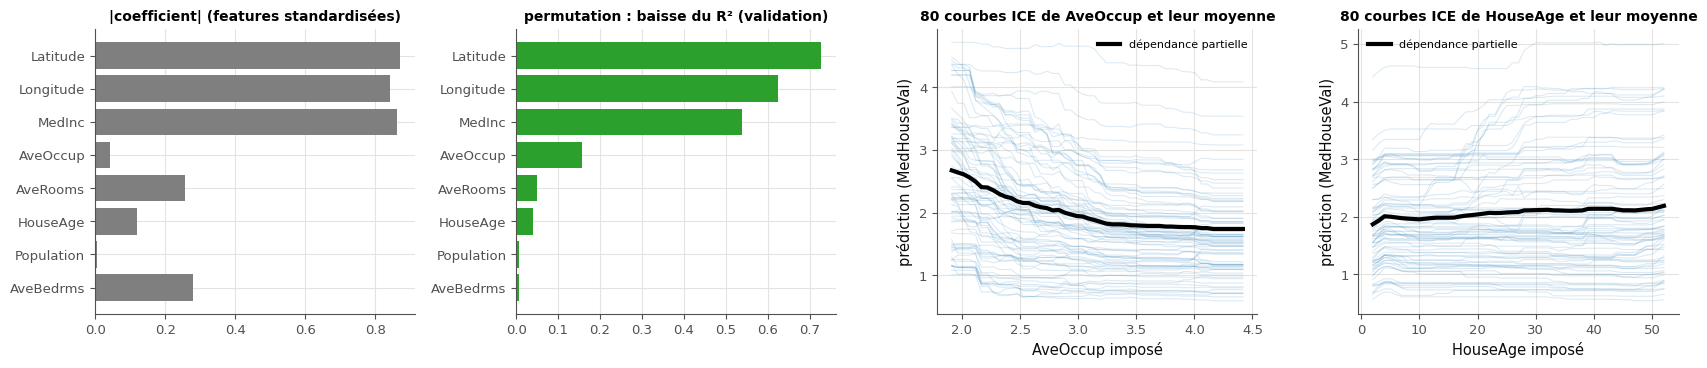

coefficients standardisés : MedInc 0,86, HouseAge 0,12, AveRooms -0,26, AveBedrms 0,28, Population -0,01, AveOccup -0,04, Latitude -0,87, Longitude -0,84
importances par permutation : Latitude 0,727, Longitude 0,624, MedInc 0,538, AveOccup 0,157, AveRooms 0,049, HouseAge 0,039, Population 0,006, AveBedrms 0,006


In [23]:
def linear_12(X, y):
    """A Pipeline StandardScaler -> LinearRegression, fitted on (X, y), returned."""
    return make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)


def coefs_12(pipeline):
    """pd.Series of the 8 coefficients of the LinearRegression of the pipeline, indexed by the features."""
    return pd.Series(pipeline[-1].coef_, index=pipeline.feature_names_in_)


def boosting_12(X, y):
    """HistGradientBoostingRegressor(random_state=0), every other setting by default, fitted on (X, y), returned."""
    return HistGradientBoostingRegressor(random_state=0).fit(X, y)


def permutation_12(model, X, y):
    """pd.Series: the mean drop of R² of permutation_importance(model, X, y, n_repeats=5, random_state=0), indexed by
    the columns of X, sorted from the largest to the smallest."""
    result = permutation_importance(model, X, y, n_repeats=5, random_state=0)
    return pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)


def pd_ice_12(model, X, feature):
    """dict {"grid": (50,), "average": (50,), "individual": (len(X), 50)} of
    partial_dependence(model, X, [feature], kind="both", grid_resolution=50)."""
    result = partial_dependence(model, X, [feature], kind="both", grid_resolution=50)
    return {"grid": result["grid_values"][0], "average": result["average"][0], "individual": result["individual"][0]}


ROWS_12 = X_VAL.iloc[:300]                     # the districts of the curves of the check
REF_LIN_12 = make_pipeline(StandardScaler(), LinearRegression()).fit(X_TRAIN, Y_TRAIN)
ok_12 = {}
with checked("B6.12"):
    lin_12 = linear_12(X_TRAIN.copy(), Y_TRAIN.copy())
    if returned("B6.12", "linear_12", lin_12):
        steps_12 = [step for _, step in getattr(lin_12, "steps", [])]
        verdict("B6.12", isinstance(lin_12, Pipeline) and steps_12 and isinstance(steps_12[-1], LinearRegression)
                and any(isinstance(s, StandardScaler) for s in steps_12),
                "linear_12 rend un Pipeline StandardScaler → LinearRegression.",
                f"linear_12 doit rendre un Pipeline (StandardScaler, puis LinearRegression), reçu {type(lin_12).__name__} "
                f"{[type(s).__name__ for s in steps_12]}.")
        scaler_12 = next((s for s in steps_12 if isinstance(s, StandardScaler)), None)
        if scaler_12 is not None and hasattr(scaler_12, "mean_"):
            verdict("B6.12", np.allclose(scaler_12.mean_, X_TRAIN.mean().to_numpy()),
                    "le StandardScaler a appris les moyennes de X_TRAIN.",
                    "le StandardScaler n'a pas appris les moyennes de X_TRAIN : sur quelles lignes est-il ajusté ?")
        c_12 = coefs_12(lin_12)
        want_c_12 = pd.Series(REF_LIN_12[-1].coef_, index=FEATURES)
        raw_12 = LinearRegression().fit(X_TRAIN, Y_TRAIN).coef_
        if not isinstance(c_12, pd.Series) or list(c_12.index) != FEATURES:
            print("❌ Ex B6.12 : coefs_12 doit rendre une pd.Series indexée par les 8 features, dans l'ordre de FEATURES "
                  f"(reçu {type(c_12).__name__}).")
        elif np.allclose(c_12.to_numpy(), raw_12):
            print("❌ Ex B6.12 : ce sont les coefficients des features brutes : chacun dépend de l'unité de sa feature ; "
                  "le contrat les veut sur des features standardisées.")
        else:
            ok_12["coefs"] = same("B6.12", "coefficients sur features standardisées", c_12.to_numpy(),
                                  want_c_12.to_numpy(), rtol=1e-6, atol=1e-9)

with checked("B6.12"):
    gb_12 = boosting_12(X_TRAIN.copy(), Y_TRAIN.copy())
    if returned("B6.12", "boosting_12", gb_12):
        if not isinstance(gb_12, HistGradientBoostingRegressor):
            print(f"❌ Ex B6.12 : boosting_12 doit rendre un HistGradientBoostingRegressor, reçu {type(gb_12).__name__}.")
            raise StopCheck
        want_p_12 = HistGradientBoostingRegressor(random_state=0).get_params()
        diff_12 = {k: v for k, v in gb_12.get_params().items() if want_p_12.get(k) != v}
        verdict("B6.12", not diff_12, "réglages : random_state=0, le reste par défaut.",
                f"réglages différents du contrat : {diff_12}.")
        same("B6.12", "prédictions de boosting_12 sur 200 districts de validation", gb_12.predict(X_VAL.iloc[:200]),
             GBR.predict(X_VAL.iloc[:200]), rtol=1e-9, atol=1e-9)

with checked("B6.12"):
    imp_12 = permutation_12(GBR, X_VAL.copy(), Y_VAL.copy())      # the reference model: a slip above does not spread
    want_i_12 = pd.Series(permutation_importance(GBR, X_VAL, Y_VAL, n_repeats=5, random_state=0).importances_mean,
                          index=FEATURES).sort_values(ascending=False)
    if not isinstance(imp_12, pd.Series) or sorted(imp_12.index) != sorted(FEATURES):
        print("❌ Ex B6.12 : permutation_12 doit rendre une pd.Series indexée par les 8 features "
              f"(reçu {type(imp_12).__name__}).")
        raise StopCheck
    verdict("B6.12", list(imp_12.index) == list(want_i_12.index) or bool((np.diff(imp_12.to_numpy()) <= 0).all()),
            "importances triées de la plus grande à la plus petite.",
            "permutation_12 doit trier les importances de la plus grande à la plus petite.")
    if not np.allclose(imp_12[FEATURES].to_numpy(), want_i_12[FEATURES].to_numpy(), atol=1e-9):
        on_train_12 = permutation_importance(GBR, X_TRAIN, Y_TRAIN, n_repeats=5, random_state=0).importances_mean
        if np.allclose(imp_12[FEATURES].to_numpy(), on_train_12, atol=1e-9):
            print("❌ Ex B6.12 : ces importances sont celles des districts d'entraînement : la permutation mesure ce que "
                  "le modèle perd sur des données qu'il n'a pas vues (relis 206.2).")
        else:
            same("B6.12", "importances par permutation (validation, 5 répétitions, random_state=0)",
                 imp_12[FEATURES].to_numpy(), want_i_12[FEATURES].to_numpy(), atol=1e-9)
    else:
        ok_12["perm"] = True
        print("✅ Ex B6.12 : importances par permutation sur la validation, comme attendu.")

with checked("B6.12"):
    out_12 = pd_ice_12(GBR, ROWS_12.copy(), "AveOccup")
    if not isinstance(out_12, dict) or set(out_12) != {"grid", "average", "individual"}:
        print("❌ Ex B6.12 : pd_ice_12 doit rendre un dictionnaire aux trois clés 'grid', 'average', 'individual'.")
        raise StopCheck
    ref_12 = partial_dependence(GBR, ROWS_12, ["AveOccup"], kind="both", grid_resolution=50)
    same("B6.12", "grid de AveOccup (50 valeurs)", out_12["grid"], ref_12["grid_values"][0])
    same("B6.12", "courbes ICE de AveOccup (300 districts × 50 valeurs)", out_12["individual"],
         ref_12["individual"][0], rtol=1e-9, atol=1e-9)
    if same("B6.12", "dépendance partielle de AveOccup", out_12["average"], ref_12["average"][0], rtol=1e-9, atol=1e-9):
        ok_12["pd"] = True
        verdict("B6.12", np.allclose(out_12["average"], np.asarray(out_12["individual"]).mean(axis=0)),
                "la dépendance partielle est la moyenne des courbes ICE.",
                "la dépendance partielle devrait être la moyenne des courbes ICE.")

if len(ok_12) == 3:                              # the figure, once your three results are right
    fig_12, axes_12 = plt.subplots(1, 4, figsize=(17, 3.8))
    order_12 = imp_12.index
    axes_12[0].barh(order_12[::-1], c_12[order_12[::-1]].abs(), color="tab:gray")
    axes_12[0].set_title("|coefficient| (features standardisées)", fontsize=10)
    axes_12[1].barh(order_12[::-1], imp_12[order_12[::-1]], color="tab:green")
    axes_12[1].set_title("permutation : baisse du R² (validation)", fontsize=10)
    for ax_12, feat_12 in zip(axes_12[2:], ("AveOccup", "HouseAge")):
        curves_12 = pd_ice_12(GBR, ROWS_12, feat_12)
        ax_12.plot(curves_12["grid"], np.asarray(curves_12["individual"])[:80].T, color="tab:blue", alpha=0.15, lw=0.8)
        ax_12.plot(curves_12["grid"], curves_12["average"], color="black", lw=3, label="dépendance partielle")
        ax_12.set_xlabel(f"{feat_12} imposé")
        ax_12.set_ylabel("prédiction (MedHouseVal)")
        ax_12.set_title(f"80 courbes ICE de {feat_12} et leur moyenne", fontsize=10)
        ax_12.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print("coefficients standardisés :", ", ".join(f"{k} {fr(v, 2)}" for k, v in c_12.items()))
    print("importances par permutation :", ", ".join(f"{k} {fr(v, 3)}" for k, v in imp_12.items()))

### Ex B6.13 — Prédire la forme des courbes ICE du revenu médian et de la latitude 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que les courbes ICE d'un gradient boosting montrent de deux features, avant de les tracer.  
**Prérequis :** Ex B6.12 · fiche §206.2 (« La dépendance partielle », « Les courbes ICE ») · **Fil rouge :** California · **Parcours :** C

L'expérience trace, pour le gradient boosting de référence `GBR`, les courbes ICE de `MedInc` (le revenu médian du district, en dizaines de milliers de dollars) et de `Latitude` (de ≈ 33° au sud, vers San Diego, à ≈ 39° au nord de la grille) sur 500 districts de validation, avec leur moyenne, la dépendance partielle ; chaque grille a 50 valeurs, du 5ᵉ au 95ᵉ centile de la feature. La prédiction est en `MedHouseVal`, en centaines de milliers de dollars. **Avant d'exécuter**, écris tes quatre prédictions :
- a) `medinc_rise_13` : de combien la dépendance partielle de `MedInc` monte-t-elle du début à la fin de sa grille ? `"A"` moins de 0,5 ; `"B"` de 0,5 à 1,5 ; `"C"` de 1,5 à 3 ; `"D"` plus de 3 ;
- b) `lat_trend_13` : du sud au nord, la dépendance partielle de `Latitude` : `"A"` monte (de plus de 0,3) ; `"B"` reste à peu près plate (entre −0,3 et +0,3) ; `"C"` descend (de plus de 0,3) ;
- c) `lat_up_13` : quelle part des 500 courbes ICE de `Latitude` **finissent plus haut** qu'elles ne commencent ? `"A"` moins de 5 % ; `"B"` de 5 à 30 % ; `"C"` de 30 à 70 % ; `"D"` plus de 70 % ;
- d) `spread_13` : les courbes ICE de `Latitude` varient-elles **plus** d'un district à l'autre que celles de `MedInc` (un écart-type plus grand de leur variation, fin moins début) ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes quatre prédictions ne sont pas écrites ; elle les vérifie à la fin. Rien n'y dépend de ton code.

Dans tes notes, avant d'exécuter : ce que tu sais de la Californie (où sont les villes, la côte, les grandes régions) et ce que tu attends d'un modèle qui voit la latitude **et** la longitude.

In [24]:
ROWS_13 = X_VAL.iloc[:500]                        # the 500 validation districts of the curves


def curves_13(feature):
    """(grid, average, individual) of the reference gradient boosting GBR for `feature` on ROWS_13: a grid of 50 values
    between the 5th and the 95th percentiles of the feature (written here without your code)."""
    result = partial_dependence(GBR, ROWS_13, [feature], kind="both", grid_resolution=50)
    return result["grid_values"][0], result["average"][0], result["individual"][0]

In [25]:
medinc_rise_13, lat_trend_13, lat_up_13, spread_13 = "C", "C", "A", True

In [26]:
wb.record("B6.13a", "C", mistakes={"« A » : lis la variation de la dépendance partielle de MedInc, sous la figure": "A", "« B » : lis la variation de la dépendance partielle de MedInc, sous la figure": "B", "« D » : lis la variation de la dépendance partielle de MedInc, sous la figure": "D"}, prediction=True)
wb.record("B6.13b", "C", mistakes={"« A » : suis la courbe épaisse de la latitude, du sud (à gauche) au nord (à droite)": "A", "« B » : lis la variation de la dépendance partielle de la latitude, sous la figure": "B"}, prediction=True)
wb.record("B6.13c", "A", mistakes={"« B » : lis la part des courbes ICE de la latitude qui finissent plus haut, sous la figure": "B", "« C » : lis la part des courbes ICE de la latitude qui finissent plus haut, sous la figure": "C", "« D » : lis la part des courbes ICE de la latitude qui finissent plus haut, sous la figure": "D"}, prediction=True)
wb.record("B6.13d", True, mistakes={"compare les deux écarts-types de la variation des ICE, sous la figure": False}, prediction=True)

WB_ANSWER {"hash": "ab3a543772b50f18bff5b5104ce673015c285d5ef045a07f03e90c29d2f78cec", "id": "B6.13a", "kind": "str", "mistakes": {"0c2c51224243cf58ef4acdd8bd7e68c48018b56a69423ef6f6bfb17315c025e9": "« A » : lis la variation de la dépendance partielle de MedInc, sous la figure", "318cc36a21cbee8cafffa54f4a9009c7df69af549e44b205828f28436234db17": "« D » : lis la variation de la dépendance partielle de MedInc, sous la figure", "a917b24f0149200f12d1c83d6b325ba62605bb3dcc52d63e491d040cd014321f": "« B » : lis la variation de la dépendance partielle de MedInc, sous la figure"}, "prediction": true}
📝 Ex B6.13a : réponse enregistrée (str).
WB_ANSWER {"hash": "7533313b2b36f1c6e173ffb73f70b5fee70c8f41c1164bb46fe85a9e89458057", "id": "B6.13b", "kind": "str", "mistakes": {"0662f26bf67e3ce860a06359f71b629b6ad2de4a1d26c72897ff9825d06795d5": "« A » : suis la courbe épaisse de la latitude, du sud (à gauche) au nord (à droite)", "59220863c64962fb226a46ea245810af0809a42a9d05465508c6617237a0af83": "« B »

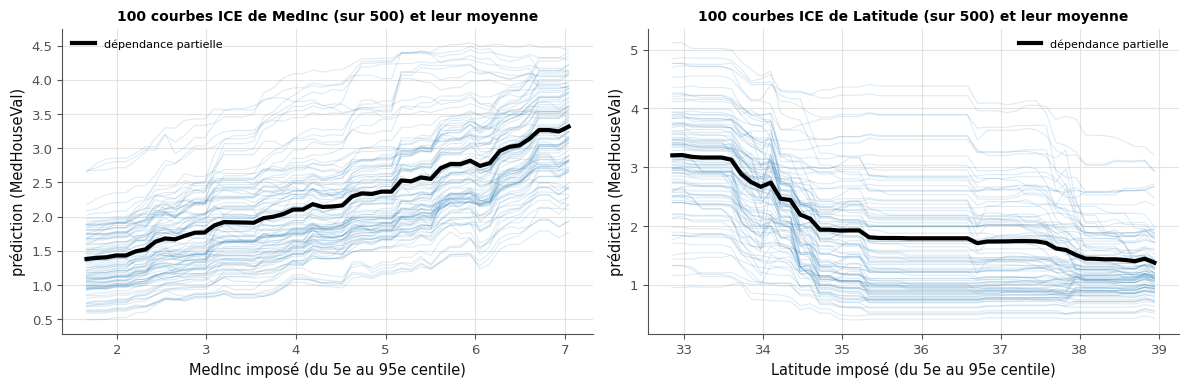

  MedInc : variation de la dépendance partielle (fin − début) 1,94 ; courbes ICE qui finissent plus haut 100 % ; écart-type de la variation des ICE 0,45
Latitude : variation de la dépendance partielle (fin − début) -1,82 ; courbes ICE qui finissent plus haut 0 % ; écart-type de la variation des ICE 0,60
✅ Ex B6.13a : C'est ça !
✅ Ex B6.13b : Parfait !
✅ Ex B6.13c : Bravo !
✅ Ex B6.13d : Exact !


In [27]:
if any(answer is ... or answer is None for answer in [medinc_rise_13, lat_trend_13, lat_up_13, spread_13]):
    print("⏳ Ex B6.13 : écris d'abord tes quatre prédictions dans la cellule précédente.")
else:
    fig_13, axes_13 = plt.subplots(1, 2, figsize=(12, 4))
    seen_13 = {}
    for ax_13, feature_13 in zip(axes_13, ("MedInc", "Latitude")):
        grid_13, avg_13, ind_13 = curves_13(feature_13)
        ax_13.plot(grid_13, ind_13[:100].T, color="tab:blue", alpha=0.15, lw=0.8)
        ax_13.plot(grid_13, avg_13, color="black", lw=3, label="dépendance partielle")
        ax_13.set_xlabel(f"{feature_13} imposé (du 5e au 95e centile)")
        ax_13.set_ylabel("prédiction (MedHouseVal)")
        ax_13.set_title(f"100 courbes ICE de {feature_13} (sur 500) et leur moyenne", fontsize=10)
        ax_13.legend(fontsize=8)
        change_13 = ind_13[:, -1] - ind_13[:, 0]
        seen_13[feature_13] = {"rise": float(avg_13[-1] - avg_13[0]), "up": float(np.mean(change_13 > 0)),
                               "spread": float(np.std(change_13))}
    plt.tight_layout()
    plt.show()
    for feature_13, s_13 in seen_13.items():
        print(f"{feature_13:>8} : variation de la dépendance partielle (fin − début) {fr(s_13['rise'], 2)} ; "
              f"courbes ICE qui finissent plus haut {pct(s_13['up'])} ; écart-type de la variation des ICE {fr(s_13['spread'], 2)}")
    wb.check("B6.13a", medinc_rise_13)
    wb.check("B6.13b", lat_trend_13)
    wb.check("B6.13c", lat_up_13)
    wb.check("B6.13d", spread_13)

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Que te disent les courbes ICE de la latitude que la dépendance partielle seule ne dit pas, et avec quelle autre feature la latitude interagit-elle sans doute ? Imposer une latitude à un district sans toucher à sa longitude : quelles combinaisons crée-t-on, et ces districts existent-ils (piège « une dépendance partielle hors des données ») ? Une courbe ICE dit-elle ce que **ferait** un déménagement du district vers le nord ?

### Ex B6.14 — shapley_values : Shapley exact par énumération des coalitions 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire le calcul exact des valeurs de Shapley interventionnelles, que shap approche.  
**Prérequis :** ✏️ B6.1 · ∂ B6.2 · fiche §206.3 (« Les features comme joueurs », « Un exemple à deux features », « Combien ça coûte ») · **Fil rouge :** California · **mylearn :** `explain.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/explain.py` (créé par `python tools/start_chapter.py B6`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb6_explain.py -q` les lance tous dans un terminal.

**Contrat** de `shapley_values(f, x, background, max_features=12)`, qui rend le couple `(phi, base_value)` :
- `f` ne reçoit que des tableaux 2-D de forme `(n, M)`, jamais une ligne seule, et rend une sortie de forme `(n,)`, par exemple `model.predict(X)` ou `model.predict_proba(X)[:, 1]` ; elle peut être appelée plusieurs fois ;
- $v(S)$ est la **moyenne de $f$** sur les $B$ lignes du fond dont les colonnes de $S$ prennent les valeurs de `x` ($f$ d'abord, la moyenne ensuite) ; **toutes** les lignes du fond comptent, sans sous-échantillonnage (contrairement au `max_samples=100` par défaut de shap) ;
- `phi` est un tableau de forme `(M,)` ; `base_value` vaut $v(\varnothing)$, la moyenne de $f$ sur le fond, un `float` Python ; l'efficacité `phi.sum() + base_value == f(x)` tient aux arrondis près ;
- `ValueError` si $M >$ `max_features` ($M =$ `max_features` est permis), si `x` n'est pas 1-D, ou si `background` n'est pas 2-D à $M$ colonnes ; `x` et `background` peuvent être des listes et ne sont jamais modifiés ;
- **coût** : la docstring prescrit l'énumération des $2^M$ coalitions, chaque $v(S)$ calculé **une seule fois** (un appel à `f` sur les $B$ lignes) ; les tests comptent les lignes passées à `f` et arrêtent ta fonction au-delà de `max(2·M·2**M·B, 500 000)` lignes, avec un message qui le dit. Ce budget laisse passer un $v(S)$ recalculé pour chaque feature, ou `f` appelée ligne par ligne ; il arrête une énumération des $M!$ ordres d'arrivée sans mémoire des $v(S)$ (40 320 ordres à $M = 8$), qui prendrait des minutes.

La première cellule de vérification essaie ta fonction sur les deux exemples de la docstring, sur un modèle linéaire à 5 features et un fond aléatoire de 20 lignes ($\phi_i = w_i(x_i - \bar b_i)$, ∂ B6.2), sur ce que reçoit `f`, puis sur le gradient boosting de référence de California (8 features, fond de 50 lignes : efficacité, valeur de base, comparaison à `shap.explainers.Exact`, durée affichée), et sur quatre gardes. La seconde lance les 33 tests de l'exercice (`-k "test_shapley_values_"`).

Dans tes notes : combien de lignes ta fonction passe-t-elle à `f` pour $M = 8$ et $B = 50$, et combien en passerait une version qui recalcule chaque $v(S)$ pour chaque feature ? Pourquoi `f` doit-elle recevoir des tableaux 2-D (pense au coût d'un appel à `predict`) ? Que deviendrait la durée affichée avec 12 features (🧮 B6.7) ?

In [28]:
with checked("B6.14"):
    E = mylearn.explain
    w_14 = np.array([2.0, -1.0, 0.5])
    bg_14 = np.array([[0.0, 0.0, 0.0], [2.0, 2.0, 2.0]])
    phi_14, base_14 = pair("B6.14", "shapley_values", E.shapley_values(lambda X: X @ w_14, [3.0, 1.0, 1.0], bg_14.copy()),
                           names=("phi", "base_value"), floats=("base_value",))
    same("B6.14", "phi du modèle linéaire de la docstring", phi_14, [4.0, 0.0, 0.0])
    same("B6.14", "base_value du modèle linéaire de la docstring", base_14, 1.5)
    same("B6.14", "le produit x0 x1 de la docstring : l'interaction partagée",
         E.shapley_values(lambda X: X[:, 0] * X[:, 1], [1.0, 1.0], [[0.0, 0.0]])[0], [0.5, 0.5])

    rng_14 = np.random.default_rng(14)                 # a linear model on a random background: w_i (x_i - mean_i)
    w5_14, x5_14, bg5_14 = rng_14.normal(size=5), rng_14.normal(size=5), rng_14.normal(size=(20, 5))
    same("B6.14", "modèle linéaire à 5 features, fond de 20 lignes : w_i (x_i − moyenne du fond)",
         E.shapley_values(lambda X: X @ w5_14 + 1.0, x5_14, bg5_14)[0], w5_14 * (x5_14 - bg5_14.mean(axis=0)),
         rtol=1e-8, atol=1e-10)
    shapes_14 = []

    def spy_14(X):
        shapes_14.append(np.shape(X))
        return np.asarray(X, dtype=float) @ w5_14

    E.shapley_values(spy_14, x5_14, bg5_14)
    bad_14 = sorted({s for s in shapes_14 if len(s) != 2 or s[1] != 5})
    verdict("B6.14", not bad_14, "f ne reçoit que des tableaux 2-D de 5 colonnes.",
            f"f a reçu les formes {bad_14[:3]} : appelle-la sur des tableaux (n, M), jamais sur une ligne seule.")
    rows_14 = sum(s[0] for s in shapes_14 if len(s) == 2)
    print(f"ℹ️ f a été appelée {len(shapes_14)} fois, sur {rows_14} lignes en tout (2**5 coalitions × 20 lignes = "
          f"{2 ** 5 * 20}).")

    X0_14, BG_14 = X_VAL.iloc[0].to_numpy(), X_TRAIN.iloc[:50].to_numpy()
    copies_14 = (X0_14.copy(), BG_14.copy())
    start_14 = time.perf_counter()
    phi_c_14, base_c_14 = pair("B6.14", "shapley_values", E.shapley_values(GBR.predict, X0_14, BG_14),
                               names=("phi", "base_value"), floats=("base_value",))
    seconds_14 = time.perf_counter() - start_14
    same("B6.14", "California, efficacité : somme des phi + base_value = f(x)", float(np.sum(phi_c_14)) + base_c_14,
         float(GBR.predict(X0_14[None])[0]), rtol=1e-9, atol=1e-9)
    same("B6.14", "California : base_value = moyenne de f sur les 50 lignes du fond", base_c_14,
         float(GBR.predict(BG_14).mean()), rtol=1e-9, atol=1e-9)
    if shap is not None:
        exact_14 = shap.explainers.Exact(GBR.predict, shap.maskers.Independent(BG_14, max_samples=len(BG_14)))(X0_14[None])
        same("B6.14", "California : phi contre shap.explainers.Exact (fond complet)", phi_c_14, exact_14.values[0],
             rtol=1e-7, atol=1e-9)
    print(f"ℹ️ California, 8 features, fond de 50 lignes (256 coalitions × 50 = 12 800 lignes) : {fr(seconds_14, 2)} s.")
    verdict("B6.14", np.array_equal(X0_14, copies_14[0]) and np.array_equal(BG_14, copies_14[1]),
            "x et le fond n'ont pas changé.", "shapley_values a modifié x ou le fond reçus.")

    try:
        E.shapley_values(lambda X: X.sum(axis=1), np.ones(3), np.zeros((2, 3)), max_features=3)
        print("✅ Ex B6.14 : M = max_features est permis.")
    except ValueError as exc_14:
        print(f"❌ Ex B6.14 : M = max_features doit être permis (seul M > max_features lève) : reçu ValueError ({exc_14}).")
    refuses("B6.14", "M = 4 > max_features = 3", lambda: E.shapley_values(lambda X: X.sum(axis=1), np.ones(4),
                                                                        np.zeros((2, 4)), max_features=3))
    refuses("B6.14", "x en 2-D", lambda: E.shapley_values(lambda X: X.sum(axis=1), np.ones((1, 3)), np.zeros((2, 3))))
    refuses("B6.14", "un fond de 2 colonnes pour x de 3", lambda: E.shapley_values(lambda X: X.sum(axis=1), np.ones(3),
                                                                                   np.zeros((2, 2))))

✅ Ex B6.14 : phi du modèle linéaire de la docstring : [4.0, 0.0, 0.0], comme attendu.
✅ Ex B6.14 : base_value du modèle linéaire de la docstring : 1.5, comme attendu.
✅ Ex B6.14 : le produit x0 x1 de la docstring : l'interaction partagée : [0.5, 0.5], comme attendu.
✅ Ex B6.14 : modèle linéaire à 5 features, fond de 20 lignes : w_i (x_i − moyenne du fond) : [0.69051384, -0.04911232, -0.9996215, -3.20321981, 0.31239432], comme attendu.
✅ Ex B6.14 : f ne reçoit que des tableaux 2-D de 5 colonnes.
ℹ️ f a été appelée 1 fois, sur 640 lignes en tout (2**5 coalitions × 20 lignes = 640).
✅ Ex B6.14 : California, efficacité : somme des phi + base_value = f(x) : 2.56299576, comme attendu.
✅ Ex B6.14 : California : base_value = moyenne de f sur les 50 lignes du fond : 1.97909014, comme attendu.


✅ Ex B6.14 : California : phi contre shap.explainers.Exact (fond complet) : un tableau (8,), comme attendu.
ℹ️ California, 8 features, fond de 50 lignes (256 coalitions × 50 = 12 800 lignes) : 0,07 s.
✅ Ex B6.14 : x et le fond n'ont pas changé.
✅ Ex B6.14 : M = max_features est permis.
✅ Ex B6.14 : M = 4 > max_features = 3 : ValueError levée (4 features > max_features = 3: 2**4 coalitions x 2 rows would be needed; raise max_features or use an approximation (Ker).
✅ Ex B6.14 : x en 2-D : ValueError levée (x must be 1-D (one instance), got shape (1, 3)).
✅ Ex B6.14 : un fond de 2 colonnes pour x de 3 : ValueError levée (background must be 2-D with 3 columns (the features of x), got shape (2, 2)).


In [29]:
if written(lambda: mylearn.explain.shapley_values(lambda X: X.sum(axis=1), [0.0], [[0.0]])):
    run_pytest_group(TEST_EXPLAIN, impl="ref", keyword="test_shapley_values_")   # 33 tests
else:
    print("⏳ Ex B6.14 : les tests attendent ta fonction shapley_values.")

pytest: 33 passed, 153 deselected in 3.20s


### Ex B6.15 — SHAP sur un gradient boosting California : TreeExplainer, waterfall, beeswarm, dépendance 📦 ★★ ⏱️ 30 min
**Objectif :** expliquer un gradient boosting avec TreeSHAP, vérifier qu'il calcule le même Shapley que ta fonction, et lire les trois graphiques de shap.  
**Prérequis :** Ex B6.14 · ch. 14 · fiche §206.4 (« L'API de shap », « Les trois graphiques à connaître ») · **Fil rouge :** California · **Parcours :** R, C

**Contrat** des deux fonctions de la cellule suivante :
- `fit_15(X, y)` rend un `HistGradientBoostingRegressor(max_depth=3, random_state=0)` (des arbres peu profonds, les autres réglages par défaut), ajusté sur `(X, y)` ;
- `tree_shap_15(model, background, rows)` rend le `shap.Explanation` de `shap.TreeExplainer(model, data=background, feature_perturbation="interventional")` appliqué au DataFrame `rows` : `.values` de forme `(len(rows), 8)`, `.base_values`, `.feature_names`.

La cellule donnée fixe `BG_15`, le fond (les 50 premiers districts d'entraînement), et `ROWS_15`, les 1 000 premiers districts de validation à expliquer. La cellule de vérification ajuste ton modèle sur `X_TRAIN`, l'explique, contrôle l'efficacité sur les 1 000 districts, puis vérifie quatre grandeurs que tes fonctions calculent (rien à taper, aucune à arrondir) : a) la valeur de base ; b) la valeur SHAP de `MedInc` pour le premier district ; c) la moyenne des $\lvert\phi_{\text{MedInc}}\rvert$ sur les 1 000 districts ; d) si ta `shapley_values` (B6.14), avec le même fond de 50 lignes, redonne les valeurs de TreeSHAP sur le premier district à $10^{-6}$ près (`True` ou `False`). La cellule suivante trace le waterfall du premier district, le beeswarm et la dépendance de `MedInc`.

> ⚠️ **Piège classique — TreeSHAP et les données en float64** — `TreeExplainer` parcourt les arbres en **float32**. Un `HistGradientBoosting` pose certains seuils exactement sur des valeurs répétées des données (la latitude et la longitude de California en ont beaucoup) : une valeur égale à un seuil peut alors passer de l'autre côté, et TreeSHAP perd l'efficacité (des écarts jusqu'à 0,5 sur les données d'origine de scikit-learn, mesurés avec shap 0.54.1). C'est pourquoi `wbx.california()` arrondit les features en float32 : TreeSHAP interventionnel y redonne le Shapley exact à $10^{-8}$ près. Sur tes propres données, vérifie toujours l'efficacité (shap le fait : `check_additivity`).

Dans tes notes : pourquoi la valeur de base a) n'est-elle ni la moyenne des cibles d'entraînement, ni la prédiction moyenne des 1 000 districts expliqués ? Sur le waterfall, quelles features font monter et descendre la prédiction du premier district, et de combien ? Sur le beeswarm, dans quel sens joue un grand revenu, et quelles features ont une grande dispersion ? Sur la dépendance de `MedInc`, qu'indique la dispersion verticale à revenu égal ? Combien de temps a pris TreeSHAP sur 1 000 districts, et combien prendrait ta `shapley_values` (sa durée pour un district est affichée en B6.14) ?

In [30]:
BG_15 = X_TRAIN.iloc[:50]          # the background: the first 50 training districts
ROWS_15 = X_VAL.iloc[:1000]        # the 1 000 validation districts to explain
MEDINC = FEATURES.index("MedInc")  # the column of MedInc (0)

In [31]:
def fit_15(X, y):
    """HistGradientBoostingRegressor(max_depth=3, random_state=0), every other setting by default, fitted on (X, y)."""
    return HistGradientBoostingRegressor(max_depth=3, random_state=0).fit(X, y)


def tree_shap_15(model, background, rows):
    """The shap.Explanation of shap.TreeExplainer(model, data=background, feature_perturbation="interventional")
    on the DataFrame `rows`: .values of shape (len(rows), 8), .base_values, .feature_names."""
    explainer = shap.TreeExplainer(model, data=background, feature_perturbation="interventional")
    return explainer(rows)


SV_15 = MODEL_15 = None
with checked("B6.15"):
    if shap is None:
        print("⏳ Ex B6.15 : cet exercice a besoin de shap (wb.ensure('shap')).")
        raise StopCheck
    model_15 = fit_15(X_TRAIN.copy(), Y_TRAIN.copy())
    if not returned("B6.15", "fit_15", model_15):
        raise StopCheck
    if not isinstance(model_15, HistGradientBoostingRegressor):
        print(f"❌ Ex B6.15 : fit_15 doit rendre un HistGradientBoostingRegressor, reçu {type(model_15).__name__}.")
        raise StopCheck
    want_p_15 = HistGradientBoostingRegressor(max_depth=3, random_state=0).get_params()
    diff_15 = {k: v for k, v in model_15.get_params().items() if want_p_15.get(k) != v}
    verdict("B6.15", not diff_15, "réglages : max_depth=3, random_state=0, le reste par défaut.",
            f"réglages différents du contrat : {diff_15}.")
    ref_15 = HistGradientBoostingRegressor(max_depth=3, random_state=0).fit(X_TRAIN, Y_TRAIN)
    if not same("B6.15", "prédictions de fit_15 sur 200 districts de validation", model_15.predict(X_VAL.iloc[:200]),
                ref_15.predict(X_VAL.iloc[:200]), rtol=1e-9, atol=1e-9):
        raise StopCheck
    MODEL_15 = model_15
    sv_15 = tree_shap_15(model_15, BG_15.copy(), ROWS_15.copy())
    if not returned("B6.15", "tree_shap_15", sv_15):
        raise StopCheck
    if np.shape(getattr(sv_15, "values", None)) != (len(ROWS_15), len(FEATURES)):
        print("❌ Ex B6.15 : tree_shap_15 doit rendre un shap.Explanation dont .values a la forme (1000, 8), reçu "
              f"{type(sv_15).__name__} de forme {np.shape(getattr(sv_15, 'values', None))}.")
        raise StopCheck
    if not getattr(sv_15, "feature_names", None):
        sv_15.feature_names = list(FEATURES)               # rows given as an array: the names for the plots
    SV_15 = sv_15
    gap_eff_15 = float(np.abs(sv_15.values.sum(axis=1) + np.ravel(sv_15.base_values) - model_15.predict(ROWS_15)).max())
    verdict("B6.15", gap_eff_15 < 1e-6, f"efficacité sur les 1 000 districts : écart maximal {gap_eff_15:.1e}.",
            f"efficacité : somme des valeurs SHAP + valeur de base s'écarte de la prédiction de {gap_eff_15:.2g} : "
            "l'explication porte-t-elle sur ce modèle et sur ces lignes ?")
    wb.check("B6.15a", float(np.ravel(sv_15.base_values)[0]), computed=True)
    wb.check("B6.15b", float(sv_15.values[0, MEDINC]), computed=True)
    wb.check("B6.15c", float(np.mean(np.abs(sv_15.values[:, MEDINC]))), computed=True)

with checked("B6.15"):
    if SV_15 is None:
        raise StopCheck
    if not written(lambda: mylearn.explain.shapley_values(lambda X: X.sum(axis=1), [0.0], [[0.0]])):
        print("⏳ Ex B6.15 : la comparaison attend ta shapley_values (Ex B6.14).")
        raise StopCheck
    x0_15 = ROWS_15.iloc[0].to_numpy()
    phi_15, base_15 = pair("B6.15", "shapley_values", mylearn.explain.shapley_values(MODEL_15.predict, x0_15,
                                                                                     BG_15.to_numpy()),
                           names=("phi", "base_value"), floats=("base_value",))
    gap_15 = max(float(np.abs(np.asarray(phi_15, dtype=float) - SV_15.values[0]).max()),
                 abs(base_15 - float(np.ravel(SV_15.base_values)[0])))
    print(f"ℹ️ écart maximal entre TreeExplainer et ta shapley_values sur le premier district : {gap_15:.1e}")
    wb.check("B6.15d", bool(gap_15 <= 1e-6))

✅ Ex B6.15 : réglages : max_depth=3, random_state=0, le reste par défaut.


✅ Ex B6.15 : prédictions de fit_15 sur 200 districts de validation : un tableau (200,), comme attendu.


✅ Ex B6.15 : efficacité sur les 1 000 districts : écart maximal 2.7e-08.
❓ Ex B6.15a : aucune réponse enregistrée pour cet exercice. Vérifie l'ID, puis fais un `git pull` (le fichier src/wb/answers.json est peut-être plus récent sur GitHub).
❓ Ex B6.15b : aucune réponse enregistrée pour cet exercice. Vérifie l'ID, puis fais un `git pull` (le fichier src/wb/answers.json est peut-être plus récent sur GitHub).
❓ Ex B6.15c : aucune réponse enregistrée pour cet exercice. Vérifie l'ID, puis fais un `git pull` (le fichier src/wb/answers.json est peut-être plus récent sur GitHub).
ℹ️ écart maximal entre TreeExplainer et ta shapley_values sur le premier district : 6.2e-09
❓ Ex B6.15d : aucune réponse enregistrée pour cet exercice. Vérifie l'ID, puis fais un `git pull` (le fichier src/wb/answers.json est peut-être plus récent sur GitHub).


In [32]:
# The right values, computed above with the solution; the classic slips, recomputed here
tree_path_15 = shap.TreeExplainer(MODEL_15)(ROWS_15.iloc[:1])                # without background: path-dependent
default_15 = shap.TreeExplainer(GBR, data=BG_15, feature_perturbation="interventional")(ROWS_15)   # the default boosting
bg100_15 = shap.TreeExplainer(MODEL_15, data=X_TRAIN.iloc[:100], feature_perturbation="interventional")(ROWS_15.iloc[:1])
base_r_15 = float(np.ravel(SV_15.base_values)[0])
phi_r_15 = float(SV_15.values[0, MEDINC])
mean_r_15 = float(np.mean(np.abs(SV_15.values[:, MEDINC])))


def distinct_15(right, slips):
    """The slips whose value differs from the right one, and from each other, at 4 decimals."""
    kept, seen = {}, {round(right, 4)}
    for message, value in slips.items():
        if round(value, 4) not in seen:
            kept[message] = value
            seen.add(round(value, 4))
    return kept


wb.record("B6.15a", base_r_15, decimals=4, mistakes=distinct_15(base_r_15, {
    "c'est la valeur de base sans fond (mode « chemins de l'arbre ») : relis les deux modes de TreeExplainer (§206.4)":
        float(np.ravel(tree_path_15.base_values)[0]),
    "c'est la moyenne des cibles d'entraînement : la valeur de base est la prédiction moyenne sur le fond": float(Y_TRAIN.mean()),
    "c'est la prédiction moyenne sur les districts expliqués : la valeur de base se calcule sur le fond": float(MODEL_15.predict(ROWS_15).mean()),
    "c'est le gradient boosting par défaut : le contrat veut max_depth=3": float(np.ravel(default_15.base_values)[0])}))
wb.record("B6.15b", phi_r_15, decimals=4, mistakes=distinct_15(phi_r_15, {
    "c'est la valeur sans fond (mode « chemins de l'arbre ») : relis les deux modes de TreeExplainer (§206.4)":
        float(tree_path_15.values[0, MEDINC]),
    "c'est le gradient boosting par défaut : le contrat veut max_depth=3": float(default_15.values[0, MEDINC]),
    "c'est un fond de 100 lignes : le contrat en prend 50": float(bg100_15.values[0, MEDINC]),
    "vérifie le signe": -phi_r_15}))
wb.record("B6.15c", mean_r_15, decimals=4, mistakes=distinct_15(mean_r_15, {
    "c'est la moyenne des valeurs SHAP signées : on demande la moyenne de leurs valeurs absolues":
        float(np.mean(SV_15.values[:, MEDINC])),
    "c'est la moyenne des carrés : on demande la moyenne des valeurs absolues": float(np.mean(SV_15.values[:, MEDINC] ** 2)),
    "c'est le gradient boosting par défaut : le contrat veut max_depth=3": float(np.mean(np.abs(default_15.values[:, MEDINC])))}))
wb.record("B6.15d", True, mistakes={
    "TreeExplainer et ta shapley_values diffèrent de plus de 1e-6 : ta fonction passe-t-elle ses tests (Ex B6.14), et "
    "garde-t-elle toutes les lignes du fond ?": False})

WB_ANSWER {"decimals": 4, "hash": "0d2ace9c5469db2810339c543054859111607c121cc23f65d4194e51c3cdec3a", "hash_coarse": "fe5c5943590633f56b278dd78af27e97eecc92b7caf4a8c5f4be9992d8816c23", "id": "B6.15a", "kind": "float", "magnitude": 0, "mistakes": {"487d555d05186929905307fd738a193faf3f599bc941442319fe60b85018fb1c": "c'est la valeur de base sans fond (mode « chemins de l'arbre ») : relis les deux modes de TreeExplainer (§206.4)", "660f26c3f1266060af05737a1b414a4fe0a5ce3bebaf35b7f763f7bb950eddea": "c'est le gradient boosting par défaut : le contrat veut max_depth=3", "e7f78662d5ab6e9f54a65a5dd34fe378cb08d9b187dbb25b324b8976afdcb47d": "c'est la moyenne des cibles d'entraînement : la valeur de base est la prédiction moyenne sur le fond", "fa3559db72816093ecb0602909af9a89e582bf4fdeaba54508a7967a08d65635": "c'est la prédiction moyenne sur les districts expliqués : la valeur de base se calcule sur le fond"}, "sign": 1}
📝 Ex B6.15a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decima

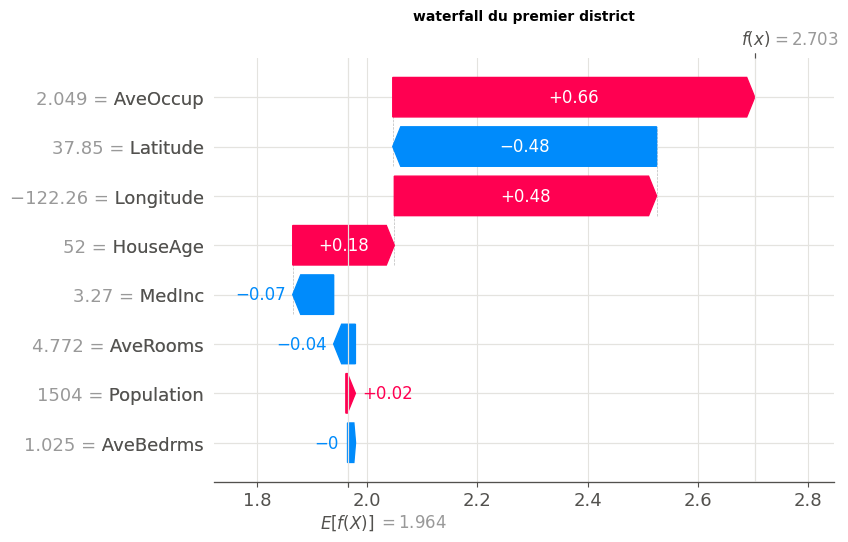

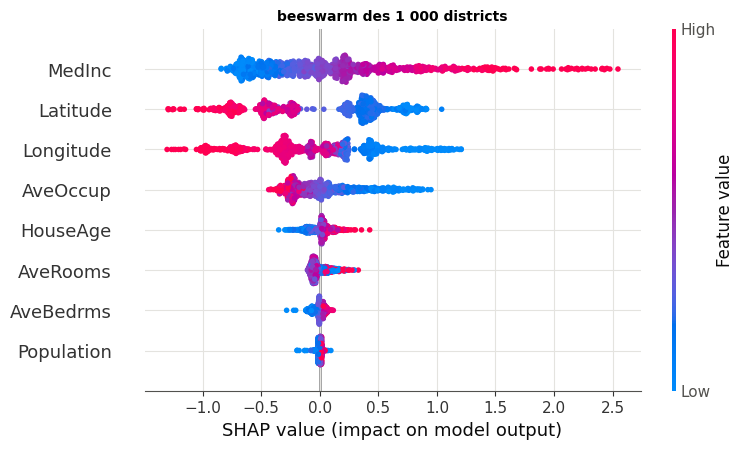

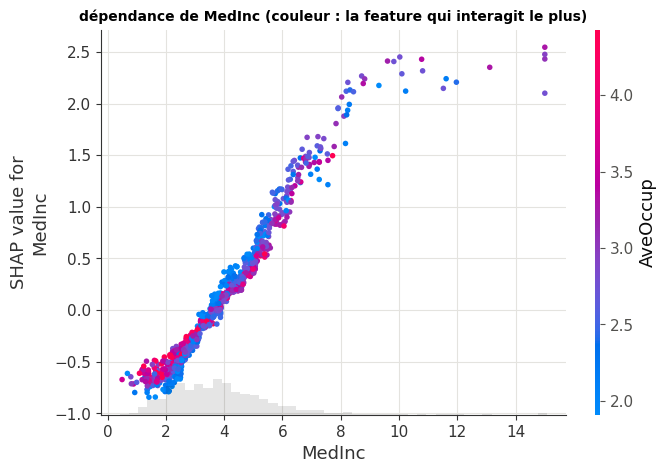

In [33]:
if SV_15 is not None:                       # the three plots of 206.4, on your explanation
    shap.plots.waterfall(SV_15[0], show=False)
    plt.title("waterfall du premier district", fontsize=10)
    plt.show()
    shap.plots.beeswarm(SV_15, show=False)
    plt.title("beeswarm des 1 000 districts", fontsize=10)
    plt.show()
    shap.plots.scatter(SV_15[:, MEDINC], color=SV_15, show=False)
    plt.title("dépendance de MedInc (couleur : la feature qui interagit le plus)", fontsize=10)
    plt.show()
else:
    print("⏳ Ex B6.15 : les graphiques attendent ton explication (cellule précédente).")

### Ex B6.16 — Le fond change tout : trois fonds différents, puis une feature dupliquée 🔬 ★★★ ⏱️ 40 min
**Objectif :** mesurer ce que le choix du fond et une feature dupliquée font aux valeurs de Shapley d'un gradient boosting.  
**Prérequis :** Ex B6.15 · fiche §206.3 (« Le fond fait partie de la question ») et §206.4 (« Features corrélées : ce que SHAP répartit ») · 🧠 Q5, Q6 · **Fil rouge :** California · **Parcours :** C

Deux expériences sur le gradient boosting de référence `GBR`. **Ne présume pas l'issue : mesure-la.**

**1. Trois fonds.** La cellule donnée choisit `X_16`, le district de validation le plus proche du 75ᵉ centile du revenu, et trois fonds (`BACKGROUNDS_16`) : `"population"`, 50 districts d'entraînement tirés au hasard ; `"riches"`, 50 districts du décile de revenu le plus haut ; `"ligne type"`, **une** ligne, la médiane de chaque feature. Contrat de `explain_16(model, x, background)` : il rend le couple `(phi, base)`, les valeurs de Shapley interventionnelles de `model.predict` au district `x` (une `pd.Series` des 8 features) avec le fond `background` (un DataFrame), un tableau `(8,)`, et la valeur de base, un `float` ; ta `shapley_values` ou `shap.TreeExplainer` (les mêmes nombres, B6.15). La cellule de vérification compare tes valeurs à TreeSHAP pour les trois fonds, puis affiche le tableau des valeurs de base et des $\phi$.

**2. Une feature dupliquée.** `add_copy_16(X, noise, rng)` (donnée) ajoute à un DataFrame, juste après `MedInc`, la colonne `"MedInc_copy"` = `MedInc` + `noise` × (écart-type de `MedInc`) × un bruit gaussien tiré par `rng`. Contrat de `copy_experiment_16(noise, seed, n_rows=200)` :
- `rng = np.random.default_rng(seed)`, puis `A = add_copy_16(X_TRAIN, noise, rng)` et `V = add_copy_16(X_VAL, noise, rng)`, dans cet ordre, avec le même `rng` ;
- un `HistGradientBoostingRegressor(random_state=seed)` ajusté sur `(A, Y_TRAIN)` ;
- `shap.TreeExplainer` interventionnel, de fond les 50 premières lignes de `A`, sur les `n_rows` premières lignes de `V` ;
- il rend `{"MedInc": moyenne des |φ_MedInc|, "MedInc_copy": moyenne des |φ_copie|, "sum": moyenne des |φ_MedInc + φ_copie|}` (des floats).

La cellule d'expérience essaie d'abord ta fonction sur un petit cas (bruit 0,01, graine 0, 50 districts), puis la lance pour trois niveaux de bruit (0, 0,01 et 0,1 écart-type) et trois graines (≈ 10 s), à côté de la moyenne des $\lvert\phi_{\text{MedInc}}\rvert$ du modèle sans copie.

Dans tes notes : avec quel fond la valeur SHAP de `MedInc` change-t-elle de signe, et pourquoi ? Que change le fond « ligne type » par rapport à « population » ? Quelle phrase écrirais-tu sous un waterfall pour dire quel fond a servi ? Pour la copie : que reçoit-elle quand elle est exacte (bruit 0), et pourquoi ? Avec un bruit de 0,01, le partage entre `MedInc` et sa copie est-il stable d'une graine à l'autre ? Et la somme ? Que rapporterais-tu à un métier qui demande « quelle est l'importance du revenu ? » quand deux colonnes le portent ?

In [34]:
# the district to explain: the validation district closest to the 75th percentile of MedInc
X_16 = X_VAL.iloc[int(np.argmin(np.abs(X_VAL["MedInc"].to_numpy() - X_VAL["MedInc"].quantile(0.75))))]
RICH_16 = X_TRAIN[X_TRAIN["MedInc"] >= X_TRAIN["MedInc"].quantile(0.9)]          # the top decile of income
BACKGROUNDS_16 = {"population": X_TRAIN.sample(50, random_state=0),             # 50 districts drawn at random
                  "riches": RICH_16.sample(50, random_state=0),                  # 50 districts of the top decile
                  "ligne type": X_TRAIN.median().to_frame().T.astype("float32").astype("float64")}   # one row: medians
SD_MEDINC_16 = float(X_TRAIN["MedInc"].std())
NOISES_16, SEEDS_16 = (0.0, 0.01, 0.1), (0, 1, 2)


def add_copy_16(X, noise, rng):
    """A copy of the DataFrame X with the column "MedInc_copy" = MedInc + noise * SD_MEDINC_16 * N(0, 1), drawn by
    rng.standard_normal(len(X)), placed right after MedInc and rounded to float32 like the other features (B6.15)."""
    out = X.copy()
    copy = X["MedInc"].to_numpy() + noise * SD_MEDINC_16 * rng.standard_normal(len(X))
    out.insert(1, "MedInc_copy", copy.astype("float32").astype("float64"))
    return out


print(f"district expliqué : MedInc {fr(X_16['MedInc'], 2)}, Latitude {fr(X_16['Latitude'], 2)}, prédiction "
      f"{fr(GBR.predict(X_16.to_frame().T)[0], 2)} ; fonds : " + ", ".join(f"{k} ({len(v)} ligne{'s' * (len(v) > 1)})"
                                                                            for k, v in BACKGROUNDS_16.items()))

district expliqué : MedInc 4,78, Latitude 33,74, prédiction 3,80 ; fonds : population (50 lignes), riches (50 lignes), ligne type (1 ligne)


In [35]:
def explain_16(model, x, background):
    """(phi, base): the interventional Shapley values of model.predict at the district x (a pd.Series of the 8
    features) with the DataFrame `background`, as an array (8,), and the base value, a float."""
    explanation = shap.TreeExplainer(model, data=background, feature_perturbation="interventional")(x.to_frame().T)
    return explanation.values[0], float(np.ravel(explanation.base_values)[0])


def copy_experiment_16(noise, seed, n_rows=200):
    """The duplicated feature: rng = np.random.default_rng(seed); A = add_copy_16(X_TRAIN, noise, rng), then
    V = add_copy_16(X_VAL, noise, rng) (the same rng, in this order); HistGradientBoostingRegressor(random_state=seed)
    fitted on (A, Y_TRAIN); shap.TreeExplainer (interventional, background: the first 50 rows of A) on the first
    n_rows rows of V. Returns {"MedInc": mean |phi_MedInc|, "MedInc_copy": mean |phi_copy|,
    "sum": mean |phi_MedInc + phi_copy|} over these rows (floats)."""
    rng = np.random.default_rng(seed)
    A, V = add_copy_16(X_TRAIN, noise, rng), add_copy_16(X_VAL, noise, rng)
    model = HistGradientBoostingRegressor(random_state=seed).fit(A, Y_TRAIN)
    values = shap.TreeExplainer(model, data=A.iloc[:50], feature_perturbation="interventional")(V.iloc[:n_rows]).values
    i, j = list(A.columns).index("MedInc"), list(A.columns).index("MedInc_copy")
    return {"MedInc": float(np.mean(np.abs(values[:, i]))), "MedInc_copy": float(np.mean(np.abs(values[:, j]))),
            "sum": float(np.mean(np.abs(values[:, i] + values[:, j])))}


TABLE_16 = {}
with checked("B6.16"):
    if shap is None:
        print("⏳ Ex B6.16 : cet exercice a besoin de shap (wb.ensure('shap')).")
        raise StopCheck
    for name_16, bg_16 in BACKGROUNDS_16.items():
        got_16 = explain_16(GBR, X_16.copy(), bg_16.copy())
        phi_16, base_16 = pair("B6.16", "explain_16", got_16, names=("phi", "base"), floats=("base",))
        want_16 = shap.TreeExplainer(GBR, data=bg_16, feature_perturbation="interventional")(X_16.to_frame().T)
        ok_16 = same("B6.16", f"fond « {name_16} » : phi", phi_16, want_16.values[0], rtol=1e-6, atol=1e-6)
        ok_16 &= same("B6.16", f"fond « {name_16} » : valeur de base", base_16, float(np.ravel(want_16.base_values)[0]),
                      rtol=1e-6, atol=1e-6)
        if ok_16:
            TABLE_16[name_16] = (base_16, np.asarray(phi_16, dtype=float))
if len(TABLE_16) == len(BACKGROUNDS_16):
    f_16 = float(GBR.predict(X_16.to_frame().T)[0])
    print(f"\nprédiction du district : {fr(f_16, 3)}")
    print(f"{'fond':>12} | {'base':>6} | " + " | ".join(f"{name[:9]:>9}" for name in FEATURES))
    for name_16, (base_16, phi_16) in TABLE_16.items():
        print(f"{name_16:>12} | {fr(base_16, 3):>6} | " + " | ".join(f"{fr(v, 3):>9}" for v in phi_16))

✅ Ex B6.16 : fond « population » : phi : un tableau (8,), comme attendu.
✅ Ex B6.16 : fond « population » : valeur de base : 1.81856286, comme attendu.


✅ Ex B6.16 : fond « riches » : phi : un tableau (8,), comme attendu.
✅ Ex B6.16 : fond « riches » : valeur de base : 3.91654653, comme attendu.


✅ Ex B6.16 : fond « ligne type » : phi : un tableau (8,), comme attendu.
✅ Ex B6.16 : fond « ligne type » : valeur de base : 2.15773654, comme attendu.

prédiction du district : 3,800
        fond |   base |    MedInc |  HouseAge |  AveRooms | AveBedrms | Populatio |  AveOccup |  Latitude | Longitude
  population |  1,819 |     0,644 |     0,231 |    -0,116 |    -0,116 |    -0,048 |     0,965 |     0,550 |    -0,129
      riches |  3,917 |    -0,671 |     0,332 |    -0,469 |    -0,090 |    -0,032 |     0,770 |     0,241 |    -0,197
  ligne type |  2,158 |     0,562 |     0,025 |    -0,096 |    -0,090 |    -0,024 |     1,058 |     0,571 |    -0,364


In [36]:
COPIES_16 = {}
with checked("B6.16"):
    if shap is None:
        raise StopCheck
    got_16 = copy_experiment_16(0.01, 0, n_rows=50)      # a small first run, checked before the whole grid
    if not isinstance(got_16, dict) or set(got_16) != {"MedInc", "MedInc_copy", "sum"}:
        print("❌ Ex B6.16 : copy_experiment_16 doit rendre un dictionnaire aux clés 'MedInc', 'MedInc_copy', 'sum'.")
        raise StopCheck
    rng_16 = np.random.default_rng(0)
    A_16, V_16 = add_copy_16(X_TRAIN, 0.01, rng_16), add_copy_16(X_VAL, 0.01, rng_16)
    m_16 = HistGradientBoostingRegressor(random_state=0).fit(A_16, Y_TRAIN)
    v_16 = shap.TreeExplainer(m_16, data=A_16.iloc[:50], feature_perturbation="interventional")(V_16.iloc[:50]).values
    want_16 = [np.mean(np.abs(v_16[:, 0])), np.mean(np.abs(v_16[:, 1])), np.mean(np.abs(v_16[:, 0] + v_16[:, 1]))]
    if not same("B6.16", "copy_experiment_16(0.01, 0, n_rows=50)", [got_16[k] for k in ("MedInc", "MedInc_copy", "sum")],
                want_16, rtol=1e-6, atol=1e-6):
        raise StopCheck
    start_16 = time.perf_counter()
    for noise_16 in NOISES_16:
        for seed_16 in SEEDS_16:
            COPIES_16[noise_16, seed_16] = copy_experiment_16(noise_16, seed_16)
    print(f"ℹ️ {len(COPIES_16)} entraînements et explications en {time.perf_counter() - start_16:.0f} s.\n")
    alone_16 = shap.TreeExplainer(GBR, data=X_TRAIN.iloc[:50], feature_perturbation="interventional")(X_VAL.iloc[:200])
    print(f"sans copie : moyenne de |phi_MedInc| sur les 200 districts = {fr(np.mean(np.abs(alone_16.values[:, 0])), 3)}")
    for noise_16 in NOISES_16:
        cells_16 = [COPIES_16[noise_16, s] for s in SEEDS_16]
        print(f"bruit {fr(noise_16, 2)} écart-type : " + " ; ".join(
            f"graine {s} : MedInc {fr(c['MedInc'], 3)}, copie {fr(c['MedInc_copy'], 3)}, somme {fr(c['sum'], 3)}"
            for s, c in zip(SEEDS_16, cells_16)))

✅ Ex B6.16 : copy_experiment_16(0.01, 0, n_rows=50) : [0.24208581, 0.14374328, 0.37154301], comme attendu.


ℹ️ 9 entraînements et explications en 8 s.



sans copie : moyenne de |phi_MedInc| sur les 200 districts = 0,390
bruit 0,00 écart-type : graine 0 : MedInc 0,390, copie 0,000, somme 0,390 ; graine 1 : MedInc 0,393, copie 0,000, somme 0,393 ; graine 2 : MedInc 0,374, copie 0,000, somme 0,374
bruit 0,01 écart-type : graine 0 : MedInc 0,250, copie 0,143, somme 0,382 ; graine 1 : MedInc 0,094, copie 0,314, somme 0,388 ; graine 2 : MedInc 0,161, copie 0,235, somme 0,387
bruit 0,10 écart-type : graine 0 : MedInc 0,369, copie 0,049, somme 0,381 ; graine 1 : MedInc 0,365, copie 0,044, somme 0,384 ; graine 2 : MedInc 0,333, copie 0,078, somme 0,389


### Ex B6.17 — Penguins : SHAP par classe pour une régression logistique et une forêt aléatoire 📦 ★★ ⏱️ 25 min
**Objectif :** expliquer un classifieur à trois classes, une sortie à la fois, en logit puis en probabilité.  
**Prérequis :** Ex B6.15 · ∂ B6.2 · fiche §206.4 (« L'API de shap ») · ch. 13 et 14 · **Fil rouge :** Penguins · **Parcours :** C

Pourquoi ce manchot est-il un Gentoo ? La cellule donnée charge le découpage figé de Penguins (`wbx.penguins()` : 249 manchots d'entraînement, 84 de test, les 4 mesures en colonnes, l'espèce en label) et `GENTOO_17`, le premier Gentoo du test ; au ch. 0A tu as découvert ce dataset, au ch. 13 tu l'as classé. Un classifieur multiclasse a **une sortie par classe** : on explique une sortie à la fois, la probabilité de la classe $k$ ou son logit, et ces deux sorties ne donnent pas les mêmes valeurs (206.4). **Contrat** :
- `fit_logistic_17(X, y)` rend `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))` ajusté ; `fit_forest_17(X, y)`, `RandomForestClassifier(n_estimators=200, random_state=0)` ajusté ;
- `class_output_17(model, k, kind="proba")` rend la fonction `f(X) -> (n,)` d'**une** sortie : la probabilité de la classe d'indice `k` (`predict_proba`) pour `kind="proba"`, son logit (`decision_function`) pour `kind="logit"` ;
- `shap_by_class_17(model, x, background, kind="proba")` rend le couple `(phi, base)` : `phi` de forme `(3, 4)`, une ligne par classe dans l'ordre de `model.classes_` (`SPECIES`), calculée par ta `shapley_values` sur la sortie de cette classe, et `base` de forme `(3,)`.

La cellule de vérification compare tes deux modèles à scikit-learn, puis explique `GENTOO_17` avec les modèles de référence et tout l'entraînement pour fond : en logit pour la régression logistique, elle compare tes valeurs au cas linéaire ($\phi_{ki} = w_{ki}(x_i - \bar b_i)$ dans les unités des mesures, ∂ B6.2) ; en probabilité, elle vérifie l'efficacité de chaque classe et les valeurs de base ; pour la forêt, elle compare tes valeurs à `shap.TreeExplainer` interventionnel, avec tout le fond (`shap.maskers.Independent(XP_TRAIN, max_samples=249)` : sinon il n'en garde que 100), à $2 \cdot 10^{-3}$ près, parce que sur une forêt TreeSHAP s'écarte lui-même de `predict_proba` de quelques $10^{-4}$. Puis elle trace les trois explications et affiche, pour chacune, la somme sur les trois classes de chaque feature.

Dans tes notes : quelles mesures font du manchot un Gentoo selon chaque explication ? Les logits et les probabilités classent-ils les mesures dans le même ordre ? Pourquoi les sommes sur les classes affichées valent-elles 0 pour les probabilités (pense à l'additivité et à ce que vaut la somme des trois probabilités), et que valent-elles pour les logits ? La forêt et la régression logistique s'appuient-elles sur les mêmes mesures ?

In [37]:
PENG = wbx.penguins()                               # frozen split of Penguins: 249 penguins, 84 for the test
XP_TRAIN, XP_TEST = PENG.X_train.to_numpy(), PENG.X_test.to_numpy()   # the 4 measures, as arrays (columns PENG.features)
YP_TRAIN, YP_TEST = PENG.y_train.to_numpy(), PENG.y_test.to_numpy()   # the species, strings
SPECIES = PENG.classes                               # ['Adelie', 'Chinstrap', 'Gentoo']: the order of predict_proba
GENTOO_17 = XP_TEST[np.flatnonzero(YP_TEST == "Gentoo")[0]]           # the penguin to explain: the first Gentoo
print("le manchot expliqué :", ", ".join(f"{name} {fr(v, 1)}" for name, v in zip(PENG.features, GENTOO_17)))

le manchot expliqué : bill_length_mm 45,1, bill_depth_mm 14,5, flipper_length_mm 207,0, body_mass_g 5050,0


✅ Ex B6.17 : fit_logistic_17 : StandardScaler puis LogisticRegression.
✅ Ex B6.17 : probabilités de fit_logistic_17 sur le test : un tableau (84, 3), comme attendu.


✅ Ex B6.17 : probabilités de fit_forest_17 sur le test : un tableau (84, 3), comme attendu.
✅ Ex B6.17 : class_output_17(LR, 2, 'proba') sur le test : un tableau (84,), comme attendu.
✅ Ex B6.17 : class_output_17(LR, 2, 'logit') sur le test : un tableau (84,), comme attendu.
✅ Ex B6.17 : logits : phi = w_ki (x_i − moyenne du fond), le cas linéaire : un tableau (3, 4), comme attendu.
✅ Ex B6.17 : probabilités : efficacité de chaque classe : [0.0055836, 0.00422682, 0.99018957], comme attendu.
✅ Ex B6.17 : probabilités : valeurs de base = probabilités moyennes sur le fond : [0.43775937, 0.20485149, 0.35738914], comme attendu.
ℹ️ forêt : TreeSHAP s'écarte lui-même de predict_proba de 4.2e-04 (son efficacité) ; la comparaison se fait donc à 2e-3 près.
✅ Ex B6.17 : forêt : tes valeurs contre TreeExplainer (interventionnel, fond complet) : un tableau (3, 4), comme attendu.


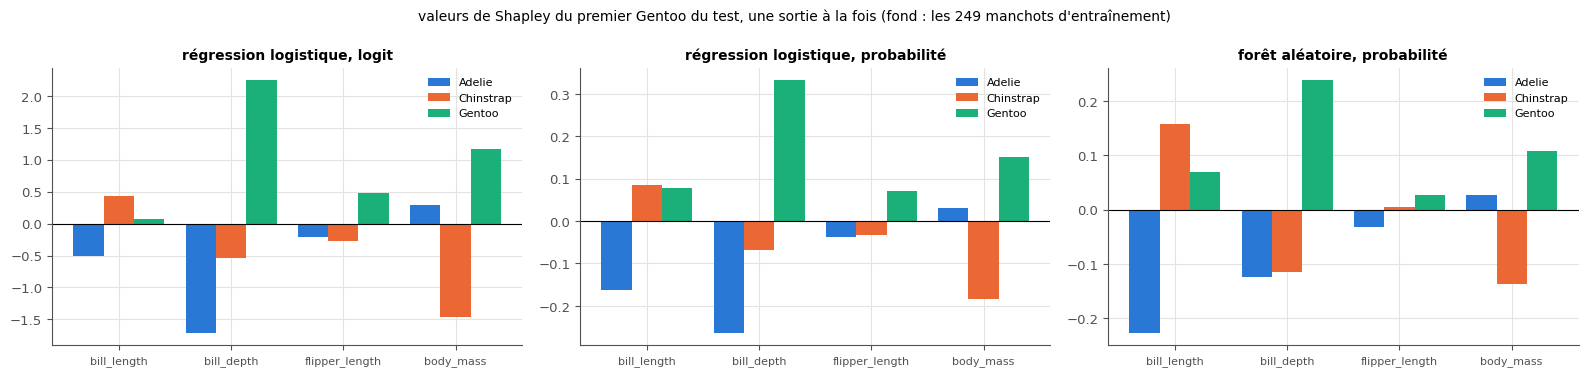

        régression logistique, logit : somme sur les classes de chaque feature 0,0000, 0,0000, 0,0000, 0,0000
  régression logistique, probabilité : somme sur les classes de chaque feature -0,0000, -0,0000, -0,0000, -0,0000
        forêt aléatoire, probabilité : somme sur les classes de chaque feature -0,0000, -0,0000, -0,0000, 0,0000


In [38]:
def fit_logistic_17(X, y):
    """make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), fitted on (X, y), returned."""
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, y)


def fit_forest_17(X, y):
    """RandomForestClassifier(n_estimators=200, random_state=0), fitted on (X, y), returned."""
    return RandomForestClassifier(n_estimators=200, random_state=0).fit(X, y)


def class_output_17(model, k, kind="proba"):
    """The function f(X) -> (n,) of ONE output of a classifier: the probability of the class of index k
    (predict_proba) for kind="proba", its logit (decision_function) for kind="logit"."""
    if kind == "proba":
        return lambda X: model.predict_proba(X)[:, k]
    if kind == "logit":
        return lambda X: model.decision_function(X)[:, k]
    raise ValueError(f"kind must be 'proba' or 'logit', got {kind!r}")


def shap_by_class_17(model, x, background, kind="proba"):
    """(phi, base): phi of shape (3, 4), the Shapley values of the 4 measures for each class (a row per class, in the
    order of model.classes_), base of shape (3,), with your shapley_values, one output at a time."""
    results = [mylearn.explain.shapley_values(class_output_17(model, k, kind), x, background)
               for k in range(len(model.classes_))]
    return np.array([phi for phi, _ in results]), np.array([base for _, base in results])


LR_17 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(XP_TRAIN, YP_TRAIN)   # references
RF_17 = RandomForestClassifier(n_estimators=200, random_state=0).fit(XP_TRAIN, YP_TRAIN)
G_17 = GENTOO_17[None]
with checked("B6.17"):
    lr_17 = fit_logistic_17(XP_TRAIN.copy(), YP_TRAIN.copy())
    if returned("B6.17", "fit_logistic_17", lr_17):
        steps_17 = [type(s).__name__ for _, s in getattr(lr_17, "steps", [])]
        verdict("B6.17", steps_17 == ["StandardScaler", "LogisticRegression"],
                "fit_logistic_17 : StandardScaler puis LogisticRegression.",
                f"fit_logistic_17 doit rendre le Pipeline (StandardScaler, LogisticRegression), reçu {steps_17 or type(lr_17).__name__}.")
        same("B6.17", "probabilités de fit_logistic_17 sur le test", lr_17.predict_proba(XP_TEST),
             LR_17.predict_proba(XP_TEST), rtol=1e-6, atol=1e-8)
    rf_17 = fit_forest_17(XP_TRAIN.copy(), YP_TRAIN.copy())
    if returned("B6.17", "fit_forest_17", rf_17):
        same("B6.17", "probabilités de fit_forest_17 sur le test", rf_17.predict_proba(XP_TEST), RF_17.predict_proba(XP_TEST))

with checked("B6.17"):
    f_p_17, f_l_17 = class_output_17(LR_17, 2, "proba"), class_output_17(LR_17, 2, "logit")
    if not (callable(f_p_17) and callable(f_l_17)):
        print("❌ Ex B6.17 : class_output_17 doit rendre une fonction f(X) -> (n,).")
        raise StopCheck
    same("B6.17", "class_output_17(LR, 2, 'proba') sur le test", f_p_17(XP_TEST), LR_17.predict_proba(XP_TEST)[:, 2])
    same("B6.17", "class_output_17(LR, 2, 'logit') sur le test", f_l_17(XP_TEST), LR_17.decision_function(XP_TEST)[:, 2])

RESULTS_17 = {}
with checked("B6.17"):
    phi_l_17, base_l_17 = pair("B6.17", "shap_by_class_17", shap_by_class_17(LR_17, GENTOO_17.copy(), XP_TRAIN.copy(), "logit"),
                               names=("phi", "base"))
    if np.shape(phi_l_17) != (3, 4) or np.shape(base_l_17) != (3,):
        print(f"❌ Ex B6.17 : attendu phi de forme (3, 4) et base de forme (3,), reçu {np.shape(phi_l_17)} et {np.shape(base_l_17)}.")
        raise StopCheck
    scaler_17, logreg_17 = LR_17[0], LR_17[-1]
    linear_17 = logreg_17.coef_ / scaler_17.scale_ * (GENTOO_17 - XP_TRAIN.mean(axis=0))   # w_ki (x_i - mean_i), ∂ B6.2
    if same("B6.17", "logits : phi = w_ki (x_i − moyenne du fond), le cas linéaire", phi_l_17, linear_17, rtol=1e-6, atol=1e-8):
        RESULTS_17["régression logistique, logit"] = np.asarray(phi_l_17)
    phi_p_17, base_p_17 = pair("B6.17", "shap_by_class_17", shap_by_class_17(LR_17, GENTOO_17.copy(), XP_TRAIN.copy(), "proba"),
                               names=("phi", "base"))
    ok_p_17 = same("B6.17", "probabilités : efficacité de chaque classe", np.sum(phi_p_17, axis=1) + base_p_17,
                   LR_17.predict_proba(G_17)[0], rtol=1e-6, atol=1e-8)
    ok_p_17 &= same("B6.17", "probabilités : valeurs de base = probabilités moyennes sur le fond", base_p_17,
                    LR_17.predict_proba(XP_TRAIN).mean(axis=0), rtol=1e-6, atol=1e-8)
    if ok_p_17:
        RESULTS_17["régression logistique, probabilité"] = np.asarray(phi_p_17)
    phi_rf_17, base_rf_17 = pair("B6.17", "shap_by_class_17", shap_by_class_17(RF_17, GENTOO_17.copy(), XP_TRAIN.copy(), "proba"),
                                 names=("phi", "base"))
    if shap is not None:                  # the whole background: TreeExplainer keeps at most 100 rows by default
        tree_17 = shap.TreeExplainer(RF_17, data=shap.maskers.Independent(XP_TRAIN, max_samples=len(XP_TRAIN)),
                                     feature_perturbation="interventional")(G_17)
        own_17 = float(np.abs(tree_17.values[0].sum(axis=0) + tree_17.base_values[0] - RF_17.predict_proba(G_17)[0]).max())
        print(f"ℹ️ forêt : TreeSHAP s'écarte lui-même de predict_proba de {own_17:.1e} (son efficacité) ; la comparaison "
              "se fait donc à 2e-3 près.")
        if same("B6.17", "forêt : tes valeurs contre TreeExplainer (interventionnel, fond complet)", phi_rf_17,
                tree_17.values[0].T, rtol=0, atol=2e-3):
            RESULTS_17["forêt aléatoire, probabilité"] = np.asarray(phi_rf_17)
if len(RESULTS_17) == 3:
    fig_17, axes_17 = plt.subplots(1, 3, figsize=(16, 3.8))
    for ax_17, (title_17, phi_17) in zip(axes_17, RESULTS_17.items()):
        for k_17, species_17 in enumerate(SPECIES):
            ax_17.bar(np.arange(4) + 0.27 * (k_17 - 1), phi_17[k_17], width=0.27, label=species_17)
        ax_17.axhline(0, color="black", lw=0.8)
        ax_17.set_xticks(range(4), [name.replace("_mm", "").replace("_g", "") for name in PENG.features], fontsize=8)
        ax_17.set_title(title_17, fontsize=10)
        ax_17.legend(fontsize=8)
    plt.suptitle("valeurs de Shapley du premier Gentoo du test, une sortie à la fois (fond : les 249 manchots d'entraînement)",
                 fontsize=10)
    plt.tight_layout()
    plt.show()
    for title_17, phi_17 in RESULTS_17.items():
        print(f"{title_17:>36} : somme sur les classes de chaque feature " + ", ".join(fr(v, 4) for v in phi_17.sum(axis=0)))

## Partie B · Réseaux : gradients intégrés et Grad-CAM

Tu écris d'abord en NumPy les deux méthodes de ta librairie qui ne dépendent pas du réseau : les gradients intégrés à partir d'une fonction de gradient, et la combinaison Grad-CAM à partir d'activations et de gradients déjà extraits (B6.18). Puis tu les branches sur des réseaux : saillance, gradient × entrée et gradients intégrés sur un petit CNN CIFAR-10 (B6.19), Grad-CAM par hooks sur le ResNet fine-tuné du B1, pour des bonnes prédictions et des erreurs (B6.20). Au ch. 21, FGSM et la maximisation d'activation dérivaient déjà par rapport à l'entrée (🔁 R1) ; au ch. 20 et au B1, tu as posé des hooks.

La cellule suivante charge 500 images de test de CIFAR-10 (`X_CIFAR`, `Y_CIFAR` : 50 par classe, en uint8) et `CNN`, le petit CNN de référence de B6.19 : trois blocs de deux convolutions, entraîné une fois par `wbx.cifar_cnn` (≈ 40 s sur CPU la première fois, puis relu du disque), **gelé** et en mode `eval()` ; il reçoit des pixels dans $[0, 1]$, de forme `(N, 3, 32, 32)`, et se normalise lui-même : l'image noire est le tenseur nul. `show_rows` affiche une grille d'images et de cartes.

In [39]:
# Tools of part B: CIFAR-10 and the small CNN of B6.19 (the ResNet of B6.20 is loaded there)
import torch
import torch.nn.functional as F

CLASSES = wb.datasets.CIFAR10_CLASSES
X_CIFAR, Y_CIFAR = wb.datasets.load_cifar10_subset(50, "test")   # 500 test images, uint8 (N, 32, 32, 3), int labels
CNN, CNN_INFO = wbx.cifar_cnn(FAST_MODE)   # trained once (≈ 40 s on CPU), then read back; frozen, in eval() mode


def show_rows(rows, row_titles, col_titles, cmaps, size=1.7, suptitle=None):
    """A grid of images: rows[r][c] is an image (H, W, 3) in [0, 1] or a map (H, W); cmaps[c] the colour map of the
    column c ("gray" for the images is ignored), None for an image."""
    nrow, ncol = len(rows), len(rows[0])
    fig, axes = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.5 if suptitle else 0.1)), squeeze=False)
    for r in range(nrow):
        for c in range(ncol):
            ax = axes[r, c]
            ax.imshow(rows[r][c], cmap=cmaps[c], vmin=None if cmaps[c] is None else 0)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(col_titles[c], fontsize=8)
        axes[r, 0].set_ylabel(row_titles[r], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()


print(f"CIFAR-10 : {len(X_CIFAR)} images de test (50 par classe). Petit CNN de référence : "
      f"{sum(p.numel() for p in CNN.parameters())} paramètres, accuracy de test {pct(CNN_INFO['test_accuracy'], 1)}, "
      "entrée : des pixels dans [0, 1], (N, 3, 32, 32).")

ℹ️ CNN de référence relu (cifar_cnn-reference-a0d669cd51fb8c01.pt)
CIFAR-10 : 500 images de test (50 par classe). Petit CNN de référence : 73178 paramètres, accuracy de test 65,6 %, entrée : des pixels dans [0, 1], (N, 3, 32, 32).


### Ex B6.18 — integrated_gradients et grad_cam 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire les gradients intégrés à partir d'une fonction de gradient, et la combinaison Grad-CAM de cartes et de gradients déjà extraits.  
**Prérequis :** ✏️ B6.3, B6.4 · fiche §206.5 (« Les gradients intégrés », « En pratique : une somme à la place de l'intégrale ») et §206.6 (« Un exemple à la main », « Avec PyTorch : deux hooks ») · **mylearn :** `explain.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/explain.py` (créé par `python tools/start_chapter.py B6`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb6_explain.py -q` les lance tous dans un terminal.

**Contrat** de `integrated_gradients(grad_fn, x, baseline=None, n_steps=50, method="trapezoid")` :
- les points du chemin sont $\mathbf{x}' + \alpha(\mathbf{x} - \mathbf{x}')$, $\mathbf{x}'$ la ligne de référence `baseline` (des zéros si `None`) ; la moyenne pondérée des gradients est multipliée par $\mathbf{x} - \mathbf{x}'$, et le résultat a la forme de `x`, en float, même pour un `x` entier ;
- `n_steps` compte les **intervalles**, un entier ≥ 1 : `'left'`, `'right'` et `'midpoint'` utilisent $n$ points de poids $1/n$, `'trapezoid'` les $n + 1$ points $k/n$ de poids $1/n$, divisés par deux aux extrémités (la docstring) ;
- `grad_fn` ne reçoit que des **batches** de forme `(n, *x.shape)`, même avec `n_steps = 1` (pour un seul point : `point[None]`, puis `[0]` sur le résultat) ; elle peut être appelée une fois ou sur plusieurs morceaux ;
- `ValueError` si `n_steps < 1`, si `method` est inconnue (les noms de captum, comme `'riemann_trapezoid'`, sont refusés), ou si `baseline` n'a pas **exactement** la forme de `x` (une forme seulement diffusable est refusée) ; `x` et `baseline` ne sont pas modifiés ;
- ⚠️ la note de la docstring sur captum est inexacte : son `riemann_trapezoid` à $n + 1$ points vaut ton `'trapezoid'` **multiplié par $n/(n+1)$**, parce que ses poids somment à moins de 1 (fiche, 🕰️ de 206.6 ; ✏️ B6.3 k) ; `'left'`, `'right'` et `'midpoint'` coïncident avec `riemann_left`, `riemann_right` et `riemann_middle` au même nombre de points.

**Contrat** de `grad_cam(activations, gradients, relu=True, normalize=True)` :
- les deux entrées ont exactement la même forme 4-D `(N, C, H, W)`, sinon `ValueError` ; le résultat a la forme `(N, H, W)` ;
- le poids d'un canal est la **moyenne** spatiale de ses gradients ; la carte est la somme pondérée des canaux, la ReLU appliquée **une fois**, à cette somme (`relu=True`) ;
- `normalize=True` divise **chaque** carte par sa propre plus grande valeur absolue, sans epsilon ; une carte nulle, y compris après la ReLU, reste nulle (pas de NaN) ;
- les entrées ne sont pas modifiées.

La première cellule de vérification essaie `integrated_gradients` sur les exemples de la docstring, sur $x_0 x_1 + x_2^3$ en $(1, 2, -1)$ avec les quatre règles et 6 intervalles (formes fermées), sur ce que reçoit `grad_fn`, sur la complétude de la sigmoïde de 206.5, un `x` entier et trois refus ; la seconde partie essaie `grad_cam` sur la docstring, sur trois images de 4 canaux (contre `np.einsum`), l'invariance à un facteur positif des gradients, `relu=False`, des gradients nuls et deux refus. La seconde cellule lance les 111 tests de l'exercice (`-k "test_integrated_gradients_ or test_grad_cam_"`) ; sans captum, 12 sont ignorés.

Dans tes notes : avec 6 intervalles, quelle règle donne la valeur exacte pour $x_0 x_1$, et pourquoi pas pour $x_2^3$ ? Pourquoi la complétude sert-elle de test à une implémentation ? Pourquoi `grad_cam` ne fait-elle que la combinaison, et pas l'extraction (qui reste côté PyTorch) ?

In [40]:
with checked("B6.18"):
    E = mylearn.explain
    grad_q_18 = lambda X: np.stack([2 * X[:, 0], np.full(len(X), 3.0)], axis=1)       # f = x0**2 + 3 x1 (docstring)
    same("B6.18", "docstring : x0² + 3 x1 en (1, 1), n_steps=4, 'left'",
         E.integrated_gradients(grad_q_18, [1.0, 1.0], n_steps=4, method="left"), [0.75, 3.0])
    same("B6.18", "docstring : la même avec 'trapezoid'", E.integrated_gradients(grad_q_18, [1.0, 1.0], n_steps=4), [1.0, 3.0])

    # f = x0 x1 + x2**3 at x = (1, 2, -1) from a zero baseline: on the path a x, the gradient is (a x1, a x0, 3 a² x2²)
    grad_c_18 = lambda X: np.stack([X[:, 1], X[:, 0], 3 * X[:, 2] ** 2], axis=1)
    x_18 = np.array([1.0, 2.0, -1.0])
    k_18 = np.arange(7) / 6                                       # n = 6 intervals
    means_18 = {"left": (k_18[:-1].mean(), (k_18[:-1] ** 2).mean()), "right": (k_18[1:].mean(), (k_18[1:] ** 2).mean()),
                "midpoint": (((np.arange(6) + 0.5) / 6).mean(), (((np.arange(6) + 0.5) / 6) ** 2).mean()),
                "trapezoid": (0.5, 1 / 3 + 1 / (6 * 36))}         # the means of a and a² for each rule
    for method_18, (m1_18, m2_18) in means_18.items():
        want_18 = np.array([x_18[0] * x_18[1] * m1_18, x_18[1] * x_18[0] * m1_18, x_18[2] * 3 * x_18[2] ** 2 * m2_18])
        same("B6.18", f"x0 x1 + x2³ en (1, 2, −1), n_steps=6, '{method_18}'",
             E.integrated_gradients(grad_c_18, x_18.copy(), n_steps=6, method=method_18), want_18)
    shapes_18 = []

    def spy_18(X):
        shapes_18.append(np.shape(X))
        return grad_c_18(np.asarray(X, dtype=float))

    E.integrated_gradients(spy_18, x_18, n_steps=1, method="left")
    verdict("B6.18", shapes_18 and all(len(s) == 2 and s[1] == 3 for s in shapes_18),
            "grad_fn ne reçoit que des batches (n, 3), même avec n_steps=1.",
            f"grad_fn a reçu les formes {shapes_18} : elle attend un batch (n, *x.shape), même pour un seul point.")
    sig_18 = lambda X: (lambda s: np.stack([s * (1 - s) * X[:, 1], s * (1 - s) * X[:, 0]], axis=1))(
        1 / (1 + np.exp(-(X[:, 0] * X[:, 1] - 2))))                # the sigmoid of 206.5: sigma(x0 x1 - 2)
    gap_18 = 1 / (1 + np.exp(-4.0)) - 1 / (1 + np.exp(2.0))
    total_18 = float(np.sum(E.integrated_gradients(sig_18, [2.0, 3.0], n_steps=200)))
    verdict("B6.18", abs(total_18 - gap_18) < 1e-4, f"complétude sur la sigmoïde de 206.5 (200 intervalles) : somme {fr(total_18, 5)}.",
            f"complétude sur la sigmoïde de 206.5 : la somme vaut {total_18:.5g}, attendu f(x) − f(x′) ≈ {gap_18:.5g}.")
    ig_int_18 = E.integrated_gradients(grad_q_18, np.array([1, 1]), n_steps=4)
    verdict("B6.18", np.asarray(ig_int_18).dtype.kind == "f", "un x entier donne des attributions en float.",
            f"un x entier doit donner des attributions en float, reçu {np.asarray(ig_int_18).dtype}.")
    refuses("B6.18", "n_steps=0", lambda: E.integrated_gradients(grad_q_18, [1.0, 1.0], n_steps=0))
    refuses("B6.18", "method='riemann_trapezoid' (un nom de captum)",
            lambda: E.integrated_gradients(grad_q_18, [1.0, 1.0], method="riemann_trapezoid"))
    refuses("B6.18", "une ligne de référence de forme (1,) pour x de forme (2,)",
            lambda: E.integrated_gradients(grad_q_18, [1.0, 1.0], baseline=[0.0]))

with checked("B6.18"):
    E = mylearn.explain
    A_18 = np.array([[[[1.0, 2.0], [0.0, 1.0]], [[0.0, 1.0], [3.0, 0.0]]]])           # the docstring: N=1, C=2, 2 x 2
    G_18 = np.array([[[[1.0, 1.0], [1.0, 1.0]], [[-1.0, -1.0], [-1.0, -1.0]]]])
    copies_18 = (A_18.copy(), G_18.copy())
    same("B6.18", "docstring : grad_cam(A, G, relu=False, normalize=False)", E.grad_cam(A_18, G_18, relu=False, normalize=False),
         [[[1.0, 1.0], [-3.0, 1.0]]])
    same("B6.18", "docstring : grad_cam(A, G)", E.grad_cam(A_18, G_18), [[[1.0, 1.0], [0.0, 1.0]]])
    verdict("B6.18", np.array_equal(A_18, copies_18[0]) and np.array_equal(G_18, copies_18[1]),
            "les activations et les gradients reçus n'ont pas changé.", "grad_cam a modifié ses entrées.")
    rng_18 = np.random.default_rng(18)
    A2_18, G2_18 = rng_18.random((3, 4, 5, 5)), rng_18.normal(size=(3, 4, 5, 5))
    want_raw_18 = np.einsum("nc,nchw->nhw", G2_18.mean(axis=(2, 3)), A2_18)
    want_18 = np.maximum(want_raw_18, 0)
    peak_18 = want_18.max(axis=(1, 2), keepdims=True)
    same("B6.18", "3 images de 4 canaux 5 × 5 : ReLU de la somme pondérée, chaque carte ÷ son maximum",
         E.grad_cam(A2_18, G2_18), np.divide(want_18, peak_18, out=np.zeros_like(want_18), where=peak_18 > 0))
    same("B6.18", "les mêmes, gradients multipliés par 7 (même carte)", E.grad_cam(A2_18, 7 * G2_18),
         np.divide(want_18, peak_18, out=np.zeros_like(want_18), where=peak_18 > 0))
    same("B6.18", "relu=False : dans [−1, 1], ÷ le plus grand |.|", E.grad_cam(A2_18, G2_18, relu=False),
         want_raw_18 / np.abs(want_raw_18).max(axis=(1, 2), keepdims=True))
    same("B6.18", "gradients nuls : une carte nulle, sans NaN", E.grad_cam(A2_18, np.zeros_like(G2_18)), np.zeros((3, 5, 5)))
    refuses("B6.18", "activations et gradients de formes différentes", lambda: E.grad_cam(A2_18, G2_18[:, :3]))
    refuses("B6.18", "des tableaux 3-D", lambda: E.grad_cam(A2_18[0], G2_18[0]))

✅ Ex B6.18 : docstring : x0² + 3 x1 en (1, 1), n_steps=4, 'left' : [0.75, 3.0], comme attendu.
✅ Ex B6.18 : docstring : la même avec 'trapezoid' : [1.0, 3.0], comme attendu.
✅ Ex B6.18 : x0 x1 + x2³ en (1, 2, −1), n_steps=6, 'left' : [0.83333333, 0.83333333, -0.76388889], comme attendu.
✅ Ex B6.18 : x0 x1 + x2³ en (1, 2, −1), n_steps=6, 'right' : [1.16666667, 1.16666667, -1.26388889], comme attendu.
✅ Ex B6.18 : x0 x1 + x2³ en (1, 2, −1), n_steps=6, 'midpoint' : [1.0, 1.0, -0.99305556], comme attendu.
✅ Ex B6.18 : x0 x1 + x2³ en (1, 2, −1), n_steps=6, 'trapezoid' : [1.0, 1.0, -1.01388889], comme attendu.
✅ Ex B6.18 : grad_fn ne reçoit que des batches (n, 3), même avec n_steps=1.
✅ Ex B6.18 : complétude sur la sigmoïde de 206.5 (200 intervalles) : somme 0,86280.
✅ Ex B6.18 : un x entier donne des attributions en float.
✅ Ex B6.18 : n_steps=0 : ValueError levée (n_steps must be >= 1, got 0).
✅ Ex B6.18 : method='riemann_trapezoid' (un nom de captum) : ValueError levée (method must be one

In [41]:
if written(lambda: (mylearn.explain.integrated_gradients(lambda X: X, [1.0], n_steps=1), mylearn.explain.grad_cam(np.ones((1, 1, 1, 1)), np.ones((1, 1, 1, 1))))):
    run_pytest_group(TEST_EXPLAIN, impl="ref", keyword="test_integrated_gradients_ or test_grad_cam_")   # 111 tests, dont 12 ignorés sans captum
else:
    print("⏳ Ex B6.18 : les tests attendent tes fonctions.")

pytest: 99 passed, 12 skipped, 75 deselected in 3.04s


### Ex B6.19 — Saillance, gradient × entrée et gradients intégrés sur un CNN CIFAR-10 📦 ★★ ⏱️ 30 min
**Objectif :** calculer trois attributions pixel à pixel sur un CNN, vérifier la complétude et comparer deux lignes de référence.  
**Prérequis :** Ex B6.18 · ch. 24 · fiche §206.5 (« Le gradient comme explication », « Les gradients intégrés », « Le choix de la ligne de référence ») · **Fil rouge :** CIFAR-10 · **Parcours :** C

La cellule donnée prend 8 images de test (`IMAGES_19`, un tenseur `(8, 3, 32, 32)` dans $[0, 1]$), leurs classes (`LABELS_19`), les classes que prédit le CNN (`PRED_19`) et `blurred_19`, qui floute une image (la moyenne sur une fenêtre de 7 × 7 pixels). **Contrat** :
- `class_gradient_19(model, images, target)` rend un tableau NumPy `(N, 3, 32, 32)` : le gradient du **logit** (le score avant la softmax) de la classe `target[n]` de chaque image par rapport à ses pixels ; `images` est un tenseur ou un tableau `(N, 3, 32, 32)`, `target` une classe par image, pas forcément la prédite ; le modèle est gelé et en mode `eval()`, et doit le rester ; deux appels successifs rendent le même gradient ;
- `saliency_19(gradients)` rend la carte de saillance `(N, 32, 32)` : le plus grand $\lvert$gradient$\rvert$ des trois canaux de chaque pixel ;
- `grad_times_input_19(gradients, images)` rend `(N, 32, 32)` : gradient × entrée, sommé sur les trois canaux de chaque pixel, avec son signe ;
- `integrated_19(model, image, target, baseline, n_steps=50)` rend `(3, 32, 32)` : les gradients intégrés du logit de la classe `target` (un entier) pour **une** image `(3, 32, 32)`, depuis la ligne de référence `baseline` `(3, 32, 32)`, calculés par **ta** `integrated_gradients` (règle `'trapezoid'`) avec une `grad_fn` construite sur `class_gradient_19`.

La cellule de vérification compare chaque fonction à une référence (l'autograd de `wbx`) sur quatre images, avec des classes que le CNN ne prédit pas. L'expérience trace, pour 6 images et la vraie classe, la saillance, $\lvert$gradient × entrée$\rvert$, et $\lvert$IG$\rvert$ depuis l'image noire et depuis l'image floutée (la somme des valeurs absolues des trois canaux), puis compare la somme des attributions à $f(\mathbf{x}) - f(\mathbf{x}')$.

Dans tes notes : laquelle des trois cartes est la plus bruitée, et laquelle se concentre le plus sur l'objet ? La complétude tient-elle pour les gradients intégrés, et pour gradient × entrée ? Avec 50 intervalles, à combien près ? Que change la ligne de référence floutée : que vaut $f(\mathbf{x}')$, quels pixels reçoivent une attribution presque nulle, et pourquoi (le facteur $x_i - x'_i$) ? Quelle référence choisirais-tu pour un objet noir sur fond clair ?

In [42]:
IMAGES_19 = wbx.pixels(X_CIFAR[:8])               # 8 test images, float32 tensor (8, 3, 32, 32) in [0, 1]
LABELS_19 = Y_CIFAR[:8]
PRED_19 = wbx.predict(CNN, IMAGES_19).argmax(axis=1)  # the classes the CNN predicts (computed without your code)


def blurred_19(x):
    """A blurred copy of images (N, 3, 32, 32): the mean over a 7 x 7 window around each pixel."""
    return F.avg_pool2d(torch.as_tensor(x), 7, stride=1, padding=3, count_include_pad=False)


print("classes vraies :", [CLASSES[k] for k in LABELS_19])
print("classes prédites :", [CLASSES[k] for k in PRED_19])

classes vraies : ['frog', 'dog', 'truck', 'frog', 'bird', 'frog', 'bird', 'bird']
classes prédites : ['frog', 'cat', 'truck', 'frog', 'bird', 'cat', 'bird', 'dog']


In [43]:
def class_gradient_19(model, images, target):
    """np.ndarray (N, 3, 32, 32): the gradient of the logit of the class target[n] of each image with respect to its
    pixels. images: a float tensor or array (N, 3, 32, 32) in [0, 1]; target: one class per image (N ints)."""
    x = torch.as_tensor(np.asarray(images), dtype=torch.float32).clone().requires_grad_(True)
    t = torch.as_tensor(np.asarray(target)).long().reshape(-1)
    scores = model(x).gather(1, t[:, None])          # (N, 1): the logit of the class of each image
    scores.sum().backward()                          # each logit depends on its own image only
    return x.grad.numpy()


def saliency_19(gradients):
    """(N, 32, 32): the saliency map, the largest |gradient| over the 3 channels of each pixel."""
    return np.abs(np.asarray(gradients)).max(axis=1)


def grad_times_input_19(gradients, images):
    """(N, 32, 32): gradient × input, summed over the 3 channels of each pixel (signed)."""
    return (np.asarray(gradients) * np.asarray(images)).sum(axis=1)


def integrated_19(model, image, target, baseline, n_steps=50):
    """(3, 32, 32): the integrated gradients of the logit of the class `target` (an int) for ONE image (3, 32, 32),
    from `baseline` (3, 32, 32), with your integrated_gradients (rule 'trapezoid') and a grad_fn built on
    class_gradient_19."""
    grad_fn = lambda points: class_gradient_19(model, points, [target] * len(points))
    return mylearn.explain.integrated_gradients(grad_fn, np.asarray(image, dtype=float), np.asarray(baseline, dtype=float),
                                                n_steps=n_steps, method="trapezoid")


ok_19 = {}
with checked("B6.19"):
    x_19 = IMAGES_19[:4]
    t_19 = np.array([(p + 3) % 10 for p in PRED_19[:4]])     # classes that the CNN does NOT predict
    want_19 = wbx.input_gradients(CNN, x_19, t_19)
    g_19 = class_gradient_19(CNN, x_19.clone(), t_19.copy())
    if not returned("B6.19", "class_gradient_19", g_19):
        raise StopCheck
    arr_19 = np.asarray(g_19.detach() if torch.is_tensor(g_19) else g_19, dtype=float)
    if arr_19.shape != want_19.shape:
        print(f"❌ Ex B6.19 : class_gradient_19 doit rendre un tableau (4, 3, 32, 32), reçu la forme {arr_19.shape}.")
        raise StopCheck
    if not np.allclose(arr_19, want_19, rtol=1e-4, atol=1e-6):
        probe_19 = x_19.clone().requires_grad_(True)
        probs_19 = torch.softmax(CNN(probe_19), dim=1)
        (g_prob_19,) = torch.autograd.grad(probs_19.gather(1, torch.as_tensor(t_19)[:, None]).sum(), probe_19)
        if np.allclose(arr_19, wbx.input_gradients(CNN, x_19, PRED_19[:4]), rtol=1e-4, atol=1e-6):
            print("❌ Ex B6.19 : c'est le gradient de la classe prédite : le contrat veut celui de target[n], qui n'est "
                  "pas forcément la prédite.")
        elif np.allclose(arr_19, g_prob_19.numpy(), rtol=1e-4, atol=1e-6):
            print("❌ Ex B6.19 : c'est le gradient de la probabilité (après la softmax) : le contrat veut celui du logit.")
        elif np.allclose(arr_19, sum(wbx.input_gradients(CNN, x_19, k) for k in range(10)), rtol=1e-4, atol=1e-5):
            print("❌ Ex B6.19 : c'est le gradient de la somme des 10 logits : ne garde que celui de target[n].")
        else:
            same("B6.19", "class_gradient_19 contre l'autograd de référence", arr_19, want_19, rtol=1e-4, atol=1e-6)
        raise StopCheck
    print("✅ Ex B6.19 : class_gradient_19 : le gradient du logit de la classe demandée, image par image.")
    again_19 = np.asarray(class_gradient_19(CNN, x_19.clone(), t_19.copy()), dtype=float)
    verdict("B6.19", np.allclose(again_19, arr_19, rtol=1e-6, atol=1e-8), "un second appel rend le même gradient (rien ne s'accumule).",
            "un second appel ne rend pas le même gradient : un .grad s'accumule-t-il d'un appel à l'autre ?")
    verdict("B6.19", not CNN.training and not any(p.requires_grad for p in CNN.parameters()),
            "le modèle reste gelé, en mode eval().", "le modèle n'est plus gelé ou n'est plus en mode eval() : ta fonction ne doit pas le changer.")
    ok_19["grad"] = True

with checked("B6.19"):
    if not ok_19:
        raise StopCheck
    s_19 = saliency_19(want_19.copy())
    if same("B6.19", "saliency_19 : le plus grand |gradient| des 3 canaux", s_19, np.abs(want_19).max(axis=1)):
        ok_19["saliency"] = True
    elif np.allclose(np.asarray(s_19, dtype=float), np.abs(want_19).mean(axis=1)):
        print("❌ Ex B6.19 : c'est la moyenne des |gradients| des canaux : la carte de saillance de 206.5 prend le maximum.")
    gi_19 = grad_times_input_19(want_19.copy(), x_19.numpy().copy())
    if same("B6.19", "grad_times_input_19 : somme sur les canaux de gradient × pixel", gi_19, (want_19 * x_19.numpy()).sum(axis=1),
            rtol=1e-6, atol=1e-8):
        ok_19["gxi"] = True

with checked("B6.19"):
    if not ok_19.get("grad"):
        raise StopCheck
    ig_19 = integrated_19(CNN, IMAGES_19[0].numpy(), int(LABELS_19[0]), np.zeros((3, 32, 32)), n_steps=20)
    if not returned("B6.19", "integrated_19", ig_19):
        raise StopCheck
    ref_ig_19 = wbx.integrated_gradients(CNN, IMAGES_19[:1], [int(LABELS_19[0])], n_steps=20)[0]
    if same("B6.19", "integrated_19 (image noire, 20 intervalles) contre la référence", ig_19, ref_ig_19, rtol=1e-4, atol=1e-6):
        ok_19["ig"] = True

✅ Ex B6.19 : class_gradient_19 : le gradient du logit de la classe demandée, image par image.
✅ Ex B6.19 : un second appel rend le même gradient (rien ne s'accumule).
✅ Ex B6.19 : le modèle reste gelé, en mode eval().
✅ Ex B6.19 : saliency_19 : le plus grand |gradient| des 3 canaux : un tableau (4, 32, 32), comme attendu.
✅ Ex B6.19 : grad_times_input_19 : somme sur les canaux de gradient × pixel : un tableau (4, 32, 32), comme attendu.
✅ Ex B6.19 : integrated_19 (image noire, 20 intervalles) contre la référence : un tableau (3, 32, 32), comme attendu.


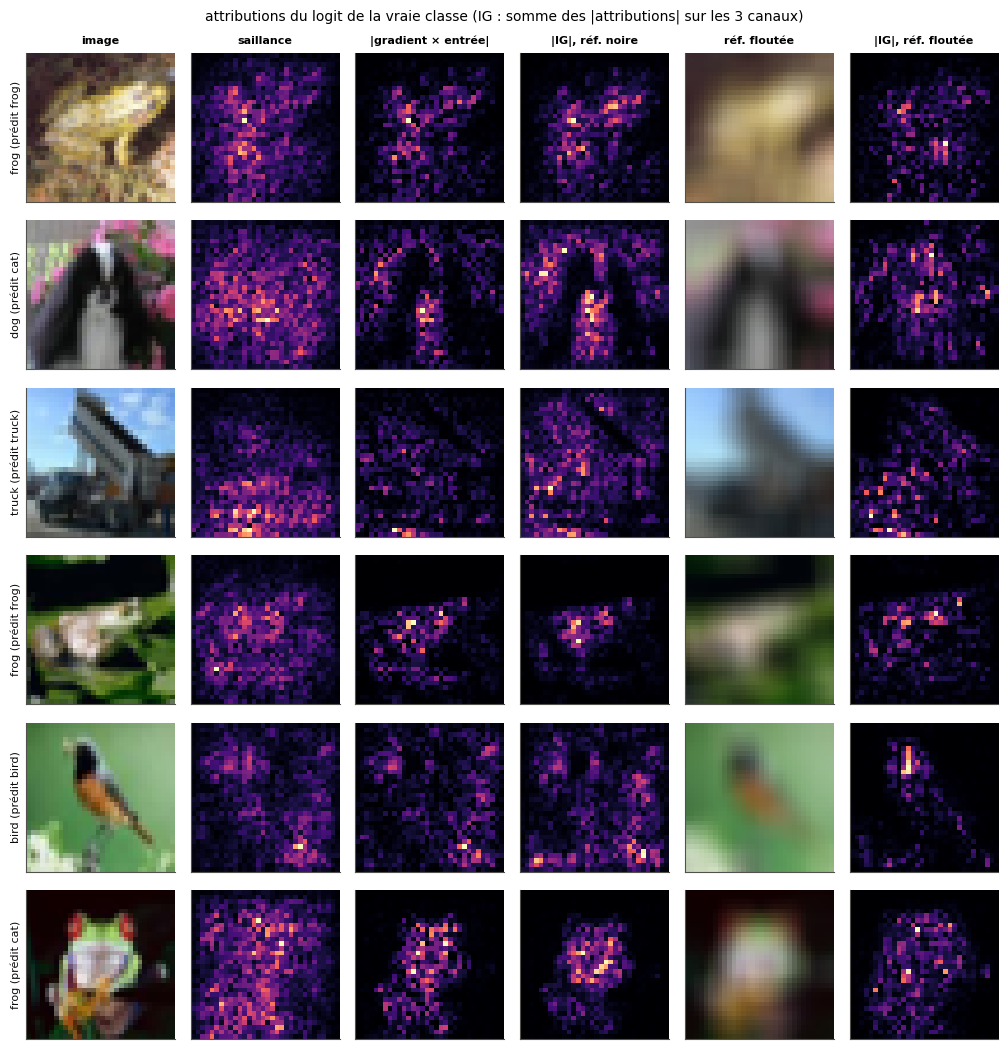

complétude (somme des attributions contre f(x) − f(x′), logit de la vraie classe) :
        frog : réf. noire 3,909 contre 3,957 ; réf. floutée 4,143 contre 4,146 ; somme de gradient × entrée -0,416
         dog : réf. noire 3,709 contre 3,739 ; réf. floutée 1,302 contre 1,319 ; somme de gradient × entrée 0,611
       truck : réf. noire 5,045 contre 5,025 ; réf. floutée 4,424 contre 4,423 ; somme de gradient × entrée 4,385
        frog : réf. noire 0,957 contre 0,959 ; réf. floutée 0,998 contre 0,994 ; somme de gradient × entrée -3,125
        bird : réf. noire 2,312 contre 2,317 ; réf. floutée 1,284 contre 1,292 ; somme de gradient × entrée -0,180
        frog : réf. noire 0,970 contre 1,014 ; réf. floutée 0,837 contre 0,822 ; somme de gradient × entrée -3,038
ℹ️ 1.5 s


In [44]:
if len(ok_19) == 4:
    start_19 = time.perf_counter()
    black_19, blur_19 = torch.zeros_like(IMAGES_19), blurred_19(IMAGES_19)
    grads_19 = class_gradient_19(CNN, IMAGES_19, LABELS_19)
    sal_19, gxi_19 = saliency_19(grads_19), grad_times_input_19(grads_19, IMAGES_19.numpy())
    ig_black_19 = np.stack([integrated_19(CNN, IMAGES_19[i].numpy(), int(LABELS_19[i]), black_19[i].numpy())
                            for i in range(6)])
    ig_blur_19 = np.stack([integrated_19(CNN, IMAGES_19[i].numpy(), int(LABELS_19[i]), blur_19[i].numpy())
                           for i in range(6)])
    rows_19 = []
    for i in range(6):
        rows_19.append([IMAGES_19[i].permute(1, 2, 0).numpy(), sal_19[i], np.abs(gxi_19[i]),
                        np.abs(ig_black_19[i]).sum(axis=0), blur_19[i].permute(1, 2, 0).numpy(),
                        np.abs(ig_blur_19[i]).sum(axis=0)])
    show_rows(rows_19, [f"{CLASSES[LABELS_19[i]]} (prédit {CLASSES[PRED_19[i]]})" for i in range(6)],
              ["image", "saillance", "|gradient × entrée|", "|IG|, réf. noire", "réf. floutée", "|IG|, réf. floutée"],
              [None, "magma", "magma", "magma", None, "magma"],
              suptitle="attributions du logit de la vraie classe (IG : somme des |attributions| sur les 3 canaux)")
    with torch.no_grad():
        logit_19 = lambda x: CNN(x).gather(1, torch.as_tensor(LABELS_19[:6])[:, None])[:, 0].double().numpy()
        f_x_19, f_black_19, f_blur_19 = logit_19(IMAGES_19[:6]), logit_19(black_19[:6]), logit_19(blur_19[:6])
    print("complétude (somme des attributions contre f(x) − f(x′), logit de la vraie classe) :")
    for i in range(6):
        print(f"  {CLASSES[LABELS_19[i]]:>10} : réf. noire {fr(ig_black_19[i].sum(), 3)} contre {fr(f_x_19[i] - f_black_19[i], 3)} ; "
              f"réf. floutée {fr(ig_blur_19[i].sum(), 3)} contre {fr(f_x_19[i] - f_blur_19[i], 3)} ; "
              f"somme de gradient × entrée {fr(gxi_19[i].sum(), 3)}")
    print(f"ℹ️ {time.perf_counter() - start_19:.1f} s")
else:
    print("⏳ Ex B6.19 : l'expérience attend tes quatre fonctions (cellule précédente).")

### Ex B6.20 — Grad-CAM par hooks sur le ResNet fine-tuné du B1 : bonnes prédictions et erreurs 📦 ★★★ ⏱️ 45 min
**Objectif :** extraire activations et gradients par deux hooks, construire les cartes Grad-CAM d'un ResNet et les lire sur des bonnes prédictions et des erreurs.  
**Prérequis :** Ex B6.18 · B1 (B1.17, B1.27) · fiche §206.6 (« Avec PyTorch : deux hooks ») · ch. 20 (hooks) · **Fil rouge :** CIFAR-10 · **Parcours :** R, C

Le modèle est **ton** ResNet-18 du B1 si tu l'as publié en B1.27 : `wbx.find_b1_folder()` cherche le dossier `resnet18_cifar10_b1` (avec `model.safetensors` et `config.json`) à côté de tes notebooks de `mon_travail/` ; sinon, ou si tu mets `B1_FOLDER = None`, c'est un ResNet-18 de référence, fine-tuné une fois par la recette de B1.17 (`layer4` et une nouvelle tête, 100 images par classe à 96 pixels, 3 epochs : ≈ 35 s sur CPU la première fois, puis relu du disque). La cellule de chargement dit lequel est utilisé. Le modèle est **gelé** (`requires_grad=False` partout) et en mode `eval()`, comme un backbone du B1 ; il attend des images préparées par `wbx.model_input` (agrandies à `SIZE_20` pixels, normalisées par les statistiques d'ImageNet), et `layer4` y est en `SIZE_20 // 32` × `SIZE_20 // 32` (3 × 3 à 96 pixels). La cellule de chargement choisit aussi, parmi 200 images de test, 8 bonnes prédictions et 8 erreurs (`X_20`, 16 images préparées).

**Contrat** :
- `activations_and_gradients_20(model, layer, images, target)` rend le couple `(A, G)` de tableaux NumPy `(N, C, H, W)` : `A`, la sortie du module `layer` pour le batch préparé `images`, et `G`, le gradient de la somme, sur les images, du logit de `target[n]` par rapport à `A` (une classe par image, pas forcément la prédite) ; deux hooks, l'un sur le module (passe avant), l'autre sur son tenseur de sortie ; le hook de passe avant ne rend rien, et il est retiré avant de rendre la main, même en cas d'erreur ;
- `cam_20(model, layer, images, target, size)` rend `(N, size, size)` : les cartes de **ta** `grad_cam` (ReLU et normalisation par défaut), agrandies par `F.interpolate(..., mode="bilinear", align_corners=False)`, la convention qui a agrandi les images.

La cellule de vérification compare `A`, `G` et les cartes à une référence (`wbx`) sur 4 images, dont une avec une autre classe que la vraie, et vérifie qu'aucun hook ne reste posé. L'expérience trace la carte de la classe prédite sur les 8 bonnes prédictions, puis, sur les 8 erreurs, celle de la classe prédite et celle de la vraie classe, et affiche la corrélation entre ces deux cartes.

Dans tes notes : sur les bonnes prédictions, la carte tombe-t-elle sur l'objet, sur le fond, sur un bord ? Sur les erreurs, les cartes de la classe prédite et de la vraie classe regardent-elles au même endroit, et qu'est-ce que cela suggère de l'erreur (un objet ambigu, un contexte trompeur) ? Que peut-on localiser avec une carte de 3 × 3 sur une image de 96 pixels ? Que verrais-tu avec `layer3`, et pourquoi Grad-CAM vise-t-il la dernière couche convolutive (🧠 Q8) ? Une carte qui « tombe sur l'objet » prouve-t-elle que le modèle a raison pour de bonnes raisons (206.7) ?

In [45]:
B1_FOLDER = None   # the solutions notebook never reads the learner's model: the reference ResNet


def activations_and_gradients_20(model, layer, images, target):
    """(A, G): np.ndarray (N, C, H, W) twice, the output A of `layer` (a module of model) for the prepared batch
    `images`, and the gradient G of the sum over the images of the logit of target[n] with respect to A; two hooks
    (one on the module, one on its output tensor), removed before returning."""
    store = {}

    def save(module, inputs, output):                 # returns None: the output is left unchanged
        store["A"] = output.detach()
        output.register_hook(lambda grad: store.__setitem__("G", grad.detach()))

    x = torch.as_tensor(images, dtype=torch.float32).clone().requires_grad_(True)   # frozen model: the input needs grad
    t = torch.as_tensor(np.asarray(target)).long().reshape(-1)
    handle = layer.register_forward_hook(save)
    try:
        scores = model(x)
        scores.gather(1, t[:, None]).sum().backward()
    finally:
        handle.remove()
    return store["A"].numpy(), store["G"].numpy()


def cam_20(model, layer, images, target, size):
    """(N, size, size): the Grad-CAM maps of your grad_cam (relu and normalize by default), resized to size x size by
    F.interpolate(..., mode="bilinear", align_corners=False)."""
    A, G = activations_and_gradients_20(model, layer, images, target)
    cams = torch.as_tensor(mylearn.explain.grad_cam(A, G), dtype=torch.float32)
    return F.interpolate(cams[:, None], size=(size, size), mode="bilinear", align_corners=False)[:, 0].numpy()

In [46]:
RESNET, RESNET_INFO = wbx.b1_resnet(FAST_MODE, folder=B1_FOLDER)   # frozen, in eval() mode
SIZE_20 = RESNET_INFO["size"]                                          # the side of its input images (96 in fast mode)
POOL_20 = X_CIFAR[:200], Y_CIFAR[:200]                                 # 200 test images (20 per class)
PRED_20 = wbx.predict(RESNET, POOL_20[0], RESNET_INFO).argmax(axis=1)
RIGHT_20 = np.flatnonzero(PRED_20 == POOL_20[1])[:8]                   # 8 well-classified images
WRONG_20 = np.flatnonzero(PRED_20 != POOL_20[1])[:8]                   # 8 errors
X_20 = wbx.model_input(POOL_20[0][np.concatenate([RIGHT_20, WRONG_20])], RESNET_INFO)   # (16, 3, SIZE_20, SIZE_20)
print(f"ResNet-18 ({RESNET_INFO['source']}) : {SIZE_20} pixels, layer4 en {SIZE_20 // 32} × {SIZE_20 // 32} ; accuracy sur "
      f"les 200 images : {pct(np.mean(PRED_20 == POOL_20[1]), 1)} ; 8 bonnes prédictions et 8 erreurs retenues.")

ℹ️ pas de modèle publié par Ex B1.27 : le ResNet-18 de référence (recette de B1.17) le remplace.
ℹ️ ResNet-18 de référence relu (b1_resnet-reference-76274080c1edb0a1.pt)


ResNet-18 (reference) : 96 pixels, layer4 en 3 × 3 ; accuracy sur les 200 images : 75,0 % ; 8 bonnes prédictions et 8 erreurs retenues.


In [47]:
ok_20 = {}
with checked("B6.20"):
    x_20 = X_20[[0, 1, 8, 9]]
    true_20 = POOL_20[1][np.concatenate([RIGHT_20, WRONG_20])][[0, 1, 8, 9]]
    t_20 = np.array([true_20[0], (true_20[1] + 1) % 10, true_20[2], true_20[3]])      # true classes, and one other
    A_ref_20, G_ref_20, _ = wbx.activations_and_gradients(RESNET, RESNET.layer4, x_20, t_20)
    try:
        got_20 = activations_and_gradients_20(RESNET, RESNET.layer4, x_20.clone(), t_20.copy())
    except RuntimeError as exc_20:
        if "require" in str(exc_20) and "grad" in str(exc_20):
            print("❌ Ex B6.20 : ton code lève RuntimeError : " + str(exc_20)[:160] + " ; les poids du modèle sont gelés "
                  "(requires_grad=False) : relis le dernier détail de « Avec PyTorch : deux hooks » (§206.6).")
            raise StopCheck
        raise
    A_20, G_20 = pair("B6.20", "activations_and_gradients_20", got_20, names=("A", "G"))
    if RESNET.layer4._forward_hooks:
        print("❌ Ex B6.20 : un hook reste posé sur layer4 après l'appel : retire-le (handle.remove(), dans un finally).")
        RESNET.layer4._forward_hooks.clear()
    if same("B6.20", "A : la sortie de layer4", A_20, A_ref_20, rtol=1e-5, atol=1e-6):
        ok_20["A"] = True
    if np.shape(G_20) == G_ref_20.shape and not np.allclose(np.asarray(G_20, dtype=float), G_ref_20, rtol=1e-4, atol=1e-7):
        pred_t_20 = wbx.predict(RESNET, x_20).argmax(axis=1)
        _, G_pred_20, _ = wbx.activations_and_gradients(RESNET, RESNET.layer4, x_20, pred_t_20)
        if np.allclose(np.asarray(G_20, dtype=float), G_pred_20, rtol=1e-4, atol=1e-7):
            print("❌ Ex B6.20 : G est le gradient de la classe prédite : le contrat veut celui de target[n] "
                  "(l'image 2 reçoit une autre classe).")
            raise StopCheck
    if same("B6.20", "G : le gradient du logit de target[n] par rapport à A", G_20, G_ref_20, rtol=1e-4, atol=1e-7):
        ok_20["G"] = True

with checked("B6.20"):
    if len(ok_20) < 2:
        raise StopCheck
    cams_20 = cam_20(RESNET, RESNET.layer4, x_20.clone(), t_20.copy(), SIZE_20)
    want_cam_20 = wbx.grad_cam(RESNET, RESNET.layer4, x_20, t_20, size=SIZE_20)
    arr_cam_20 = np.asarray(cams_20, dtype=float)
    if arr_cam_20.shape == want_cam_20.shape and not np.allclose(arr_cam_20, want_cam_20, rtol=1e-4, atol=1e-5):
        small_20 = torch.as_tensor(wbx.grad_cam(RESNET, RESNET.layer4, x_20, t_20))[:, None].float()
        corners_20 = F.interpolate(small_20, size=(SIZE_20, SIZE_20), mode="bilinear", align_corners=True)[:, 0].numpy()
        if np.allclose(arr_cam_20, corners_20, rtol=1e-4, atol=1e-5):
            print("❌ Ex B6.20 : la carte est agrandie avec align_corners=True : les images le sont avec "
                  "align_corners=False (wb.transfer.to_input) ; avec deux conventions, la carte est décalée sur l'image.")
            raise StopCheck
        if arr_cam_20.min() < -1e-9:
            print("❌ Ex B6.20 : la carte a des valeurs négatives : grad_cam garde-t-il sa ReLU (relu=True par défaut) ?")
            raise StopCheck
    if same("B6.20", f"cam_20 : cartes agrandies à {SIZE_20} × {SIZE_20}", arr_cam_20, want_cam_20, rtol=1e-4, atol=1e-5):
        ok_20["cam"] = True

✅ Ex B6.20 : A : la sortie de layer4 : un tableau (4, 512, 3, 3), comme attendu.
✅ Ex B6.20 : G : le gradient du logit de target[n] par rapport à A : un tableau (4, 512, 3, 3), comme attendu.


✅ Ex B6.20 : cam_20 : cartes agrandies à 96 × 96 : un tableau (4, 96, 96), comme attendu.


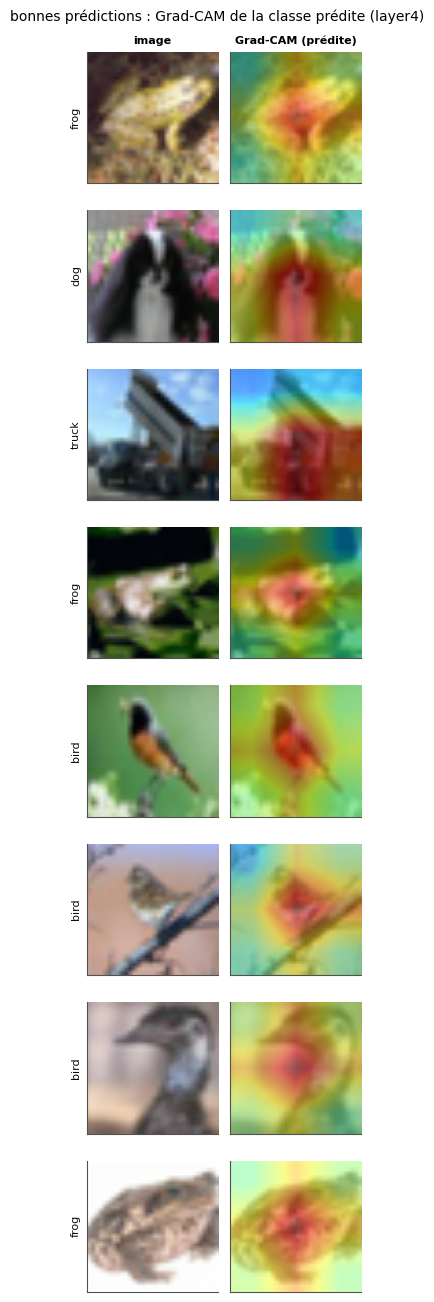

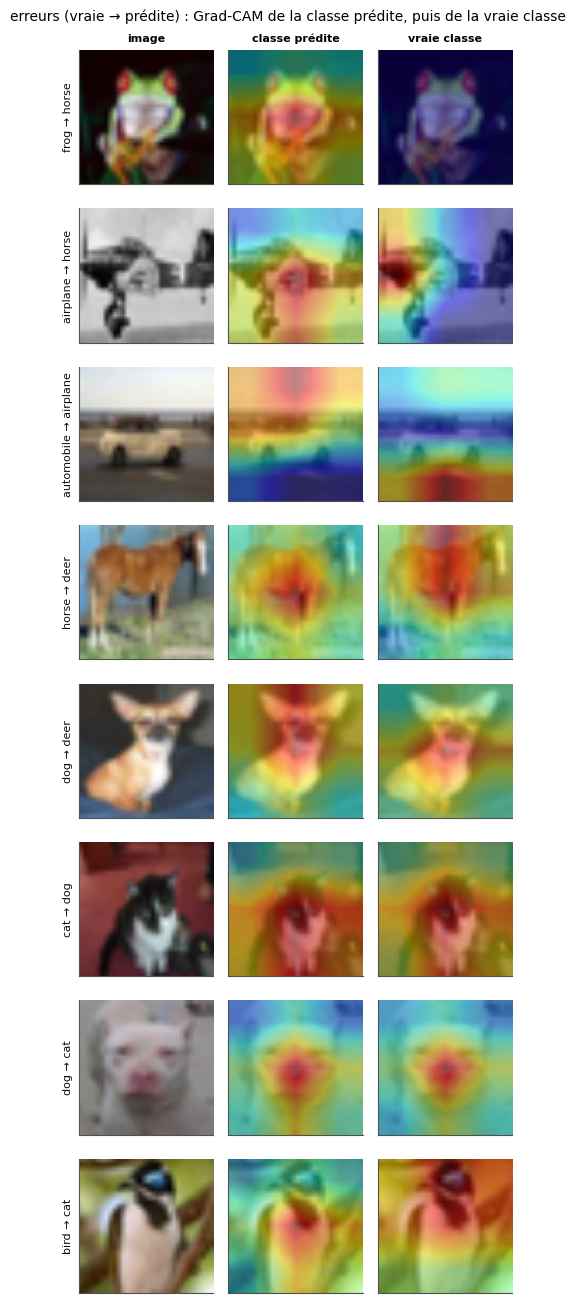

erreurs : corrélation entre la carte de la classe prédite et celle de la vraie classe : carte nulle, -0,23, -0,78, 0,59, 0,44, 0,96, 0,97, 0,05
cartes nulles (la ReLU a tout éteint) : frog (vraie classe)


In [48]:
if len(ok_20) == 3:
    labels_20 = POOL_20[1][np.concatenate([RIGHT_20, WRONG_20])]
    preds_20 = PRED_20[np.concatenate([RIGHT_20, WRONG_20])]
    cam_pred_20 = cam_20(RESNET, RESNET.layer4, X_20, preds_20, SIZE_20)        # the predicted class
    cam_true_20 = cam_20(RESNET, RESNET.layer4, X_20, labels_20, SIZE_20)       # the true class (the same when right)
    shown_20 = wbx.model_input(POOL_20[0][np.concatenate([RIGHT_20, WRONG_20])], {"size": SIZE_20, "mean": (0, 0, 0),
                                                                                  "std": (1, 1, 1)})
    pics_20 = shown_20.permute(0, 2, 3, 1).clamp(0, 1).numpy()                  # the images at SIZE_20 pixels, in [0, 1]

    def overlay_20(image, cam):
        heat = plt.cm.jet(cam)[..., :3]
        return np.clip(0.55 * image + 0.45 * heat, 0, 1)

    def corr_20(a, b):
        """The correlation of two maps, or None when one of them is constant (all zero after the ReLU)."""
        a, b = a.ravel(), b.ravel()
        return None if a.std() == 0 or b.std() == 0 else float(np.corrcoef(a, b)[0, 1])

    rows_20 = [[pics_20[i], overlay_20(pics_20[i], cam_pred_20[i])] for i in range(8)]
    show_rows(rows_20, [f"{CLASSES[labels_20[i]]}" for i in range(8)], ["image", "Grad-CAM (prédite)"],
              [None, None], size=1.6, suptitle="bonnes prédictions : Grad-CAM de la classe prédite (layer4)")
    rows_w_20 = [[pics_20[i], overlay_20(pics_20[i], cam_pred_20[i]), overlay_20(pics_20[i], cam_true_20[i])]
                 for i in range(8, 16)]
    show_rows(rows_w_20, [f"{CLASSES[labels_20[i]]} → {CLASSES[preds_20[i]]}" for i in range(8, 16)],
              ["image", "classe prédite", "vraie classe"], [None, None, None], size=1.6,
              suptitle="erreurs (vraie → prédite) : Grad-CAM de la classe prédite, puis de la vraie classe")
    same_20 = [corr_20(cam_pred_20[i], cam_true_20[i]) for i in range(8, 16)]
    print("erreurs : corrélation entre la carte de la classe prédite et celle de la vraie classe :",
          ", ".join("carte nulle" if v is None else fr(v, 2) for v in same_20))
    empty_20 = [f"{CLASSES[labels_20[i]]} ({which})" for i in range(16)
                for which, cams in (("classe prédite", cam_pred_20), ("vraie classe", cam_true_20)) if cams[i].max() == 0]
    if empty_20:
        print("cartes nulles (la ReLU a tout éteint) :", ", ".join(empty_20))
else:
    print("⏳ Ex B6.20 : l'expérience attend tes deux fonctions (cellules précédentes).")

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer à la main les valeurs de Shapley d'un petit jeu, avec un fond, et dire ce que le fond change ?
2. Sais-tu calculer des gradients intégrés et une carte Grad-CAM à la main, et vérifier la complétude ?
3. Sais-tu auditer un classifieur par groupe (taux de sélection, TPR, FPR, precision, écarts) et expliquer pourquoi tous les critères ne peuvent pas tenir ensemble ?
4. Sais-tu dire ce qu'un scoring de crédit implique au regard du RGPD et de l'AI Act ?

**Pour aller plus loin** : l'article de Lundberg et Lee et le livre en ligne de C. Molnar, cités dans la fiche. La suite : le bonus B7, le MLOps.

*Les exercices B6.21 à B6.29 (un Grad-CAM à réparer, le test de santé, l'équité) seront ajoutés à la prochaine session de génération ; relance alors `python tools/start_chapter.py B6` pour obtenir le notebook complet.*